# Part B: Deep Q-Network Control of Pendulum

I investigate whether one DQN design can learn reliable Pendulum control under `g = 10`, `0`, `-10` and `15`. Because DQN requires discrete actions, the first design question is how much torque resolution is useful before the larger output space becomes harder to learn.

I establish a default-gravity baseline and then test action resolution, exploration and target estimation through paired runs. Frequent gradient clipping motivates a separate reward-scaling experiment, while the checkpoint trend determines whether longer training is worth the extra interactions. The selected design is then trained under all four gravity settings. Final conclusions use held-out starts, all three training seeds, physical diagnostics and reloaded H5 policies. Failed and marginal experiments remain because they explain the final choice.


# 1. Background Research

## 1.1 Pendulum as a Control Problem

The agent must swing the pendulum upwards and keep it close to the upright position while avoiding unnecessarily fast movement and excessive torque.

- **State:** `[cos(theta), sin(theta), theta_dot]` describes orientation without an angular discontinuity and includes angular velocity.
- **Action:** one continuous torque value between `-2` and `2`.
- **Episode:** 200 interaction steps in `Pendulum-v0`.
- **Objective:** maximise accumulated reward. Since every reward is non-positive, a value closer to `0` is better.
- **Assigned investigation:** repeat the selected DQN design under four different values of gravity.

This is a sequential decision problem: a torque that gives little immediate improvement may still place the pendulum in a better state for later steps. Consequently, I must evaluate complete episodes rather than isolated actions.

**Sources:** [Gymnasium, Pendulum documentation](https://gymnasium.farama.org/environments/classic_control/pendulum/); [Sutton and Barto, Reinforcement Learning: An Introduction](http://incompleteideas.net/book/the-book-2nd.html).

## 1.2 Reward and What It Represents

For angle `theta`, angular velocity `theta_dot` and torque `u`, Pendulum applies the cost

`theta^2 + 0.1(theta_dot^2) + 0.001(u^2)`

and returns its negative as reward.

| Reward component | Interpretation | Limitation if used alone |
|---|---|---|
| Angle penalty | Main evidence that the pendulum is away from upright | Does not show whether it is moving too quickly |
| Angular-velocity penalty | Penalises uncontrolled spinning | A low value can also occur when the pendulum hangs still below upright |
| Torque penalty | Penalises control effort | Its coefficient is small, so low torque does not establish good control |
| Total episodic reward | Combines the three objectives exactly as the environment defines them | A mean can hide inconsistent episodes and the source of the cost |

I therefore use **mean greedy evaluation reward as the primary metric**, supported by reward spread and the three physical cost components. I do not invent a pass/fail reward threshold because the task does not define one.

**Source:** [Gymnasium, Pendulum reward definition](https://gymnasium.farama.org/environments/classic_control/pendulum/).


## 1.3 Why DQN Requires Action Discretisation

DQN estimates one Q-value for every available action and selects the action with the highest estimate. This requires a finite action set, whereas Pendulum accepts any torque in `[-2, 2]`.

I begin with five equally spaced actions:

`[-2, -1, 0, 1, 2]`

- Five actions include both torque limits, two intermediate corrections and exact zero torque.
- An odd, symmetric grid prevents a directional bias and guarantees that no-action is available.
- Fewer actions are easier for DQN to distinguish but may be too coarse near the upright position.
- More actions provide finer control but enlarge the output layer and divide experience across more choices.

Five actions serve only as the baseline; Section 6 tests whether a finer grid performs better under the same training budget.

Continuous-control algorithms such as DDPG, TD3 or SAC would avoid discretisation, but they are not used because this investigation specifically requires DQN. Double DQN is also kept out of the baseline so its target calculation can be tested later as one controlled change.

**Sources:** [Mnih et al. (2015), DQN](https://www.nature.com/articles/nature14236); [van Hasselt, Guez and Silver (2016), Double DQN](https://arxiv.org/abs/1509.06461).

## 1.4 DQN Framework

The baseline contains the mechanisms needed for a stable DQN implementation:

| Component | Purpose | Decision in this baseline |
|---|---|---|
| Online Q-network | Predict one Q-value per discrete torque | Two 64-unit ReLU layers and a linear five-value output |
| Replay memory | Break short-term correlation by sampling older transitions | Uniform buffer with a 1,000-step warm-up |
| Target network | Keep the Bellman target fixed between updates | Copy online weights every 500 environment steps |
| Epsilon-greedy policy | Retain exploration during training | Constant `epsilon = 0.10` as a simple initial reference |
| Bellman target | Connect immediate reward with estimated future return | `r + gamma max Q_target(s', a')` |
| Huber loss | Reduce the influence of occasional large temporal-difference errors | Used instead of unrestricted squared error |
| Gradient clipping | Prevent one update from producing an extreme parameter change | Global norm limited to `10` and clipping frequency recorded |

For transition `(s, a, r, s')`, the non-terminal Bellman target is

`y = r + gamma max Q_target(s', a')`

and the online network is updated from the difference between `y` and `Q_online(s, a)`. For a true terminal state, the future term is removed. A time-limit truncation is handled separately in Section 1.11.

The constant exploration rate is deliberately kept simple. A decaying schedule is a possible improvement, but changing it before the baseline would remove the reference needed to judge whether decay actually helps.

**Sources:** [Mnih et al. (2015), DQN](https://www.nature.com/articles/nature14236); [OpenAI Baselines: DQN](https://openai.com/index/openai-baselines-dqn/).

## 1.5 Experience Replay and the Target Network

Ordinary supervised learning assumes that examples can be treated as a stable dataset. DQN violates this in two ways: consecutive transitions are correlated, and its Bellman labels change as the network changes.

### 1.5.1 Replay Memory

Replay memory stores `(state, action index, reward, next state, terminal)` and samples old transitions in mixed minibatches.

- **Role:** reduces the dominance of the most recent trajectory and reuses each interaction more efficiently.
- **Warm-up:** avoids repeatedly fitting the narrow, highly correlated transitions from the opening steps.
- **Limitation:** uniform replay treats routine and informative transitions equally; it also contains experience from older policies.
- **Decision:** use uniform replay because it is the standard DQN baseline. Prioritised replay is not added before evidence that sampling is the limiting factor.

### 1.5.2 Target Network

The target network supplies the next-state Q-value in the Bellman label and is held fixed between synchronisations.

- **Role:** prevents one online-network update from changing both the prediction and its target at the same time.
- **Trade-off:** copying too often approaches the unstable moving-target case; copying too slowly makes targets stale.
- **Decision:** begin with a fixed 500-step hard update and hold it constant during the action-resolution experiment.
- **Limitation:** a target network improves optimisation stability but does not remove DQN's maximum-Q overestimation.

**Sources:** [Mnih et al. (2015), replay and target network](https://www.nature.com/articles/nature14236); [Schaul et al. (2016), Prioritized Experience Replay](https://arxiv.org/abs/1511.05952).

## 1.6 Exploration and Exploitation

An always-greedy agent can repeatedly choose actions favoured by inaccurate early Q-values and fail to discover a swing-up sequence. Epsilon-greedy exploration instead chooses a random discrete torque with probability `epsilon`.

| Strategy considered | Possible benefit | Main limitation | Baseline decision |
|---|---|---|---|
| Constant low epsilon | Simple and continues exploring throughout training | May explore too little early and too much after learning | **Use `0.10` as the reference** |
| Linear epsilon decay | Broad early coverage followed by more exploitation | Schedule length introduces another design choice | Consider only after baseline evidence |
| Exponential decay | Smooth multiplicative reduction | Harder to interpret and compare by episode | Not used initially |
| Noisy networks / parameter noise | State-dependent exploration | Adds architecture and a different source of stochasticity | Outside the baseline scope |

Training return is expected to be lower than greedy evaluation return because exploratory actions remain active. For this reason, I do not select a checkpoint from training reward alone.

**Source:** [OpenAI Baselines: DQN](https://openai.com/index/openai-baselines-dqn/).

## 1.7 Network and Optimisation Choices

The observation contains only three values, so a convolutional or recurrent network would add structure that the input does not possess. A compact multilayer perceptron is sufficient to learn a nonlinear relationship between orientation, velocity and torque value.

- **Two hidden layers:** allow interactions such as the preferred torque changing with both angle and angular velocity.
- **64 units per layer:** enough capacity for a low-dimensional control surface without making network size the first experimental variable.
- **ReLU hidden activations:** avoid saturating hidden units over the normalised state range.
- **Linear output:** Q-values are unrestricted accumulated-return estimates, so a bounded output activation would be inappropriate.
- **Adam at `5e-4`:** a cautious starting update size for bootstrapped targets.
- **Huber loss:** behaves quadratically for small temporal-difference errors and linearly for large ones, reducing the influence of extreme early errors.
- **Global gradient clipping:** limits an extreme update but is logged because a safeguard being present does not prove that it was needed.

Alternatives such as deeper networks, wider layers and different learning rates remain valid later candidates. Testing them all immediately would create a search catalogue rather than a causal investigation, so they are not changed until the baseline reveals a relevant weakness.

**Sources:** [Kingma and Ba, Adam](https://arxiv.org/abs/1412.6980); [OpenAI Baselines: DQN](https://openai.com/index/openai-baselines-dqn/).

## 1.8 Evaluation of a Pendulum Agent

A Pendulum episode depends strongly on its initial angle and velocity. Training reward also includes exploratory actions, so it is not an unbiased measure of the deployed greedy policy. I therefore use several forms of evidence with different roles.

| Evidence | Role in this investigation | Limitation |
|---|---|---|
| Mean greedy episodic reward | **Primary model-comparison metric** because it is the environment objective | Can hide difficult starts |
| Median, spread, best and worst reward | Shows reliability and weak cases | Three training seeds do not support strong inferential claims |
| Training and checkpoint curves | Reveals learning, regressions and checkpoint timing | Training reward contains exploration |
| Reward decomposition | Separates angle, angular-velocity and torque costs | Does not show their temporal order |
| Angle, velocity and torque traces | Explains swing-up, settling and control chatter | One trajectory is not population evidence |
| Action use and policy maps | Examines how the discrete controller uses torque choices | Hypothetical grid states may be rarely visited |
| Fixed-seed animations | Verifies visible behaviour | Never used to select the model |
| Parameters, interactions and runtime | Supports complexity trade-offs | Does not measure policy quality |

I do not invent a reward threshold because the environment and brief do not define one. I also keep TD loss as an optimisation diagnostic rather than a performance metric: fitting Bellman targets more closely does not necessarily produce better control.

**Sources:** [Henderson et al. (2018), Deep Reinforcement Learning that Matters](https://ojs.aaai.org/index.php/AAAI/article/view/11694); [Stable-Baselines3, RL evaluation guidance](https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html).

### 1.8.1 How Model Decisions Are Made

The primary comparison is greedy episodic reward on the same validation starts. A candidate may advance for further testing when its three-seed mean improves and at least two paired seeds improve. Final selection also considers between-seed spread, physical behaviour and any added parameters or interactions. This allows a small promising result to be investigated without automatically declaring it the final model.

Checkpoint-selection starts choose weights within a run. Separate comparison-validation starts judge experiments. Held-out final-test starts are used once the design is fixed. This separation prevents the final test from becoming another tuning set.


## 1.9 Gravity-Specific Considerations

Gravity changes the transition dynamics rather than the observation or action dimensions.

| Setting | Expected control difference | Experimental risk |
|---|---|---|
| `g = 10` | Standard swing-up and balance problem | Used as the design baseline |
| `g = 0` | No gravitational pull towards the downward position | Low movement can be mistaken for good control if angle is ignored |
| `g = -10` | Gravity acts in the reversed direction | A strategy learned under normal gravity may be inappropriate |
| `g = 15` | Stronger downward acceleration | Coarse torque choices or short exploration may become more limiting |

I train the selected configuration separately under each gravity. This answers how DQN learning behaves under the four assigned physics settings without mixing it with a second transfer-learning question. Retuning only the difficult gravity after seeing its final result would make the comparison unfair.

**Source:** [Gymnasium, Pendulum dynamics and gravity parameter](https://gymnasium.farama.org/environments/classic_control/pendulum/).


## 1.10 Alternatives Considered but Not Added to the Baseline

| Alternative | Why it is relevant | Why it is deferred or rejected here |
|---|---|---|
| More action bins | Can provide finer torque corrections | Must be a controlled experiment against five actions |
| Epsilon decay | Can improve early exploration and late exploitation | Changing it now would remove the constant-epsilon reference |
| Longer training | Can help a slowly improving policy | Is justified only if the baseline is still improving near episode 150 |
| Larger/deeper network | Can increase representational capacity | State dimension is small; capacity should not be assumed to be the bottleneck |
| Prioritised replay | Focuses updates on high-error transitions | Adds sampling bias correction and complexity before a replay weakness is shown |
| Double DQN | Reduces maximum-Q overestimation | Requires Q-value evidence or a later controlled comparison |
| Dueling DQN | Separates state value and action advantage | Extra architecture is not needed to establish a correct baseline |
| DDPG, TD3 or SAC | Natively handle continuous torque | Rejected as the main method because the task requires DQN |

These options remain documented, but only changes supported by the baseline evidence enter the experiment sequence.

**Sources:** [van Hasselt et al. (2016), Double DQN](https://arxiv.org/abs/1509.06461); [Wang et al. (2016), Dueling DQN](https://arxiv.org/abs/1511.06581); [Lillicrap et al. (2016), DDPG](https://arxiv.org/abs/1509.02971); [Haarnoja et al. (2018), SAC](https://arxiv.org/abs/1801.01290).


## 1.11 Evaluation and Reproducibility Risks

Network initialisation, exploration, replay sampling and reset states all introduce variation. I use three independent training seeds (`17`, `42`, `73`) and retain every result.

Two development sets have separate jobs:

- ten **checkpoint-selection starts** choose the saved weight within each run;
- twenty **comparison-validation starts** compare the saved models and drive experiment decisions.

Twenty held-out final-test starts are declared before training and used only after the design is selected. Validation transitions never enter replay memory, and all paired candidates receive the same interaction budget.

`Pendulum-v0` normally ends at its 200-step time limit rather than at a physical terminal state. The Bellman target therefore continues bootstrapping when `info["TimeLimit.truncated"]` is true.

**Sources:** [Pardo et al. (2018), Time Limits in Reinforcement Learning](https://arxiv.org/abs/1712.00378); [Henderson et al. (2018), repeated-run reporting](https://ojs.aaai.org/index.php/AAAI/article/view/11694); [TensorFlow, deterministic operations](https://www.tensorflow.org/api_docs/python/tf/config/experimental/enable_op_determinism).


## 1.12 Investigation Plan

1. Establish a five-action default-gravity DQN baseline.
2. Screen and confirm action resolution under matched settings.
3. Test an exploration strategy and Double-DQN target separately.
4. Recheck `5` versus `11` actions after those experiments.
5. Extend training only if the checkpoint trend still improves near episode 150.
6. Use one selected design for the four assigned gravity settings.
7. Evaluate the four agents on held-out starts, inspect their behaviour and verify the exported H5 weights.

Failed, marginal and contradictory results remain part of the analysis.


# 2. Environment Investigation

## 2.1 Setup

I use Gym `0.17.3` because the supplied Pendulum code uses this API. The cell below records the package versions and available hardware. `MASTER_SEED` is used for these setup checks; the independent training seeds are declared in Section 3.


In [1]:
from pathlib import Path
import json
import sys
import random
import time
import base64
from collections import deque
from html import escape

import gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import HTML, display
from PIL import Image as PILImage
from tensorflow import keras

tf.get_logger().setLevel("ERROR")

MASTER_SEED = 42
random.seed(MASTER_SEED)
np.random.seed(MASTER_SEED)
tf.keras.utils.set_random_seed(MASTER_SEED)
tf.config.experimental.enable_op_determinism()

OUTPUT_DIR = Path("part_b_outputs")
WEIGHTS_DIR = OUTPUT_DIR / "weights"
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR = OUTPUT_DIR / "figures"
ANIMATIONS_DIR = OUTPUT_DIR / "animations"
for directory in (WEIGHTS_DIR, TABLES_DIR, FIGURES_DIR, ANIMATIONS_DIR):
    directory.mkdir(parents=True, exist_ok=True)


def display_gif(path, alt_text):
    encoded_gif = base64.b64encode(Path(path).read_bytes()).decode("ascii")
    display(HTML(
        f'<img src="data:image/gif;base64,{encoded_gif}" '
        f'alt="{escape(alt_text)}" style="max-width:420px;height:auto;">'
    ))

available_gpus = tf.config.list_physical_devices("GPU")
print("Python:", sys.version.split()[0])
print("Gym:", gym.__version__)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("NumPy:", np.__version__)
print("Available GPU:", available_gpus)

Python: 3.13.14
Gym: 0.17.3
TensorFlow: 2.21.0
Keras: 3.15.0
NumPy: 2.5.1
Available GPU: []


### Setup Result

This run used Python `3.13.14`, Gym `0.17.3`, TensorFlow `2.21.0`, Keras `3.15.0` and NumPy `2.5.1`. TensorFlow detected no GPU, so the recorded Part B runtimes are CPU runtimes. Every candidate was trained in the same software and hardware environment.

## 2.2 Four Gravity Settings

Before training, I compare the requested gravity with the value stored by each environment and confirm that the observation and action spaces are unchanged.


In [2]:
GRAVITY_SETTINGS = {
    "Default gravity": 10.0,
    "Zero gravity": 0.0,
    "Anti-gravity": -10.0,
    "Stronger gravity": 15.0,
}

environment_rows = []
for setting, gravity in GRAVITY_SETTINGS.items():
    env = gym.make("Pendulum-v0", g=gravity)
    env.seed(MASTER_SEED)
    initial_state = env.reset()
    actual_gravity = float(env.unwrapped.g)
    assert np.isclose(actual_gravity, gravity)
    environment_rows.append({
        "Setting": setting,
        "Requested gravity": gravity,
        "Actual gravity": actual_gravity,
        "Observation shape": env.observation_space.shape,
        "Action shape": env.action_space.shape,
        "Action minimum": float(env.action_space.low[0]),
        "Action maximum": float(env.action_space.high[0]),
        "Initial state shape": initial_state.shape,
    })
    env.close()

environment_df = pd.DataFrame(environment_rows)
display(environment_df)

            Setting  Requested gravity  Actual gravity Observation shape  \
0   Default gravity               10.0            10.0              (3,)   
1      Zero gravity                0.0             0.0              (3,)   
2      Anti-gravity              -10.0           -10.0              (3,)   
3  Stronger gravity               15.0            15.0              (3,)   

  Action shape  Action minimum  Action maximum Initial state shape  
0         (1,)            -2.0             2.0                (3,)  
1         (1,)            -2.0             2.0                (3,)  
2         (1,)            -2.0             2.0                (3,)  
3         (1,)            -2.0             2.0                (3,)  

### Environment Result

Requested and actual gravity agree in all four rows. Each environment has a three-value observation and a single torque input bounded by `[-2, 2]`; gravity is the only structural difference. I can therefore keep the network and interaction budget fixed in the later gravity comparison.

## 2.3 State Range and Starting States

`cos(theta)` and `sin(theta)` are bounded by `[-1, 1]`, while angular velocity is bounded by `[-8, 8]`. I sample 1,000 seeded resets to check that evaluation is not restricted to one starting pose before deciding how the state enters the network.


In [3]:
env = gym.make("Pendulum-v0", g=10.0)
env.seed(MASTER_SEED)

state_limits = pd.DataFrame({
    "State feature": ["cos(theta)", "sin(theta)", "theta_dot"],
    "Minimum": env.observation_space.low,
    "Maximum": env.observation_space.high,
})

initial_states = np.asarray([env.reset() for _ in range(1_000)], dtype=np.float32)
initial_angles = np.arctan2(initial_states[:, 1], initial_states[:, 0])
initial_summary = pd.DataFrame({
    "Quantity": ["theta (rad)", "theta_dot (rad/s)"],
    "Observed minimum": [initial_angles.min(), initial_states[:, 2].min()],
    "Observed maximum": [initial_angles.max(), initial_states[:, 2].max()],
    "Observed mean": [initial_angles.mean(), initial_states[:, 2].mean()],
})

env.seed(MASTER_SEED)
first_reset = env.reset()
env.seed(MASTER_SEED)
repeated_reset = env.reset()
assert np.allclose(first_reset, repeated_reset)

display(state_limits)
display(initial_summary.round(4))
print("Same seed reproduces initial observation:", np.allclose(first_reset, repeated_reset))
env.close()

  State feature  Minimum  Maximum
0    cos(theta)     -1.0      1.0
1    sin(theta)     -1.0      1.0
2     theta_dot     -8.0      8.0

            Quantity  Observed minimum  Observed maximum  Observed mean
0        theta (rad)           -3.1302            3.1233         0.0319
1  theta_dot (rad/s)           -0.9913            0.9990        -0.0157

Same seed reproduces initial observation: True


### State Result

The reset sample contains positive and negative angles and angular velocities, and reseeding reproduces the first observation exactly. The environment already returns complete numeric states, so there are no missing rows to remove or values to impute. The only preparation needed is scale alignment, addressed in Section 3.

## 2.4 Reward and Time Limit

I recalculate one reward from the environment state and check why a 200-step episode ends. These checks determine how reward is interpreted and whether the Bellman target should bootstrap at the time limit.


In [4]:
def angle_normalize(angle):
    return ((angle + np.pi) % (2 * np.pi)) - np.pi


reward_env = gym.make("Pendulum-v0", g=10.0)
reward_env.seed(MASTER_SEED)
reward_env.reset()
theta_before, theta_dot_before = reward_env.unwrapped.state.copy()
audit_torque = 1.25
_, observed_reward, _, _ = reward_env.step(np.array([audit_torque], dtype=np.float32))
expected_reward = -(
    angle_normalize(theta_before) ** 2
    + 0.1 * theta_dot_before ** 2
    + 0.001 * audit_torque ** 2
)
assert np.isclose(observed_reward, expected_reward, atol=1e-6)
reward_env.close()

limit_env = gym.make("Pendulum-v0", g=10.0)
limit_env.seed(MASTER_SEED)
limit_env.reset()
for step_number in range(1, 201):
    _, _, done, final_info = limit_env.step(np.array([0.0], dtype=np.float32))
    if done:
        break
limit_env.close()

assert step_number == 200
assert done
assert final_info.get("TimeLimit.truncated", False)

audit_results = pd.DataFrame({
    "Check": ["Calculated reward", "Environment reward", "Episode length", "Time-limit truncation"],
    "Result": [
        expected_reward,
        observed_reward,
        step_number,
        final_info.get("TimeLimit.truncated", False),
    ],
})
display(audit_results)

                   Check    Result
0      Calculated reward -0.626994
1     Environment reward -0.626994
2         Episode length       200
3  Time-limit truncation      True

### Reward and Time-Limit Result

The independently calculated reward matches the environment reward. At step 200, `done` is caused by `TimeLimit.truncated`, not by a physical terminal state. The replay transition therefore keeps the future-value term for this case; only a true terminal state removes it.


# 3. Default DQN Baseline Design

## 3.1 State Preparation and Action Mapping

I keep `cos(theta)` and `sin(theta)` unchanged because both already lie in `[-1, 1]`. I divide `theta_dot` by its known bound of `8`, bringing all three network inputs onto a comparable scale without estimating statistics from validation episodes.

I do not reconstruct `theta` as another input. The sine/cosine pair already represents orientation continuously; an added raw angle would be redundant and would reintroduce a discontinuity at `-pi` and `pi`.

Each network output index maps directly to one entry of the torque array. I do not use separate index-to-torque and torque-to-index formulae because inconsistent denominators can silently store a different action from the one applied.

In [5]:
ACTION_VALUES = np.linspace(-2.0, 2.0, 5, dtype=np.float32)


def prepare_state(state):
    prepared = np.asarray(state, dtype=np.float32).copy()
    prepared[2] /= 8.0
    return prepared


assert np.allclose(ACTION_VALUES, [-2.0, -1.0, 0.0, 1.0, 2.0])
assert np.allclose(ACTION_VALUES, -ACTION_VALUES[::-1])
assert ACTION_VALUES[len(ACTION_VALUES) // 2] == 0.0

state_example = np.array([0.6, -0.8, 4.0], dtype=np.float32)
prepared_example = prepare_state(state_example)
assert np.allclose(prepared_example, [0.6, -0.8, 0.5])

pd.DataFrame({"Action index": np.arange(len(ACTION_VALUES)), "Applied torque": ACTION_VALUES})

   Action index  Applied torque
0             0            -2.0
1             1            -1.0
2             2             0.0
3             3             1.0
4             4             2.0

The displayed mapping is symmetric: index `2` applies zero torque, while the outer indices apply `-2` and `2`. The same array is used both to act in the environment and to interpret the network output.

## 3.2 Evaluation Seeds

The seed lists are fixed before training:

- **Training seeds** independently change network initialisation, exploratory actions, replay samples and training reset sequences.
- **Checkpoint-selection seeds** choose the best saved weight within each training run.
- **Comparison-validation seeds** compare completed experiments on a broader, separate set of starts.
- **Final-test seeds** remain untouched until every hyperparameter and gravity model has been selected.

Checkpoint selection and experiment comparison therefore use different starts. The comparison set still supports several sequential decisions, so a separate held-out set is retained for the final report.


In [6]:
TRAINING_SEEDS = [17, 42, 73]
CHECKPOINT_SELECTION_SEEDS = list(range(10_000, 10_010))
COMPARISON_VALIDATION_SEEDS = list(range(11_000, 11_020))
FINAL_TEST_SEEDS = list(range(20_000, 20_020))
ANIMATION_TRAINING_SEED = 42
ANIMATION_EVALUATION_SEED = CHECKPOINT_SELECTION_SEEDS[3]

seed_groups = [
    set(TRAINING_SEEDS),
    set(CHECKPOINT_SELECTION_SEEDS),
    set(COMPARISON_VALIDATION_SEEDS),
    set(FINAL_TEST_SEEDS),
]
assert all(
    seed_groups[left].isdisjoint(seed_groups[right])
    for left in range(len(seed_groups))
    for right in range(left + 1, len(seed_groups))
)

seed_protocol = pd.DataFrame({
    "Role": [
        "Independent training",
        "Checkpoint selection",
        "Comparison validation",
        "Fixed animation monitor",
        "Held-out final test",
    ],
    "Seeds": [
        str(TRAINING_SEEDS),
        str(CHECKPOINT_SELECTION_SEEDS),
        str(COMPARISON_VALIDATION_SEEDS),
        str([ANIMATION_EVALUATION_SEED]),
        str(FINAL_TEST_SEEDS),
    ],
    "Purpose": [
        "Independent complete training runs",
        "Choose the saved checkpoint within a run",
        "Compare saved candidate models",
        "Display only; never select a model",
        "One evaluation after the design is selected",
    ],
})
display(seed_protocol)

                      Role                                              Seeds  \
0     Independent training                                       [17, 42, 73]   
1     Checkpoint selection  [10000, 10001, 10002, 10003, 10004, 10005, 100...   
2    Comparison validation  [11000, 11001, 11002, 11003, 11004, 11005, 110...   
3  Fixed animation monitor                                            [10003]   
4      Held-out final test  [20000, 20001, 20002, 20003, 20004, 20005, 200...   

                                       Purpose  
0           Independent complete training runs  
1     Choose the saved checkpoint within a run  
2               Compare saved candidate models  
3           Display only; never select a model  
4  One evaluation after the design is selected  

The table confirms that the training, checkpoint, comparison and final-test seed groups are disjoint. The animation reuses one declared checkpoint-selection start; displaying that fixed episode does not add another model-selection criterion.

## 3.3 Architecture and Training Decisions

| Decision | Baseline value | Reason |
|---|---:|---|
| Hidden layers | `64 -> 64`, ReLU | Nonlinear capacity for a three-value state without making network size the first variable |
| Output | 5 linear Q-values | One unrestricted return estimate for each baseline torque |
| Episodes | `150` | A fixed 30,000-interaction starting budget before any duration extension |
| Discount | `0.99` | Swing-up actions must retain influence through later balancing states |
| Learning rate | `5e-4` Adam | Cautious update size for bootstrapped targets |
| Reward scale | `1.0` | Keeps Bellman targets on the environment's original scale until training evidence justifies an ablation |
| Replay | 50,000 capacity; 1,000-step warm-up | Mixes transitions and avoids fitting the narrow opening sequence |
| Batch size | `64` | Mixed samples at low cost for the small network |
| Exploration | constant `0.10` | Simple reference for a later schedule comparison |
| Target copy | every `500` steps | Holds targets fixed across several updates without a long delay |
| Loss | Huber | Limits the influence of very large early TD errors |
| Gradient norm | clip at `10` and record activation | Safety measure; it receives no performance credit without an ablation |
| Checkpoint evaluation | 10 greedy episodes every 25 training episodes | Selects weights without using exploratory training reward |
| Experiment comparison | 20 separate greedy episodes | Broader evidence that is not reused for checkpoint selection |
| Animation | Episodes 50, 100 and 150 for training seed 42 | Fixed progression rather than visually selected examples |

Every seed receives the same budget; no early stopping is used.


In [7]:
BASELINE_CONFIG = {
    "experiment_id": "Default_DQN",
    "model_name": "Default DQN baseline",
    "gravity_label": "Default gravity",
    "gravity": 10.0,
    "n_actions": 5,
    "hidden_units": [64, 64],
    "episodes": 150,
    "max_steps": 200,
    "gamma": 0.99,
    "learning_rate": 5e-4,
    "reward_scale": 1.0,
    "batch_size": 64,
    "replay_capacity": 50_000,
    "warmup_steps": 1_000,
    "epsilon_schedule": "constant",
    "epsilon_start": 0.10,
    "epsilon_end": 0.10,
    "epsilon_decay_steps": 1,
    "target_method": "dqn",
    "target_update_steps": 500,
    "gradient_clip_norm": 10.0,
    "evaluation_interval": 25,
    "animation_interval": 50,
    "save_progression": True,
    "checkpoint_evaluation_episodes": len(CHECKPOINT_SELECTION_SEEDS),
    "comparison_evaluation_episodes": len(COMPARISON_VALIDATION_SEEDS),
}

with open(TABLES_DIR / "default_dqn_baseline_config.json", "w", encoding="utf-8") as file:
    json.dump(BASELINE_CONFIG, file, indent=2)

pd.DataFrame({"Setting": BASELINE_CONFIG.keys(), "Value": BASELINE_CONFIG.values()})

                           Setting                 Value
0                    experiment_id           Default_DQN
1                       model_name  Default DQN baseline
2                    gravity_label       Default gravity
3                          gravity                  10.0
4                        n_actions                     5
5                     hidden_units              [64, 64]
6                         episodes                   150
7                        max_steps                   200
8                            gamma                  0.99
9                    learning_rate                0.0005
10                    reward_scale                   1.0
11                      batch_size                    64
12                 replay_capacity                 50000
13                    warmup_steps                  1000
14                epsilon_schedule              constant
15                   epsilon_start                   0.1
16                     epsilon_

The configuration table records the complete baseline before training. Later candidates copy it and change only the variable named in their experiment section.

## 3.4 Baseline Question

**Question:** Can a five-action DQN learn a repeatable default-gravity policy that clearly exceeds non-learning controls?

I judge the baseline from all three training seeds, the learning curves and the matched random and zero-torque references. Reward decomposition and trajectories explain any remaining control error. Reloading the saved H5 weights must reproduce the selected checkpoint.


# 4. DQN Implementation Checks

## 4.1 Network, Replay and Evaluation Functions

Every experiment uses the same training and evaluation functions. Evaluation creates a separate environment, always takes the greedy action, and never writes to replay memory or updates the network.


In [8]:
def set_experiment_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


def build_q_network(n_actions=5, hidden_units=(64, 64)):
    inputs = keras.Input(shape=(3,), name="state")
    x = keras.layers.Dense(hidden_units[0], activation="relu", name="hidden_1")(inputs)
    x = keras.layers.Dense(hidden_units[1], activation="relu", name="hidden_2")(x)
    outputs = keras.layers.Dense(n_actions, activation="linear", name="q_values")(x)
    return keras.Model(inputs, outputs, name="pendulum_dqn")


def bellman_targets(rewards, next_max_q, terminals, gamma):
    return rewards + gamma * (1.0 - terminals) * next_max_q


def create_train_step(online_network, target_network, optimizer, config):
    huber = keras.losses.Huber(reduction="none")
    n_actions = config["n_actions"]
    gamma = config["gamma"]
    clip_norm = config["gradient_clip_norm"]
    target_method = config["target_method"]

    @tf.function
    def train_step(states, actions, rewards, next_states, terminals):
        target_q_values = target_network(next_states, training=False)
        if target_method == "double_dqn":
            online_next_q_values = online_network(next_states, training=False)
            next_actions = tf.argmax(online_next_q_values, axis=1, output_type=tf.int32)
            next_max_q = tf.reduce_sum(
                target_q_values * tf.one_hot(next_actions, n_actions), axis=1
            )
        else:
            next_max_q = tf.reduce_max(target_q_values, axis=1)

        targets = rewards + gamma * (1.0 - terminals) * next_max_q

        with tf.GradientTape() as tape:
            all_q_values = online_network(states, training=True)
            selected_q_values = tf.reduce_sum(
                all_q_values * tf.one_hot(actions, n_actions), axis=1
            )
            losses = huber(targets[:, None], selected_q_values[:, None])
            loss = tf.reduce_mean(losses)

        gradients = tape.gradient(loss, online_network.trainable_variables)
        clipped_gradients, gradient_norm = tf.clip_by_global_norm(gradients, clip_norm)
        optimizer.apply_gradients(zip(clipped_gradients, online_network.trainable_variables))
        was_clipped = tf.cast(gradient_norm > clip_norm, tf.float32)
        return loss, gradient_norm, was_clipped

    return train_step


def epsilon_at_step(config, environment_step):
    if config["epsilon_schedule"] == "constant":
        return config["epsilon_start"]

    progress = min(environment_step / config["epsilon_decay_steps"], 1.0)
    return config["epsilon_start"] + progress * (
        config["epsilon_end"] - config["epsilon_start"]
    )


def evaluate_dqn(model, gravity, action_values, episode_seeds, max_steps=200):
    episode_rows = []
    trace_rows = []

    for evaluation_seed in episode_seeds:
        env = gym.make("Pendulum-v0", g=gravity)
        env.seed(evaluation_seed)
        state = env.reset()
        total_reward = 0.0
        angle_penalty = 0.0
        velocity_penalty = 0.0
        torque_penalty = 0.0
        stable_steps = 0

        for step in range(max_steps):
            theta = float(np.arctan2(state[1], state[0]))
            theta_dot = float(state[2])
            q_values = model(prepare_state(state)[None, :], training=False).numpy()[0]
            action_id = int(np.argmax(q_values))
            torque = float(action_values[action_id])

            next_state, reward, done, info = env.step(
                np.array([torque], dtype=np.float32)
            )

            step_angle_penalty = theta ** 2
            step_velocity_penalty = 0.1 * theta_dot ** 2
            step_torque_penalty = 0.001 * torque ** 2
            is_stable = abs(theta) <= np.deg2rad(15) and abs(theta_dot) <= 1.0

            total_reward += reward
            angle_penalty += step_angle_penalty
            velocity_penalty += step_velocity_penalty
            torque_penalty += step_torque_penalty
            stable_steps += int(is_stable)

            trace_rows.append({
                "evaluation_seed": evaluation_seed,
                "step": step,
                "theta_degrees": np.rad2deg(theta),
                "theta_dot": theta_dot,
                "action_id": action_id,
                "torque": torque,
                "reward": reward,
                "stable": is_stable,
            })

            state = next_state
            if done:
                break

        env.close()
        episode_rows.append({
            "evaluation_seed": evaluation_seed,
            "episode_reward": total_reward,
            "angle_penalty": angle_penalty,
            "velocity_penalty": velocity_penalty,
            "torque_penalty": torque_penalty,
            "mean_abs_angle_degrees": np.mean(
                np.abs([
                    row["theta_degrees"]
                    for row in trace_rows
                    if row["evaluation_seed"] == evaluation_seed
                ])
            ),
            "rms_angular_velocity": np.sqrt(
                np.mean(np.square([
                    row["theta_dot"]
                    for row in trace_rows
                    if row["evaluation_seed"] == evaluation_seed
                ]))
            ),
            "mean_abs_torque": np.mean(
                np.abs([
                    row["torque"]
                    for row in trace_rows
                    if row["evaluation_seed"] == evaluation_seed
                ])
            ),
            "upright_stable_fraction": stable_steps / (step + 1),
            "steps": step + 1,
        })

    return pd.DataFrame(episode_rows), pd.DataFrame(trace_rows)


def evaluate_reference_policy(policy_name, gravity, action_values, episode_seeds, max_steps=200):
    rows = []
    centre_action = len(action_values) // 2

    for evaluation_seed in episode_seeds:
        env = gym.make("Pendulum-v0", g=gravity)
        env.seed(evaluation_seed)
        state = env.reset()
        action_rng = np.random.default_rng(evaluation_seed)
        total_reward = 0.0

        for step in range(max_steps):
            if policy_name == "Random discrete policy":
                action_id = int(action_rng.integers(len(action_values)))
            elif policy_name == "Zero-torque policy":
                action_id = centre_action
            else:
                raise ValueError(f"Unknown reference policy: {policy_name}")

            torque = float(action_values[action_id])
            state, reward, done, _ = env.step(np.array([torque], dtype=np.float32))
            total_reward += reward
            if done:
                break

        env.close()
        rows.append({
            "policy": policy_name,
            "evaluation_seed": evaluation_seed,
            "episode_reward": total_reward,
            "steps": step + 1,
        })

    return pd.DataFrame(rows)

## 4.2 Checks Before Training

Before the longer runs, I verify the parts of the implementation that could invalidate every later comparison:

- each action index applies the intended torque;
- the network returns one finite Q-value per action;
- terminal transitions remove bootstrapping;
- an optimiser step changes only the online network;
- target synchronisation copies every weight exactly.

Passing these checks does not guarantee that DQN will learn. It confirms that the state, action, Bellman-target and target-network paths behave as intended.


In [9]:
keras.backend.clear_session()
set_experiment_seed(MASTER_SEED)

check_online = build_q_network()
check_target = build_q_network()
check_target.set_weights(check_online.get_weights())
check_optimizer = keras.optimizers.Adam(BASELINE_CONFIG["learning_rate"])
check_train_step = create_train_step(
    check_online, check_target, check_optimizer, BASELINE_CONFIG
)

sample_states = np.array([
    [1.0, 0.0, 0.0],
    [0.0, 1.0, 0.25],
    [-1.0, 0.0, -0.50],
    [0.0, -1.0, 0.75],
], dtype=np.float32)
sample_actions = np.array([0, 1, 3, 4], dtype=np.int32)
sample_rewards = np.array([-1.0, -2.0, -3.0, -4.0], dtype=np.float32)
sample_next_states = sample_states[::-1].copy()
sample_terminals = np.array([0.0, 0.0, 1.0, 0.0], dtype=np.float32)

q_values = check_online(sample_states, training=False).numpy()
assert q_values.shape == (4, 5)
assert np.isfinite(q_values).all()

target_example = bellman_targets(
    np.array([1.0, 1.0]), np.array([5.0, 5.0]), np.array([0.0, 1.0]), 0.99
)
assert np.allclose(target_example, [5.95, 1.0])

online_before = [weight.copy() for weight in check_online.get_weights()]
target_before = [weight.copy() for weight in check_target.get_weights()]
loss, gradient_norm, was_clipped = check_train_step(
    sample_states, sample_actions, sample_rewards, sample_next_states, sample_terminals
)
online_after = check_online.get_weights()
target_after_update = check_target.get_weights()

assert np.isfinite(float(loss))
assert any(not np.allclose(before, after) for before, after in zip(online_before, online_after))
assert all(
    np.array_equal(before, after)
    for before, after in zip(target_before, target_after_update)
)

check_target.set_weights(check_online.get_weights())
assert all(
    np.array_equal(online_weight, target_weight)
    for online_weight, target_weight in zip(
        check_online.get_weights(),
        check_target.get_weights(),
    )
)

check_results = pd.DataFrame({
    "Check": [
        "Action grid is exact and symmetric",
        "Q-value shape is (batch, 5)",
        "Q-values are finite",
        "Bellman terminal mask is correct",
        "One optimiser step changes online weights",
        "Optimiser step leaves target unchanged",
        "Target synchronisation is exact",
    ],
    "Passed": [True] * 7,
})
display(check_results)
print(f"Check loss: {float(loss):.6f}")
print(f"Check gradient norm: {float(gradient_norm):.6f}")

                                       Check  Passed
0         Action grid is exact and symmetric    True
1                Q-value shape is (batch, 5)    True
2                        Q-values are finite    True
3           Bellman terminal mask is correct    True
4  One optimiser step changes online weights    True
5     Optimiser step leaves target unchanged    True
6            Target synchronisation is exact    True

Check loss: 1.922382
Check gradient norm: 1.066033


### Implementation-Check Result

All seven checks passed. The temporary check networks are discarded, and every reported run starts again from its declared training seed.


# 5. Default-Gravity DQN Baseline

## 5.1 Non-Learning References

Random-discrete and zero-torque policies are evaluated on the twenty comparison-validation starts. They are controls, not candidate agents, and their transitions never enter replay memory.

- **Random discrete:** samples uniformly from the same torque grid as the candidate.
- **Zero torque:** shows behaviour without control input.

In [10]:
reference_results = pd.concat([
    evaluate_reference_policy(
        "Random discrete policy", 10.0, ACTION_VALUES, COMPARISON_VALIDATION_SEEDS
    ),
    evaluate_reference_policy(
        "Zero-torque policy", 10.0, ACTION_VALUES, COMPARISON_VALIDATION_SEEDS
    ),
], ignore_index=True)

reference_summary = (
    reference_results.groupby("policy")["episode_reward"]
    .agg(["mean", "std", "median", "min", "max"])
    .reset_index()
)

reference_results.to_csv(TABLES_DIR / "default_reference_episode_results.csv", index=False)
reference_summary.to_csv(TABLES_DIR / "default_reference_summary.csv", index=False)
display(reference_summary.round(2))

                   policy     mean     std   median      min     max
0  Random discrete policy -1195.05  266.18 -1146.72 -1776.71 -871.15
1      Zero-torque policy -1191.81  322.45 -1172.67 -1853.14 -506.02

### Reference Result

Random discrete torque averaged `-1195.05`, while zero torque averaged `-1191.81`. These values establish the performance of non-learning behaviour on the same validation starts; the DQN must beat both across all training seeds.

## 5.2 Training Function

Each run stores the action actually applied, begins replay updates after warm-up and selects its checkpoint on the checkpoint-selection starts. The saved network is then reloaded and evaluated on the separate comparison-validation starts. Evaluation transitions are never written to replay.


In [11]:
def save_policy_animation(
    model,
    gravity,
    action_values,
    evaluation_seed,
    output_path,
    max_steps=200,
    frame_stride=4,
):
    animation_env = gym.make("Pendulum-v0", g=gravity)
    animation_env.seed(evaluation_seed)
    state = animation_env.reset()
    frames = []
    total_reward = 0.0

    for step in range(max_steps):
        if step % frame_stride == 0:
            frame = animation_env.render(mode="rgb_array")
            frames.append(
                PILImage.fromarray(frame).resize(
                    (320, 320), PILImage.Resampling.LANCZOS
                )
            )

        q_values = model(prepare_state(state)[None, :], training=False).numpy()[0]
        action_id = int(np.argmax(q_values))
        torque = float(action_values[action_id])
        state, reward, done, _ = animation_env.step(
            np.array([torque], dtype=np.float32)
        )
        total_reward += reward
        if done:
            break

    animation_env.close()
    frames[0].save(
        output_path,
        save_all=True,
        append_images=frames[1:],
        duration=80,
        loop=0,
        optimize=True,
    )
    return {
        "evaluation_seed": evaluation_seed,
        "episode_reward": total_reward,
        "environment_steps": step + 1,
        "displayed_frames": len(frames),
        "animation_file": output_path.name,
    }


def train_dqn(config, training_seed, checkpoint_seeds):
    print(
        f"Starting {config['experiment_id']}, seed {training_seed}"
    )
    keras.backend.clear_session()
    set_experiment_seed(training_seed)

    env = gym.make("Pendulum-v0", g=config["gravity"])
    env.seed(training_seed)
    action_values = np.linspace(-2.0, 2.0, config["n_actions"], dtype=np.float32)

    online_network = build_q_network(
        config["n_actions"], tuple(config["hidden_units"])
    )
    target_network = build_q_network(
        config["n_actions"], tuple(config["hidden_units"])
    )
    target_network.set_weights(online_network.get_weights())

    optimizer = keras.optimizers.Adam(learning_rate=config["learning_rate"])
    train_step = create_train_step(online_network, target_network, optimizer, config)
    replay_memory = deque(maxlen=config["replay_capacity"])
    action_rng = np.random.default_rng(training_seed)
    replay_rng = random.Random(training_seed)

    weight_path = WEIGHTS_DIR / (
        f"Part_B_{config['experiment_id']}_seed{training_seed}.weights.h5"
    )
    training_rows = []
    validation_rows = []
    progression_animation_rows = []
    best_validation_mean = -np.inf
    global_step = 0
    start_time = time.perf_counter()

    for episode in range(1, config["episodes"] + 1):
        state = env.reset()
        episode_reward = 0.0
        losses = []
        gradient_norms = []
        clipped_updates = []

        for _ in range(config["max_steps"]):
            prepared_state = prepare_state(state)
            epsilon = epsilon_at_step(config, global_step)
            if action_rng.random() < epsilon:
                action_id = int(action_rng.integers(config["n_actions"]))
            else:
                q_values = online_network(
                    prepared_state[None, :], training=False
                ).numpy()[0]
                action_id = int(np.argmax(q_values))

            torque = float(action_values[action_id])
            next_state, reward, done, info = env.step(
                np.array([torque], dtype=np.float32)
            )
            terminal = bool(done and not info.get("TimeLimit.truncated", False))
            replay_memory.append((
                prepared_state,
                action_id,
                float(reward) * config.get("reward_scale", 1.0),
                prepare_state(next_state),
                terminal,
            ))

            state = next_state
            episode_reward += reward
            global_step += 1

            if len(replay_memory) >= config["warmup_steps"]:
                batch = replay_rng.sample(replay_memory, config["batch_size"])
                batch_states = np.asarray([item[0] for item in batch], dtype=np.float32)
                batch_actions = np.asarray([item[1] for item in batch], dtype=np.int32)
                batch_rewards = np.asarray([item[2] for item in batch], dtype=np.float32)
                batch_next_states = np.asarray([item[3] for item in batch], dtype=np.float32)
                batch_terminals = np.asarray([item[4] for item in batch], dtype=np.float32)
                loss, gradient_norm, was_clipped = train_step(
                    batch_states,
                    batch_actions,
                    batch_rewards,
                    batch_next_states,
                    batch_terminals,
                )
                losses.append(float(loss))
                gradient_norms.append(float(gradient_norm))
                clipped_updates.append(float(was_clipped))

            if global_step % config["target_update_steps"] == 0:
                target_network.set_weights(online_network.get_weights())

            if done:
                break

        training_rows.append({
            "experiment_id": config["experiment_id"],
            "training_seed": training_seed,
            "gravity": config["gravity"],
            "n_actions": config["n_actions"],
            "episode": episode,
            "environment_steps": global_step,
            "episode_reward": episode_reward,
            "epsilon": epsilon,
            "mean_td_loss": np.mean(losses) if losses else np.nan,
            "mean_gradient_norm": np.mean(gradient_norms) if gradient_norms else np.nan,
            "clipped_update_fraction": np.mean(clipped_updates) if clipped_updates else np.nan,
        })

        if (
            config["experiment_id"] == "Default_DQN"
            and training_seed == ANIMATION_TRAINING_SEED
        ):
            loss_text = (
                f"{np.mean(losses):.4f}" if losses else "not available"
            )
            print(
                f"Episode {episode:03d}/{config['episodes']} | "
                f"reward {episode_reward:8.2f} | "
                f"epsilon {epsilon:.3f} | loss {loss_text}"
            )

        if episode % config["evaluation_interval"] == 0:
            validation_episodes, _ = evaluate_dqn(
                online_network,
                config["gravity"],
                action_values,
                checkpoint_seeds,
                config["max_steps"],
            )
            validation_mean = validation_episodes["episode_reward"].mean()
            validation_std = validation_episodes["episode_reward"].std(ddof=1)
            is_best = validation_mean > best_validation_mean

            if is_best:
                best_validation_mean = validation_mean
                online_network.save_weights(weight_path)

            validation_rows.append({
                "experiment_id": config["experiment_id"],
                "training_seed": training_seed,
                "gravity": config["gravity"],
                "n_actions": config["n_actions"],
                "episode": episode,
                "environment_steps": global_step,
                "validation_mean_reward": validation_mean,
                "validation_std_reward": validation_std,
                "is_best_checkpoint": is_best,
            })

            checkpoint_status = (
                "saved" if is_best else "not replaced"
            )
            print(
                f"  Validation at episode {episode:03d} | "
                f"seed {training_seed} | mean {validation_mean:.2f} | "
                f"SD {validation_std:.2f} | checkpoint {checkpoint_status}"
            )

            if (
                config.get("save_progression", False)
                and training_seed == ANIMATION_TRAINING_SEED
                and episode % config["animation_interval"] == 0
            ):
                progression_path = ANIMATIONS_DIR / (
                    f"{config['experiment_id'].lower()}_"
                    f"seed{training_seed}_episode{episode:03d}.gif"
                )
                progression_record = save_policy_animation(
                    online_network,
                    config["gravity"],
                    action_values,
                    ANIMATION_EVALUATION_SEED,
                    progression_path,
                    config["max_steps"],
                    frame_stride=4,
                )
                progression_record.update({
                    "experiment_id": config["experiment_id"],
                    "training_seed": training_seed,
                    "training_episode": episode,
                })
                progression_animation_rows.append(progression_record)

    runtime_seconds = time.perf_counter() - start_time
    env.close()

    best_network = build_q_network(config["n_actions"], tuple(config["hidden_units"]))
    best_network.load_weights(weight_path)
    checkpoint_reload_evaluation, _ = evaluate_dqn(
        best_network,
        config["gravity"],
        action_values,
        checkpoint_seeds,
        config["max_steps"],
    )
    best_evaluation, best_traces = evaluate_dqn(
        best_network,
        config["gravity"],
        action_values,
        COMPARISON_VALIDATION_SEEDS,
        config["max_steps"],
    )
    for frame in (best_evaluation, best_traces):
        frame.insert(0, "experiment_id", config["experiment_id"])
        frame.insert(1, "training_seed", training_seed)
        frame.insert(2, "gravity", config["gravity"])
        frame.insert(3, "n_actions", config["n_actions"])

    best_row = max(validation_rows, key=lambda row: row["validation_mean_reward"])
    reward_reload_difference = abs(
        checkpoint_reload_evaluation["episode_reward"].mean()
        - best_row["validation_mean_reward"]
    )
    verification = {
        "experiment_id": config["experiment_id"],
        "training_seed": training_seed,
        "weight_file": weight_path.name,
        "file_size_bytes": weight_path.stat().st_size,
        "best_checkpoint_episode": best_row["episode"],
        "validation_mean_difference_after_reload": reward_reload_difference,
        "runtime_seconds": runtime_seconds,
        "model_parameters": best_network.count_params(),
    }
    assert reward_reload_difference <= 1e-6
    print(
        f"Completed {config['experiment_id']}, seed {training_seed}: "
        f"mean validation reward "
        f"{best_evaluation['episode_reward'].mean():.2f}"
    )

    return (
        pd.DataFrame(training_rows),
        pd.DataFrame(validation_rows),
        best_evaluation,
        best_traces,
        verification,
        pd.DataFrame(progression_animation_rows),
    )


def run_dqn_group(config, training_seeds):
    training_frames = []
    validation_frames = []
    evaluation_frames = []
    trace_frames = []
    verification_rows = []
    animation_frames = []

    for training_seed in training_seeds:
        result = train_dqn(config, training_seed, CHECKPOINT_SELECTION_SEEDS)
        training_frames.append(result[0])
        validation_frames.append(result[1])
        evaluation_frames.append(result[2])
        trace_frames.append(result[3])
        verification_rows.append(result[4])
        if not result[5].empty:
            animation_frames.append(result[5])

    animations = (
        pd.concat(animation_frames, ignore_index=True)
        if animation_frames
        else pd.DataFrame()
    )
    return (
        pd.concat(training_frames, ignore_index=True),
        pd.concat(validation_frames, ignore_index=True),
        pd.concat(evaluation_frames, ignore_index=True),
        pd.concat(trace_frames, ignore_index=True),
        pd.DataFrame(verification_rows),
        animations,
    )


## 5.3 Three Independent Training Runs

Each seed starts a complete DQN run with new network weights, exploratory actions, reset sequence and replay samples. Seed `42` prints one compact line for every episode so the training progression is visible in the notebook; the other seeds print their planned validation checkpoints. All 450 episode records are retained in the CSV and the plots below, including weaker runs.


In [12]:
(
    training_log_df,
    validation_log_df,
    baseline_evaluation_df,
    baseline_trace_df,
    h5_verification_df,
    progression_animation_df,
) = run_dqn_group(BASELINE_CONFIG, TRAINING_SEEDS)

training_log_df.to_csv(TABLES_DIR / "default_dqn_training_log.csv", index=False)
validation_log_df.to_csv(TABLES_DIR / "default_dqn_validation_log.csv", index=False)
baseline_evaluation_df.to_csv(TABLES_DIR / "default_dqn_validation_episodes.csv", index=False)
baseline_trace_df.to_csv(TABLES_DIR / "default_dqn_validation_traces.csv", index=False)
h5_verification_df.to_csv(TABLES_DIR / "default_dqn_h5_verification.csv", index=False)
progression_animation_df.to_csv(TABLES_DIR / "default_dqn_progression_animations.csv", index=False)

print("Completed training runs:", sorted(training_log_df["training_seed"].unique()))
total_environment_steps = int(
    training_log_df.groupby("training_seed")[
        "environment_steps"
    ].max().sum()
)
print("Total environment steps:", total_environment_steps)

Starting Default_DQN, seed 17


  Validation at episode 025 | seed 17 | mean -940.07 | SD 380.06 | checkpoint saved


  Validation at episode 050 | seed 17 | mean -179.28 | SD 119.62 | checkpoint saved


  Validation at episode 075 | seed 17 | mean -477.95 | SD 510.21 | checkpoint not replaced


  Validation at episode 100 | seed 17 | mean -150.40 | SD 124.98 | checkpoint saved


  Validation at episode 125 | seed 17 | mean -135.66 | SD 116.33 | checkpoint saved


... (162 outputs left out)

  Validation at episode 100 | seed 73 | mean -122.59 | SD 115.77 | checkpoint saved


  Validation at episode 125 | seed 73 | mean -120.50 | SD 110.69 | checkpoint saved


  Validation at episode 150 | seed 73 | mean -119.80 | SD 113.04 | checkpoint saved


Completed Default_DQN, seed 73: mean validation reward -147.32
Completed training runs: [np.int64(17), np.int64(42), np.int64(73)]
Total environment steps: 90000


## 5.4 Learning and Checkpoint Results

Training reward includes exploratory actions. The periodic greedy curve uses the checkpoint-selection starts and chooses the saved weight; the separate comparison-validation results below judge the completed models.

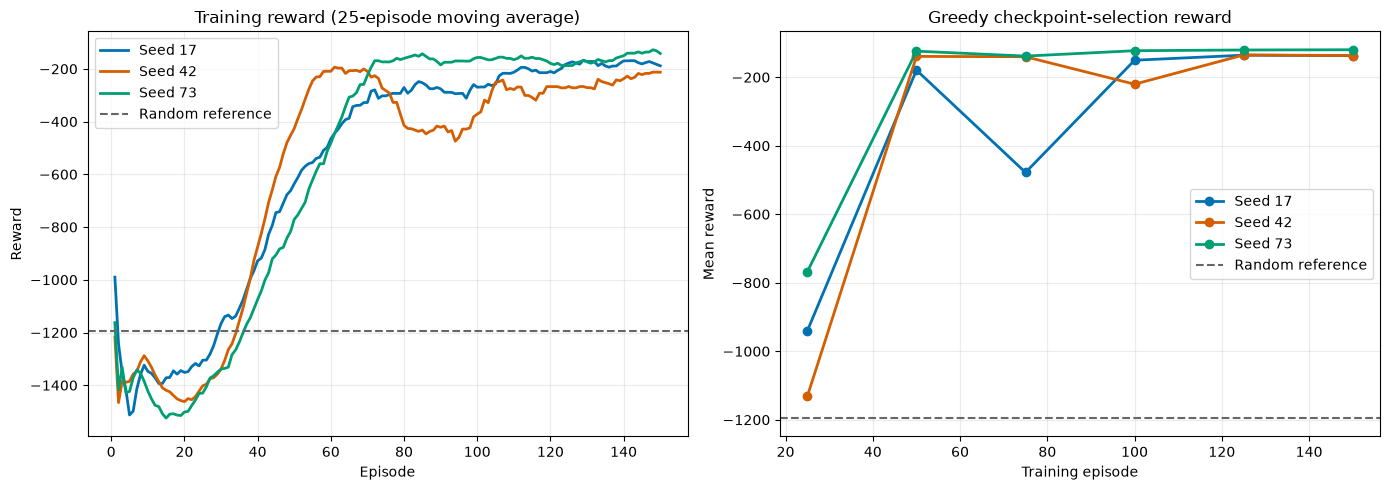

   experiment_id  training_seed  gravity  n_actions  episode  \
0    Default_DQN             17     10.0          5       25   
1    Default_DQN             17     10.0          5       50   
3    Default_DQN             17     10.0          5      100   
4    Default_DQN             17     10.0          5      125   
6    Default_DQN             42     10.0          5       25   
7    Default_DQN             42     10.0          5       50   
10   Default_DQN             42     10.0          5      125   
12   Default_DQN             73     10.0          5       25   
13   Default_DQN             73     10.0          5       50   
15   Default_DQN             73     10.0          5      100   
16   Default_DQN             73     10.0          5      125   
17   Default_DQN             73     10.0          5      150   

    environment_steps  validation_mean_reward  validation_std_reward  \
0                5000                 -940.07                 380.06   
1               10000  

In [13]:
training_log_df["reward_moving_average_25"] = (
    training_log_df.groupby("training_seed")["episode_reward"]
    .transform(lambda values: values.rolling(25, min_periods=1).mean())
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colours = {17: "#0072B2", 42: "#D55E00", 73: "#009E73"}

for training_seed in TRAINING_SEEDS:
    seed_training = training_log_df[training_log_df["training_seed"] == training_seed]
    seed_validation = validation_log_df[validation_log_df["training_seed"] == training_seed]
    axes[0].plot(
        seed_training["episode"],
        seed_training["reward_moving_average_25"],
        label=f"Seed {training_seed}",
        color=colours[training_seed],
        linewidth=2,
    )
    axes[1].plot(
        seed_validation["episode"],
        seed_validation["validation_mean_reward"],
        marker="o",
        label=f"Seed {training_seed}",
        color=colours[training_seed],
        linewidth=2,
    )

axes[0].set(title="Training reward (25-episode moving average)", xlabel="Episode", ylabel="Reward")
axes[1].set(
    title="Greedy checkpoint-selection reward",
    xlabel="Training episode",
    ylabel="Mean reward",
)
for axis in axes:
    axis.axhline(
        reference_summary.loc[
            reference_summary["policy"] == "Random discrete policy", "mean"
        ].iloc[0],
        color="#666666",
        linestyle="--",
        linewidth=1.5,
        label="Random reference",
    )
    axis.grid(alpha=0.25)
    axis.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "default_dqn_learning_and_validation.png", dpi=160, bbox_inches="tight")
plt.show()

checkpoint_rows = validation_log_df[validation_log_df["is_best_checkpoint"]].copy()
checkpoint_rows = checkpoint_rows.sort_values(["training_seed", "episode"])
display(checkpoint_rows.round(2))

In [14]:
seed_summary = (
    baseline_evaluation_df.groupby("training_seed")["episode_reward"]
    .agg(["mean", "std", "median", "min", "max"])
    .reset_index()
    .rename(columns={
        "mean": "mean_reward",
        "std": "episode_std",
        "median": "median_reward",
        "min": "worst_reward",
        "max": "best_reward",
    })
)

best_checkpoint_episodes = (
    h5_verification_df[[
        "training_seed",
        "best_checkpoint_episode",
        "runtime_seconds",
        "model_parameters",
    ]]
)
seed_summary = seed_summary.merge(best_checkpoint_episodes, on="training_seed", how="left")

random_mean = reference_summary.loc[
    reference_summary["policy"] == "Random discrete policy", "mean"
].iloc[0]
seed_summary["improvement_over_random"] = seed_summary["mean_reward"] - random_mean
seed_summary["beats_random"] = seed_summary["mean_reward"] > random_mean
seed_summary.to_csv(TABLES_DIR / "default_dqn_seed_summary.csv", index=False)
display(seed_summary.round(2))

first_last_rows = []
for training_seed in TRAINING_SEEDS:
    seed_log = training_log_df[training_log_df["training_seed"] == training_seed]
    first_last_rows.append({
        "training_seed": training_seed,
        "first_25_mean": seed_log.head(25)["episode_reward"].mean(),
        "last_25_mean": seed_log.tail(25)["episode_reward"].mean(),
        "change": (
            seed_log.tail(25)["episode_reward"].mean()
            - seed_log.head(25)["episode_reward"].mean()
        ),
        "mean_td_loss": seed_log["mean_td_loss"].mean(),
        "mean_gradient_norm": seed_log["mean_gradient_norm"].mean(),
        "clipped_update_fraction": seed_log["clipped_update_fraction"].mean(),
    })

training_diagnostic_df = pd.DataFrame(first_last_rows)
training_diagnostic_df.to_csv(TABLES_DIR / "default_dqn_training_diagnostics.csv", index=False)
display(training_diagnostic_df.round(4))

   training_seed  mean_reward  episode_std  median_reward  worst_reward  \
0             17      -146.66        74.97        -128.21       -302.54   
1             42      -151.42        84.46        -128.59       -350.51   
2             73      -147.32        86.71        -121.68       -353.52   

   best_reward  best_checkpoint_episode  runtime_seconds  model_parameters  \
0        -3.18                      125            91.04              4741   
1        -3.23                      125           118.57              4741   
2        -0.79                      150            90.88              4741   

   improvement_over_random  beats_random  
0                  1048.39          True  
1                  1043.63          True  
2                  1047.73          True  

   training_seed  first_25_mean  last_25_mean     change  mean_td_loss  \
0             17     -1305.1168     -188.3354  1116.7815        1.1742   
1             42     -1402.1181     -212.7544  1189.3636        1.0384   
2             73     -1429.9063     -141.5424  1288.3639        1.1395   

   mean_gradient_norm  clipped_update_fraction  
0             12.4627                   0.6363  
1             11.5151                   0.5814  
2             12.6474                   0.6568  

### Learning-Curve Interpretation

- In the left panel, all three 25-episode moving averages initially fall below the random reference, then improve sharply from roughly episodes 30 to 70. By the final 25 episodes, all three remain near `-200`, compared with `-1379.05` across the first 25 episodes and `-180.88` across the last 25.
- Seed `42` temporarily regresses around episodes 75 to 95 even though its later reward recovers. The right panel shows similar checkpoint reversals for seeds `17` and `42`; this is why the final episode is not automatically saved.
- The selected checkpoints are episodes `125`, `125` and `150` for seeds `17`, `42` and `73`. Reloaded checkpoints score `-148.47` on the separate comparison-validation starts, with `2.58` standard deviation between seed means.
- All three trained policies beat the random (`-1195.05`) and zero-torque (`-1191.81`) controls by a large margin.
- Gradient clipping occurs in `62.5%` of optimiser updates. This is an optimisation warning to investigate later, not evidence of better control.

The baseline has learned a repeatable policy and is suitable as the reference for controlled changes.


### 5.4.1 Fixed-Interval Policy Animations

The following animations use training seed `42` and evaluation seed `10003`, both declared before training. They capture the current greedy policy at fixed episodes `50`, `100` and `150`; they are not the visually best checkpoints and do not affect checkpoint selection.

In [15]:
display(progression_animation_df.round(2))
for _, animation_row in progression_animation_df.sort_values("training_episode").iterrows():
    print(
        f"Training episode {int(animation_row['training_episode'])}: "
        f"reward {animation_row['episode_reward']:.2f}"
    )
    display_gif(
        ANIMATIONS_DIR / animation_row["animation_file"],
        f"Default DQN policy at training episode {int(animation_row['training_episode'])}",
    )

   evaluation_seed  episode_reward  environment_steps  displayed_frames  \
0            10003         -125.81                200                50   
1            10003         -126.53                200                50   
2            10003         -124.45                200                50   

                      animation_file experiment_id  training_seed  \
0  default_dqn_seed42_episode050.gif   Default_DQN             42   
1  default_dqn_seed42_episode100.gif   Default_DQN             42   
2  default_dqn_seed42_episode150.gif   Default_DQN             42   

   training_episode  
0                50  
1               100  
2               150  

Training episode 50: reward -125.81


<IPython.core.display.HTML object>

Training episode 100: reward -126.53


<IPython.core.display.HTML object>

Training episode 150: reward -124.45


<IPython.core.display.HTML object>

### Animation-Progression Interpretation

For the fixed start, rewards are `-125.81`, `-126.53` and `-124.45` at episodes 50, 100 and 150. All three policies swing upright, but the reward is not monotonic: episode 100 is slightly worse than episode 50. This agrees with the checkpoint curve and shows why fixed-interval samples are useful for monitoring rather than selecting the visually best frame.


## 5.5 Physical Control Diagnostics

Reward alone cannot show whether the remaining cost comes mainly from angle error, fast motion or control effort. I decompose the exact reward terms over the validation episodes and report an additional descriptive stability fraction.

The stability diagnostic counts a step only when `|theta| <= 15 degrees` and `|theta_dot| <= 1 rad/s`. It is used to make behaviour interpretable, not as an assignment-defined pass threshold.

In [16]:
physical_summary = (
    baseline_evaluation_df.groupby("training_seed")
    .agg(
        mean_abs_angle_degrees=("mean_abs_angle_degrees", "mean"),
        rms_angular_velocity=("rms_angular_velocity", "mean"),
        mean_abs_torque=("mean_abs_torque", "mean"),
        upright_stable_fraction=("upright_stable_fraction", "mean"),
        angle_penalty=("angle_penalty", "mean"),
        velocity_penalty=("velocity_penalty", "mean"),
        torque_penalty=("torque_penalty", "mean"),
    )
    .reset_index()
)
physical_summary.to_csv(TABLES_DIR / "default_dqn_physical_summary.csv", index=False)
display(physical_summary.round(3))

action_usage = (
    baseline_trace_df.groupby(["training_seed", "torque"])
    .size()
    .rename("steps")
    .reset_index()
)
action_usage["fraction"] = action_usage.groupby("training_seed")["steps"].transform(
    lambda values: values / values.sum()
)
action_usage.to_csv(TABLES_DIR / "default_dqn_action_usage.csv", index=False)

action_usage_pivot = action_usage.pivot(
    index="training_seed", columns="torque", values="fraction"
).fillna(0.0)
display(action_usage_pivot.round(3))

   training_seed  mean_abs_angle_degrees  rms_angular_velocity  \
0             17                  18.777                 1.429   
1             42                  19.622                 1.476   
2             73                  15.413                 1.526   

   mean_abs_torque  upright_stable_fraction  angle_penalty  velocity_penalty  \
0            1.673                    0.848        101.274            44.774   
1            1.437                    0.839        103.131            47.828   
2            1.199                    0.830         95.415            51.446   

   torque_penalty  
0           0.607  
1           0.465  
2           0.455  

torque          -2.0   -1.0    0.0    1.0    2.0
training_seed                                   
17             0.272  0.096  0.008  0.214  0.410
42             0.202  0.075  0.006  0.475  0.241
73             0.223  0.100  0.339  0.022  0.315

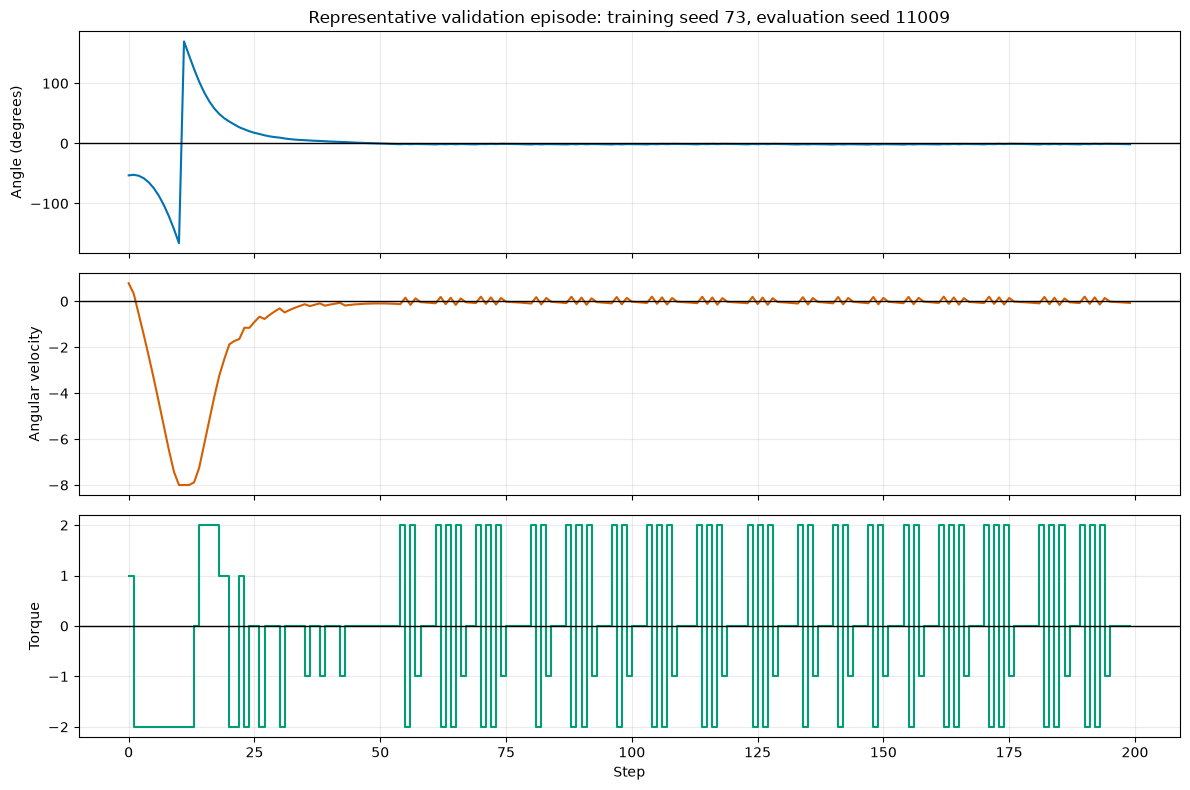

{'training_seed': 73, 'evaluation_seed': 11009, 'selection_rule': "Training seed closest to overall seed mean; episode closest to that seed's median reward"}


In [17]:
overall_seed_mean = seed_summary["mean_reward"].mean()
representative_seed = int(
    seed_summary.iloc[
        (seed_summary["mean_reward"] - overall_seed_mean)
        .abs()
        .argmin()
    ]["training_seed"]
)
representative_episodes = baseline_evaluation_df[
    baseline_evaluation_df["training_seed"] == representative_seed
]
representative_episode_reward = representative_episodes["episode_reward"].median()
representative_episode_seed = int(
    representative_episodes.iloc[
        (representative_episodes["episode_reward"] - representative_episode_reward).abs().argmin()
    ]["evaluation_seed"]
)
representative_trace = baseline_trace_df[
    (baseline_trace_df["training_seed"] == representative_seed)
    & (baseline_trace_df["evaluation_seed"] == representative_episode_seed)
]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(representative_trace["step"], representative_trace["theta_degrees"], color="#0072B2")
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_ylabel("Angle (degrees)")
axes[0].set_title(
    f"Representative validation episode: training seed {representative_seed}, "
    f"evaluation seed {representative_episode_seed}"
)

axes[1].plot(representative_trace["step"], representative_trace["theta_dot"], color="#D55E00")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_ylabel("Angular velocity")

axes[2].step(
    representative_trace["step"],
    representative_trace["torque"],
    where="post",
    color="#009E73",
)
axes[2].axhline(0, color="black", linewidth=1)
axes[2].set(ylabel="Torque", xlabel="Step")

for axis in axes:
    axis.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "default_dqn_representative_control_trace.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

representative_record = {
    "training_seed": representative_seed,
    "evaluation_seed": representative_episode_seed,
    "selection_rule": (
        "Training seed closest to overall seed mean; "
        "episode closest to that seed's median reward"
    ),
}
with open(TABLES_DIR / "default_dqn_representative_trace.json", "w", encoding="utf-8") as file:
    json.dump(representative_record, file, indent=2)

print(representative_record)

### Physical and Trace Interpretation

- In the top trace, the apparent jump from about `-160` to `+170` degrees is the angle wrapping at `-180/180` during the swing-up. The angle then decays towards zero and remains close to upright after roughly step 50.
- Angular velocity reaches the environment limit near `-8 rad/s` during the initial swing, then settles around zero. The torque panel shows sustained extreme torque during swing-up followed by frequent switching among the five actions near upright.
- Across all validation episodes, mean absolute angle is `17.94 degrees`, RMS angular velocity is `1.48 rad/s`, and `83.9%` of steps meet the descriptive upright-and-slow condition.
- Angle cost (`99.94`) is about twice velocity cost (`48.02`); torque cost is only `0.51` because its reward coefficient is small. Remaining reward is therefore driven mainly by position error.
- Extreme torques account for `55.5%` of actions and the action-switch fraction is `68.1%`. These observations motivate the action-resolution experiment, while the paired reward results will decide whether finer control actually helps.

The displayed trace uses the seed nearest the three-seed mean and an episode nearest that seed's median, so it is representative rather than a best case.


## 5.6 Representative Policy Animation

The animation uses the same representative seed and episode as the control trace. I reload the H5 checkpoint into a fresh network, select greedy actions and perform no training. Frames are sampled every second environment step only to keep the notebook and HTML file manageable; the policy still acts at all 200 steps.

In [18]:
animation_model = build_q_network(
    BASELINE_CONFIG["n_actions"], tuple(BASELINE_CONFIG["hidden_units"])
)
animation_weight_path = WEIGHTS_DIR / (
    f"Part_B_{BASELINE_CONFIG['experiment_id']}_seed{representative_seed}.weights.h5"
)
animation_model.load_weights(animation_weight_path)

animation_path = ANIMATIONS_DIR / "default_dqn_representative_episode.gif"
animation_record = save_policy_animation(
    animation_model,
    BASELINE_CONFIG["gravity"],
    ACTION_VALUES,
    representative_episode_seed,
    animation_path,
    BASELINE_CONFIG["max_steps"],
    frame_stride=2,
)
animation_record.update({
    "training_seed": representative_seed,
    "weight_file": animation_weight_path.name,
})

expected_animation_reward = representative_episodes.loc[
    representative_episodes["evaluation_seed"] == representative_episode_seed,
    "episode_reward",
].iloc[0]
assert np.isclose(animation_record["episode_reward"], expected_animation_reward, atol=1e-6)
with open(TABLES_DIR / "default_dqn_animation_record.json", "w", encoding="utf-8") as file:
    json.dump(animation_record, file, indent=2)

print(animation_record)
display_gif(
    animation_path,
    "Representative greedy policy from the reloaded default DQN checkpoint",
)

{'evaluation_seed': 11009, 'episode_reward': np.float64(-121.5052549002829), 'environment_steps': 200, 'displayed_frames': 100, 'animation_file': 'default_dqn_representative_episode.gif', 'training_seed': 73, 'weight_file': 'Part_B_Default_DQN_seed73.weights.h5'}


<IPython.core.display.HTML object>

### Animation Interpretation

The reloaded representative checkpoint obtained **-121.51** over 200 steps. The animation shows the same swing-up and settling represented by the trace; its reward is checked numerically, but the baseline decision still uses all three policies and all comparison-validation episodes.

## 5.7 Baseline Decision

**Retain the five-action DQN as the baseline.** Its mean reward was **-148.47**, all three seeds exceeded both controls by more than one thousand reward points, and between-seed spread was **2.58**. The remaining angle error, frequent extreme torque and control switching make action resolution the next relevant variable; learning rate and network size remain fixed because the evidence does not identify capacity as the bottleneck.

## 5.8 Hyperparameters Considered

The baseline identifies action resolution as the most direct next question. I considered the other taught DQN hyperparameters before fixing the controlled-experiment sequence, but the current evidence does not give them equal priority.

| Candidate | Evidence considered | Decision |
|---|---|---|
| Discount factor (`gamma`) | `0.99` preserves the delayed value of swing-up actions, and all three seeds learn far beyond the non-learning controls | **Defer.** Changing it would alter the planning horizon without evidence that short- or long-term credit assignment is the main weakness |
| Batch size | A batch of `64` already mixes replay samples cheaply; the main optimisation symptom is frequent clipping caused by large target magnitudes | **Defer.** A larger batch would not directly correct target scale, while a smaller batch may add variance |
| Replay-buffer capacity | The `50,000`-transition buffer is larger than the `30,000` interactions in one run, so no transition is discarded because the buffer is full | **Do not test.** Capacity is not an active constraint under the fixed training budget |
| Target-update frequency | Training improves consistently across seeds without divergent validation behaviour under the 500-step hard update | **Defer.** There is no evidence that targets are unusually stale or unstable; target estimation is examined separately through Double DQN |
| Learning rate | The policy learns reliably, while high clipping points more specifically to Bellman-target scale than to a failure to learn | **Defer.** Reward scaling is the more direct later diagnostic if large gradients persist |
| Network width/depth | The three-value state is handled well enough to achieve a large gain over both controls, with similar outcomes across seeds | **Defer.** Extra capacity adds parameters without evidence of underfitting |

These settings remain fixed so that each experiment changes one defensible factor. Deferred candidates may still be useful, but the baseline provides less reason to test them first.


# 6. Controlled Experiment 1: Action Resolution

## 6.1 Question and Controls

The baseline often selected extreme torques and changed torque after reaching the upright region. I therefore compare three symmetric action grids before altering exploration or target calculation.

| Actions | Torque spacing | Purpose |
|---:|---:|---|
| 5 | `1.0` | Baseline resolution |
| 11 | `0.4` | Moderate increase in control precision |
| 41 | `0.1` | Fine control close to the supplied example |

All three configurations use training seeds `17`, `42` and `73`. State preparation, hidden layers, optimiser, replay, target updates, exploration, gravity and training budget remain fixed. A candidate advances when its mean is higher and at least two paired seeds improve; seed spread, upright fraction, angle, switching and parameter count determine whether that provisional gain is worth keeping.


In [19]:
def result_bundle(config, result):
    return {
        "config": config,
        "training": result[0],
        "validation": result[1],
        "evaluation": result[2],
        "traces": result[3],
        "verification": result[4],
    }


action_results = {
    5: {
        "config": BASELINE_CONFIG.copy(),
        "training": training_log_df.copy(),
        "validation": validation_log_df.copy(),
        "evaluation": baseline_evaluation_df.copy(),
        "traces": baseline_trace_df.copy(),
        "verification": h5_verification_df.copy(),
    }
}

for n_actions in (11, 41):
    action_config = BASELINE_CONFIG.copy()
    action_config.update({
        "experiment_id": f"Action_{n_actions}",
        "model_name": f"DQN with {n_actions} actions",
        "n_actions": n_actions,
        "save_progression": False,
    })
    action_results[n_actions] = result_bundle(
        action_config,
        run_dqn_group(action_config, TRAINING_SEEDS),
    )

action_seed_rows = []
for n_actions, item in action_results.items():
    seed_means = item["evaluation"].groupby(
        "training_seed"
    )["episode_reward"].mean()
    for training_seed in TRAINING_SEEDS:
        action_seed_rows.append({
            "n_actions": n_actions,
            "training_seed": training_seed,
            "mean_reward": seed_means[training_seed],
        })

action_seed_df = pd.DataFrame(action_seed_rows)
baseline_action_means = action_seed_df.loc[
    action_seed_df["n_actions"] == 5
].set_index("training_seed")["mean_reward"]

action_summary_rows = []
for n_actions, group in action_seed_df.groupby("n_actions", sort=True):
    seed_means = group.set_index("training_seed")["mean_reward"]
    paired_gain = seed_means - baseline_action_means
    action_summary_rows.append({
        "n_actions": n_actions,
        "three_seed_mean": seed_means.mean(),
        "between_seed_std": seed_means.std(ddof=1),
        "mean_gain_over_5": paired_gain.mean(),
        "wins_over_5": int((paired_gain > 0).sum()),
    })

action_screen_df = pd.DataFrame(action_summary_rows).sort_values(
    "n_actions"
)
eligible_actions = action_screen_df.loc[
    (action_screen_df["n_actions"] != 5)
    & (action_screen_df["mean_gain_over_5"] > 0)
    & (action_screen_df["wins_over_5"] >= 2)
]
screening_winner_actions = (
    5
    if eligible_actions.empty
    else int(
        eligible_actions.loc[
            eligible_actions["three_seed_mean"].idxmax(),
            "n_actions",
        ]
    )
)

selected_action_result = action_results[screening_winner_actions]
ACTION_CANDIDATE_CONFIG = selected_action_result["config"].copy()
action_candidate_training = selected_action_result["training"].copy()
action_candidate_validation = selected_action_result["validation"].copy()
action_candidate_evaluation = selected_action_result["evaluation"].copy()
action_candidate_traces = selected_action_result["traces"].copy()
action_candidate_verification = selected_action_result[
    "verification"
].copy()

action_seed_df.to_csv(
    TABLES_DIR / "experiment_1_action_seed_results.csv",
    index=False,
)
action_screen_df.to_csv(
    TABLES_DIR / "experiment_1_action_screen.csv",
    index=False,
)
display(action_seed_df.round(2))
display(action_screen_df.round(3))
print("Three-seed action candidate:", screening_winner_actions)

Starting Action_11, seed 17


  Validation at episode 025 | seed 17 | mean -668.14 | SD 471.28 | checkpoint saved


  Validation at episode 050 | seed 17 | mean -665.47 | SD 640.13 | checkpoint saved


  Validation at episode 075 | seed 17 | mean -125.93 | SD 121.81 | checkpoint saved


  Validation at episode 100 | seed 17 | mean -122.50 | SD 114.38 | checkpoint saved


  Validation at episode 125 | seed 17 | mean -144.34 | SD 121.66 | checkpoint not replaced


... (36 outputs left out)

Completed Action_41, seed 73: mean validation reward -153.29


   n_actions  training_seed  mean_reward
0          5             17      -146.66
1          5             42      -151.42
2          5             73      -147.32
3         11             17      -142.89
4         11             42      -146.85
5         11             73      -150.08
6         41             17      -187.15
7         41             42      -169.96
8         41             73      -153.29

   n_actions  three_seed_mean  between_seed_std  mean_gain_over_5  wins_over_5
0          5         -148.465             2.583             0.000            0
1         11         -146.608             3.600             1.857            2
2         41         -170.131            16.932           -21.666            0

Three-seed action candidate: 11


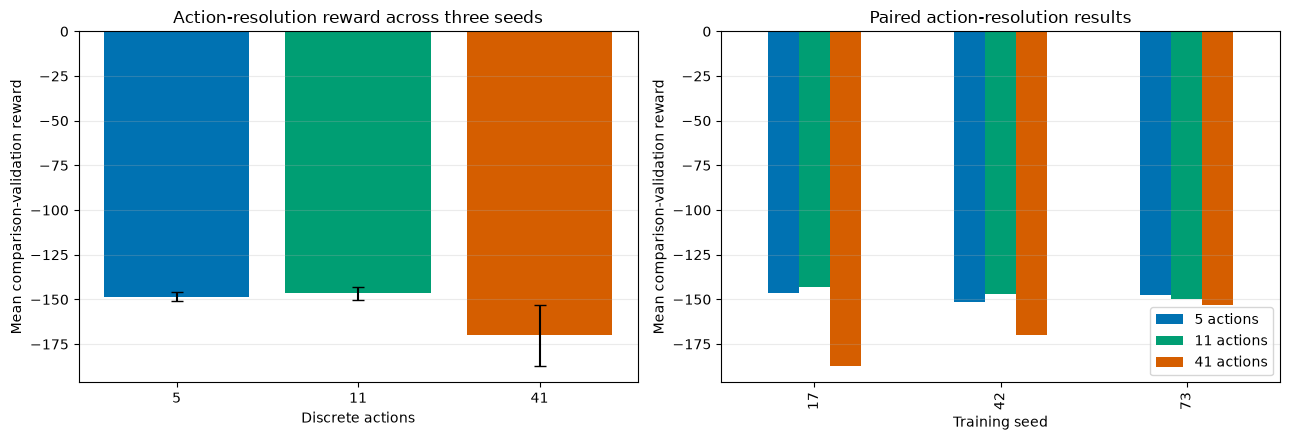

n_actions  training_seed  actions_5  actions_11  actions_41  \
0                     17    -146.66     -142.89     -187.15   
1                     42    -151.42     -146.85     -169.96   
2                     73    -147.32     -150.08     -153.29   

n_actions  actions_11_minus_5  actions_41_minus_5  
0                        3.76              -40.49  
1                        4.58              -18.54  
2                       -2.77               -5.97  

        model  actions  three_seed_mean  between_seed_std  \
0   5 actions        5         -148.465             2.583   
1  11 actions       11         -146.608             3.600   
2  41 actions       41         -170.131            16.932   

   mean_upright_fraction  mean_abs_angle_degrees  action_switch_fraction  \
0                  0.839                  17.937                   0.681   
1                  0.850                  16.321                   0.781   
2                  0.813                  20.052                   0.710   

   parameters  
0        4741  
1        5131  
2        7081  

In [20]:
action_reward_pivot = action_seed_df.pivot(
    index="training_seed",
    columns="n_actions",
    values="mean_reward",
).rename(columns={
    5: "actions_5",
    11: "actions_11",
    41: "actions_41",
})
paired_action = action_reward_pivot.reset_index()
for n_actions in (11, 41):
    paired_action[f"actions_{n_actions}_minus_5"] = (
        paired_action[f"actions_{n_actions}"]
        - paired_action["actions_5"]
    )

action_candidate_confirmed = screening_winner_actions != 5

if action_candidate_confirmed:
    ACTION_WINNER_CONFIG = ACTION_CANDIDATE_CONFIG.copy()
    action_winner_training = action_candidate_training.copy()
    action_winner_validation = action_candidate_validation.copy()
    action_winner_evaluation = action_candidate_evaluation.copy()
    action_winner_traces = action_candidate_traces.copy()
    action_winner_verification = action_candidate_verification.copy()
else:
    ACTION_WINNER_CONFIG = BASELINE_CONFIG.copy()
    action_winner_training = training_log_df.copy()
    action_winner_validation = validation_log_df.copy()
    action_winner_evaluation = baseline_evaluation_df.copy()
    action_winner_traces = baseline_trace_df.copy()
    action_winner_verification = h5_verification_df.copy()


def trace_switch_fraction(trace_frame):
    ordered = trace_frame.sort_values(
        ["training_seed", "evaluation_seed", "step"]
    ).copy()
    changed = ordered.groupby(
        ["training_seed", "evaluation_seed"]
    )["action_id"].transform(
        lambda values: values.ne(values.shift())
    )
    first_step = ordered.groupby(
        ["training_seed", "evaluation_seed"]
    ).cumcount().eq(0)
    return float(changed[~first_step].mean())


action_comparison_rows = []
for n_actions, item in action_results.items():
    seed_means = item["evaluation"].groupby(
        "training_seed"
    )["episode_reward"].mean()
    action_comparison_rows.append({
        "model": f"{n_actions} actions",
        "actions": n_actions,
        "three_seed_mean": seed_means.mean(),
        "between_seed_std": seed_means.std(ddof=1),
        "mean_upright_fraction": item["evaluation"][
            "upright_stable_fraction"
        ].mean(),
        "mean_abs_angle_degrees": item["evaluation"][
            "mean_abs_angle_degrees"
        ].mean(),
        "action_switch_fraction": trace_switch_fraction(item["traces"]),
        "parameters": int(
            item["verification"]["model_parameters"].iloc[0]
        ),
    })
action_comparison = pd.DataFrame(action_comparison_rows).sort_values(
    "actions"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(
    action_screen_df["n_actions"].astype(str),
    action_screen_df["three_seed_mean"],
    yerr=action_screen_df["between_seed_std"],
    capsize=4,
    color=["#0072B2", "#009E73", "#D55E00"],
)
axes[0].set(
    title="Action-resolution reward across three seeds",
    xlabel="Discrete actions",
    ylabel="Mean comparison-validation reward",
)
paired_action.set_index("training_seed")[[
    "actions_5",
    "actions_11",
    "actions_41",
]].plot(
    kind="bar",
    ax=axes[1],
    color=["#0072B2", "#009E73", "#D55E00"],
)
axes[1].set(
    title="Paired action-resolution results",
    xlabel="Training seed",
    ylabel="Mean comparison-validation reward",
)
axes[1].legend(["5 actions", "11 actions", "41 actions"])
for axis in axes:
    axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "experiment_1_action_resolution.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

paired_action.to_csv(
    TABLES_DIR / "experiment_1_action_paired.csv",
    index=False,
)
action_comparison.to_csv(
    TABLES_DIR / "experiment_1_action_summary.csv",
    index=False,
)
display(paired_action.round(2))
display(action_comparison.round(3))

with open(
    TABLES_DIR / "experiment_1_winner_config.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(ACTION_WINNER_CONFIG, file, indent=2)

## 6.2 Results and Decision

| Result across three paired seeds | 5 actions | 11 actions | 41 actions |
|---|---:|---:|---:|
| Mean validation reward | `-148.47` | `-146.61` | `-170.13` |
| Between-seed standard deviation | `2.58` | `3.60` | `16.93` |
| Upright-and-slow fraction | `83.91%` | `84.95%` | `81.26%` |
| Mean absolute angle | `17.94 deg` | `16.32 deg` | `20.05 deg` |
| Action-switch fraction | `68.1%` | `78.1%` | `71.0%` |
| Parameters | `4,741` | `5,131` | `7,081` |

- The left chart shows that the error bars for 5 and 11 actions overlap, whereas 41 actions has both a lower mean and much larger spread. The paired chart confirms that 11 actions improves seeds `17` and `42` but regresses seed `73`.
- Eleven actions gains `1.86` reward points, reduces mean angle error by `1.62 degrees`, and raises stable steps by `1.04` percentage points. It also adds `390` parameters, increases switching by about ten percentage points, and raises seed spread.
- Forty-one actions loses to five actions for every seed. Its larger output space is harder to learn within the same 30,000 interactions and gives no physical improvement.

**Provisional decision:** carry 11 actions forward because it has the highest mean and two paired wins. The overlapping error bars and worse spread prevent a final decision at this point; Section 9 reviews the trade-off after the other two factors are tested.


# 7. Controlled Experiment 2: Exploration Strategy

## 7.1 Question and Controls

Constant `epsilon = 0.10` provides little initial exploration but continues the same random-action rate after learning. I compare it with one complete linear strategy: `1.00 -> 0.05` over 20,000 steps.

- **Independent variable:** exploration strategy as a complete package.
- **Controls:** action grid, target method, architecture, optimiser, replay, gravity, interactions and evaluation starts.
- **Decision evidence:** paired comparison-validation reward, between-seed spread, learning curve and upright fraction.

This comparison can establish which complete strategy works better here. It cannot isolate whether the start value, endpoint or linear shape caused the difference; that limitation remains explicit rather than being presented as a strict single-parameter result.

Starting Action_11_Epsilon_Decay, seed 17


  Validation at episode 025 | seed 17 | mean -797.50 | SD 306.98 | checkpoint saved


  Validation at episode 050 | seed 17 | mean -437.36 | SD 418.82 | checkpoint saved


  Validation at episode 075 | seed 17 | mean -122.50 | SD 114.04 | checkpoint saved


  Validation at episode 100 | seed 17 | mean -136.59 | SD 121.57 | checkpoint not replaced


  Validation at episode 125 | seed 17 | mean -131.38 | SD 115.57 | checkpoint not replaced


... (12 outputs left out)

  Validation at episode 100 | seed 73 | mean -124.51 | SD 117.36 | checkpoint saved


  Validation at episode 125 | seed 73 | mean -121.52 | SD 113.28 | checkpoint saved


  Validation at episode 150 | seed 73 | mean -122.47 | SD 115.35 | checkpoint not replaced


Completed Action_11_Epsilon_Decay, seed 73: mean validation reward -149.50


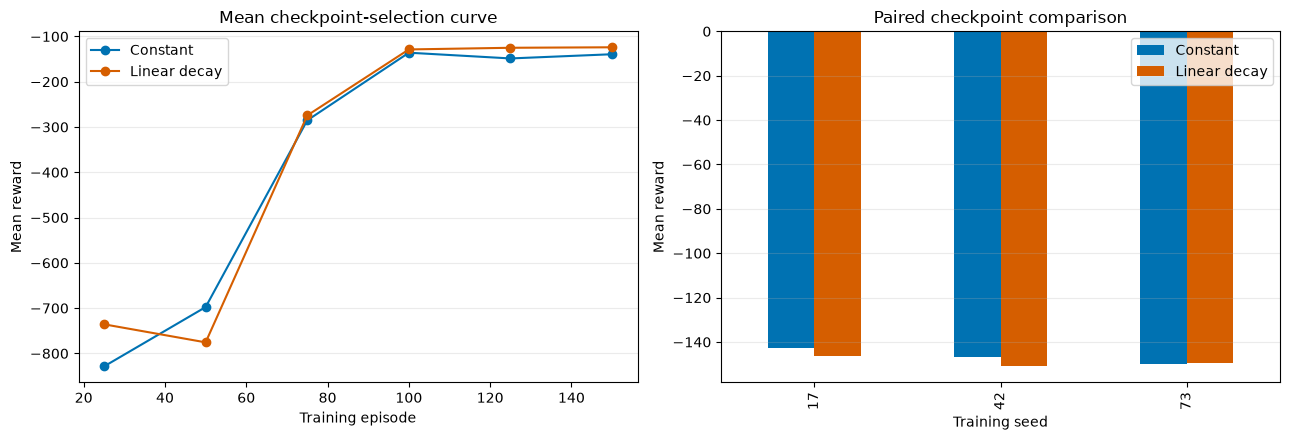

   training_seed  constant_epsilon  linear_decay  decay_minus_constant
0             17           -142.89       -146.40                 -3.51
1             42           -146.85       -150.67                 -3.82
2             73           -150.08       -149.50                  0.58

              schedule  three_seed_mean  between_seed_std  \
0        Constant 0.10         -146.608             3.600   
1  Linear 1.00 to 0.05         -148.859             2.206   

   episode_50_validation  mean_upright_fraction  
0               -697.688                  0.850  
1               -775.587                  0.847  

In [21]:
DECAY_CONFIG = ACTION_WINNER_CONFIG.copy()
DECAY_CONFIG.update({
    "experiment_id": f"Action_{ACTION_WINNER_CONFIG['n_actions']}_Epsilon_Decay",
    "model_name": "DQN with linear epsilon decay",
    "epsilon_schedule": "linear",
    "epsilon_start": 1.00,
    "epsilon_end": 0.05,
    "epsilon_decay_steps": 20_000,
    "save_progression": False,
})

(
    decay_training,
    decay_validation,
    decay_evaluation,
    decay_traces,
    decay_verification,
    _,
) = run_dqn_group(DECAY_CONFIG, TRAINING_SEEDS)

parent_exploration_means = action_winner_evaluation.groupby(
    "training_seed"
)["episode_reward"].mean()
decay_seed_means = decay_evaluation.groupby("training_seed")["episode_reward"].mean()
paired_exploration = pd.DataFrame({
    "training_seed": TRAINING_SEEDS,
    "constant_epsilon": [parent_exploration_means[seed] for seed in TRAINING_SEEDS],
    "linear_decay": [decay_seed_means[seed] for seed in TRAINING_SEEDS],
})
paired_exploration["decay_minus_constant"] = (
    paired_exploration["linear_decay"] - paired_exploration["constant_epsilon"]
)

decay_wins = int((paired_exploration["decay_minus_constant"] > 0).sum())
decay_confirmed = (
    paired_exploration["linear_decay"].mean()
    > paired_exploration["constant_epsilon"].mean()
    and decay_wins >= 2
)

if decay_confirmed:
    EXPLORATION_WINNER_CONFIG = DECAY_CONFIG.copy()
    exploration_winner_training = decay_training.copy()
    exploration_winner_validation = decay_validation.copy()
    exploration_winner_evaluation = decay_evaluation.copy()
    exploration_winner_traces = decay_traces.copy()
    exploration_winner_verification = decay_verification.copy()
else:
    EXPLORATION_WINNER_CONFIG = ACTION_WINNER_CONFIG.copy()
    exploration_winner_training = action_winner_training.copy()
    exploration_winner_validation = action_winner_validation.copy()
    exploration_winner_evaluation = action_winner_evaluation.copy()
    exploration_winner_traces = action_winner_traces.copy()
    exploration_winner_verification = action_winner_verification.copy()

constant_episode_50 = action_winner_validation.loc[
    action_winner_validation["episode"] == 50
].groupby("training_seed")["validation_mean_reward"].mean().mean()
decay_episode_50 = decay_validation.loc[
    decay_validation["episode"] == 50
].groupby("training_seed")["validation_mean_reward"].mean().mean()

exploration_summary = pd.DataFrame([
    {
        "schedule": "Constant 0.10",
        "three_seed_mean": paired_exploration["constant_epsilon"].mean(),
        "between_seed_std": parent_exploration_means.std(ddof=1),
        "episode_50_validation": constant_episode_50,
        "mean_upright_fraction": action_winner_evaluation["upright_stable_fraction"].mean(),
    },
    {
        "schedule": "Linear 1.00 to 0.05",
        "three_seed_mean": paired_exploration["linear_decay"].mean(),
        "between_seed_std": decay_seed_means.std(ddof=1),
        "episode_50_validation": decay_episode_50,
        "mean_upright_fraction": decay_evaluation["upright_stable_fraction"].mean(),
    },
])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for label, frame, colour in [
    ("Constant", action_winner_validation, "#0072B2"),
    ("Linear decay", decay_validation, "#D55E00"),
]:
    curve = frame.groupby("episode")["validation_mean_reward"].mean()
    axes[0].plot(curve.index, curve.values, marker="o", label=label, color=colour)
paired_exploration.set_index("training_seed")[[
    "constant_epsilon",
    "linear_decay",
]].plot(
    kind="bar",
    ax=axes[1],
    color=["#0072B2", "#D55E00"],
)
axes[0].set(
    title="Mean checkpoint-selection curve",
    xlabel="Training episode",
    ylabel="Mean reward",
)
axes[1].set(title="Paired checkpoint comparison", xlabel="Training seed", ylabel="Mean reward")
axes[1].legend(["Constant", "Linear decay"])
for axis in axes:
    axis.grid(axis="y", alpha=0.25)
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "experiment_2_exploration_schedule.png", dpi=160, bbox_inches="tight")
plt.show()

paired_exploration.to_csv(TABLES_DIR / "experiment_2_exploration_paired.csv", index=False)
exploration_summary.to_csv(TABLES_DIR / "experiment_2_exploration_summary.csv", index=False)
display(paired_exploration.round(2))
display(exploration_summary.round(3))

with open(TABLES_DIR / "experiment_2_winner_config.json", "w", encoding="utf-8") as file:
    json.dump(EXPLORATION_WINNER_CONFIG, file, indent=2)

## 7.2 Results and Decision

The left chart shows a small early advantage for linear decay at episode 25, followed by weaker reward at episode 50 (`-775.59` versus `-697.69`). The two curves are close after episode 100, so the schedule does not produce a lasting learning advantage within 150 episodes. In the paired chart, constant epsilon wins for seeds `17` and `42`; decay improves only seed `73`.

Linear decay finishes at `-148.86` versus `-146.61` for constant epsilon. Its lower between-seed spread (`2.21` versus `3.60`) is useful, but it accompanies a lower mean and only one paired win.

**Decision:** retain constant epsilon for the provisional 11-action model. The complete `1.00 -> 0.05` schedule has a lower mean and improves only one seed. This comparison does not isolate its starting value, endpoint or linear shape.


# 8. Controlled Experiment 3: Double-DQN Target

## 8.1 Question and Controls

Ordinary DQN uses the maximum target-network value both to select and evaluate the next action. This maximum can favour an overestimated action. Double DQN separates the two roles: the online network selects the next action, while the target network evaluates it.

**Question:** Does the Double-DQN target improve reward or stability for the current Pendulum configuration?

- **Independent variable:** Bellman next-action target (`DQN` versus `Double DQN`).
- **Controls:** action grid, selected epsilon schedule, network, optimiser, replay, target-copy interval, gravity, 30,000 steps and validation starts.
- **Primary evidence:** paired three-seed greedy validation reward.
- **Supporting evidence:** between-seed spread, validation regressions, TD loss and clipping frequency.
- **Decision rule:** adopt Double DQN only if its three-seed mean is higher and at least two paired seeds improve. A known theoretical advantage is not treated as evidence that it helped this implementation.

**Source:** [van Hasselt, Guez and Silver (2016), Double DQN](https://arxiv.org/abs/1509.06461).

Starting Action_11_Double_DQN, seed 17


  Validation at episode 025 | seed 17 | mean -844.67 | SD 449.71 | checkpoint saved


  Validation at episode 050 | seed 17 | mean -624.05 | SD 513.07 | checkpoint saved


  Validation at episode 075 | seed 17 | mean -168.91 | SD 162.13 | checkpoint saved


  Validation at episode 100 | seed 17 | mean -189.78 | SD 233.63 | checkpoint not replaced


  Validation at episode 125 | seed 17 | mean -161.45 | SD 128.05 | checkpoint saved


... (12 outputs left out)

  Validation at episode 100 | seed 73 | mean -126.40 | SD 118.83 | checkpoint saved


  Validation at episode 125 | seed 73 | mean -281.95 | SD 591.54 | checkpoint not replaced


  Validation at episode 150 | seed 73 | mean -282.72 | SD 591.29 | checkpoint not replaced


Completed Action_11_Double_DQN, seed 73: mean validation reward -148.04


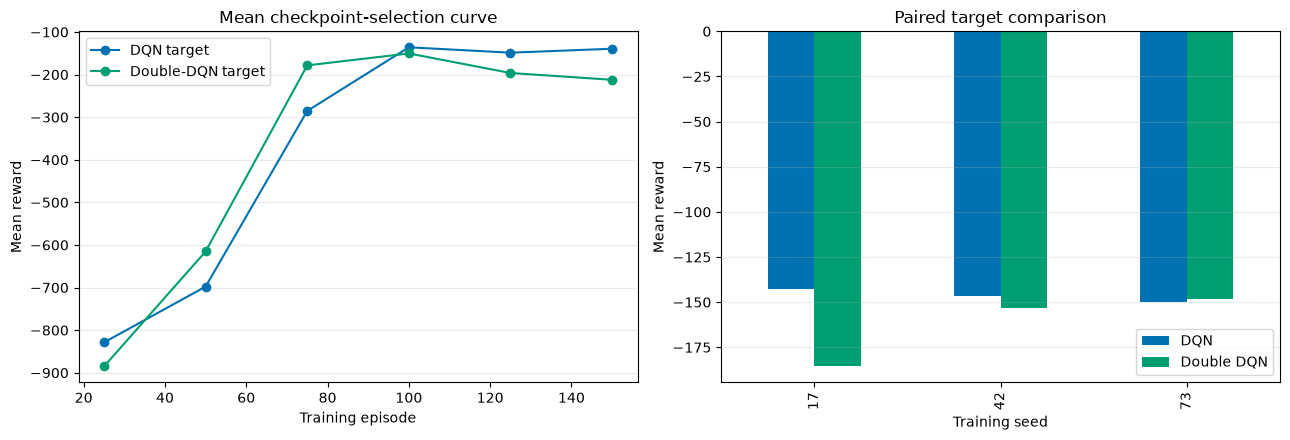

   training_seed  dqn_target  double_dqn_target  double_minus_dqn
0             17     -142.89            -185.16            -42.26
1             42     -146.85            -152.97             -6.13
2             73     -150.08            -148.04              2.05

       target  three_seed_mean  between_seed_std  mean_td_loss  \
0         DQN        -146.6083            3.6001        1.2494   
1  Double DQN        -162.0564           20.1597        1.3895   

   clipped_update_fraction  
0                   0.5978  
1                   0.6464  

In [22]:
DOUBLE_DQN_CONFIG = EXPLORATION_WINNER_CONFIG.copy()
DOUBLE_DQN_CONFIG.update({
    "experiment_id": f"{EXPLORATION_WINNER_CONFIG['experiment_id']}_Double_DQN",
    "model_name": "Double-DQN target",
    "target_method": "double_dqn",
    "save_progression": False,
})

(
    double_training,
    double_validation,
    double_evaluation,
    double_traces,
    double_verification,
    _,
) = run_dqn_group(DOUBLE_DQN_CONFIG, TRAINING_SEEDS)

parent_target_means = exploration_winner_evaluation.groupby(
    "training_seed"
)["episode_reward"].mean()
double_seed_means = double_evaluation.groupby("training_seed")["episode_reward"].mean()
paired_target = pd.DataFrame({
    "training_seed": TRAINING_SEEDS,
    "dqn_target": [parent_target_means[seed] for seed in TRAINING_SEEDS],
    "double_dqn_target": [double_seed_means[seed] for seed in TRAINING_SEEDS],
})
paired_target["double_minus_dqn"] = (
    paired_target["double_dqn_target"] - paired_target["dqn_target"]
)

double_wins = int((paired_target["double_minus_dqn"] > 0).sum())
double_confirmed = (
    paired_target["double_dqn_target"].mean()
    > paired_target["dqn_target"].mean()
    and double_wins >= 2
)

if double_confirmed:
    TARGET_WINNER_CONFIG = DOUBLE_DQN_CONFIG.copy()
    target_winner_training = double_training.copy()
    target_winner_validation = double_validation.copy()
    target_winner_evaluation = double_evaluation.copy()
    target_winner_traces = double_traces.copy()
    target_winner_verification = double_verification.copy()
else:
    TARGET_WINNER_CONFIG = EXPLORATION_WINNER_CONFIG.copy()
    target_winner_training = exploration_winner_training.copy()
    target_winner_validation = exploration_winner_validation.copy()
    target_winner_evaluation = exploration_winner_evaluation.copy()
    target_winner_traces = exploration_winner_traces.copy()
    target_winner_verification = exploration_winner_verification.copy()

target_diagnostics = pd.DataFrame([
    {
        "target": "DQN",
        "three_seed_mean": paired_target["dqn_target"].mean(),
        "between_seed_std": parent_target_means.std(ddof=1),
        "mean_td_loss": exploration_winner_training["mean_td_loss"].mean(),
        "clipped_update_fraction": exploration_winner_training["clipped_update_fraction"].mean(),
    },
    {
        "target": "Double DQN",
        "three_seed_mean": paired_target["double_dqn_target"].mean(),
        "between_seed_std": double_seed_means.std(ddof=1),
        "mean_td_loss": double_training["mean_td_loss"].mean(),
        "clipped_update_fraction": double_training["clipped_update_fraction"].mean(),
    },
])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for label, frame, colour in [
    ("DQN target", exploration_winner_validation, "#0072B2"),
    ("Double-DQN target", double_validation, "#009E73"),
]:
    curve = frame.groupby("episode")["validation_mean_reward"].mean()
    axes[0].plot(curve.index, curve.values, marker="o", label=label, color=colour)
paired_target.set_index("training_seed")[[
    "dqn_target",
    "double_dqn_target",
]].plot(
    kind="bar",
    ax=axes[1],
    color=["#0072B2", "#009E73"],
)
axes[0].set(
    title="Mean checkpoint-selection curve",
    xlabel="Training episode",
    ylabel="Mean reward",
)
axes[1].set(title="Paired target comparison", xlabel="Training seed", ylabel="Mean reward")
axes[1].legend(["DQN", "Double DQN"])
for axis in axes:
    axis.grid(axis="y", alpha=0.25)
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "experiment_3_double_dqn.png", dpi=160, bbox_inches="tight")
plt.show()

paired_target.to_csv(TABLES_DIR / "experiment_3_target_paired.csv", index=False)
target_diagnostics.to_csv(TABLES_DIR / "experiment_3_target_summary.csv", index=False)
display(paired_target.round(2))
display(target_diagnostics.round(4))

with open(TABLES_DIR / "experiment_3_winner_config.json", "w", encoding="utf-8") as file:
    json.dump(TARGET_WINNER_CONFIG, file, indent=2)

## 8.2 Results and Decision

The checkpoint curve shows Double DQN ahead at episodes 50 and 75, but its mean then deteriorates after episode 100 while ordinary DQN remains near `-150`. The paired bars show that this late regression is concentrated in seed `17`; seed `42` is also worse and only seed `73` improves.

Mean reward falls from `-146.61` to `-162.06`, between-seed spread rises from `3.60` to `20.16`, and TD loss and clipping frequency both increase (`1.249 -> 1.389` and `59.8% -> 64.7%`).

**Decision:** retain ordinary DQN for the provisional 11-action model. Under the fixed budget, Double DQN lowers the mean and increases variation. The higher TD loss and clipping are consistent with less stable value updates, although this experiment does not isolate the cause.


# 9. Action-Resolution Trade-Off Review

## 9.1 Why the Action Count Is Revisited

Eleven actions produced a small provisional gain. Linear epsilon decay and Double DQN were then tested on that provisional parent and both were rejected, returning the non-action settings to the original baseline. The existing 5-, 11- and 41-action runs are therefore already matched on every other setting.

No additional training is performed here. I reconsider the existing paired action results using reward, seed spread, switching and parameter count together. Forty-one actions remains the fine-resolution boundary case.


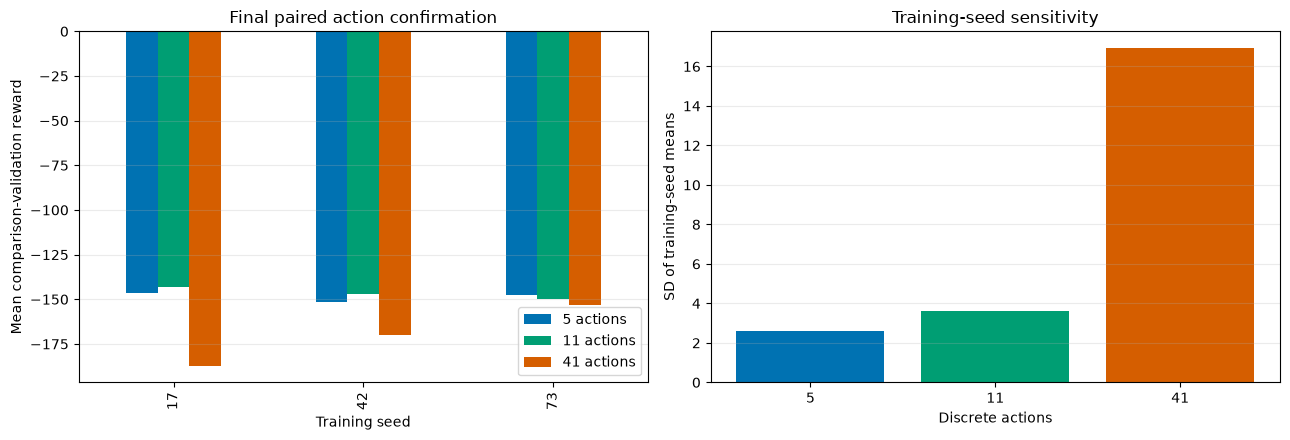

   training_seed  actions_5  actions_11  actions_41  actions_11_minus_5  \
0             17    -146.66     -142.89     -187.15                3.76   
1             42    -151.42     -146.85     -169.96                4.58   
2             73    -147.32     -150.08     -153.29               -2.77   

   actions_41_minus_5  
0              -40.49  
1              -18.54  
2               -5.97  

   actions  three_seed_mean  between_seed_std  upright_stable_fraction  \
0        5         -148.465             2.583                    0.839   
1       11         -146.608             3.600                    0.850   
2       41         -170.131            16.932                    0.813   

   mean_abs_angle_degrees  action_switch_fraction  parameters  
0                  17.937                   0.681        4741  
1                  16.321                   0.781        5131  
2                  20.052                   0.710        7081  

Selected action count: 5


In [23]:
CORE_CONFIG_KEYS = (
    "hidden_units",
    "episodes",
    "max_steps",
    "gamma",
    "learning_rate",
    "reward_scale",
    "batch_size",
    "replay_capacity",
    "warmup_steps",
    "epsilon_schedule",
    "epsilon_start",
    "epsilon_end",
    "epsilon_decay_steps",
    "target_method",
    "target_update_steps",
    "gradient_clip_norm",
)


def same_core_settings(left, right):
    return all(left[key] == right[key] for key in CORE_CONFIG_KEYS)


final_action_results = {}
for action_count in (5, 11, 41):
    known = action_results[action_count]
    if same_core_settings(TARGET_WINNER_CONFIG, known["config"]):
        final_action_results[action_count] = {
            key: value.copy() if hasattr(value, "copy") else value
            for key, value in known.items()
        }
        continue

    if TARGET_WINNER_CONFIG["n_actions"] == action_count:
        final_action_results[action_count] = {
            "config": TARGET_WINNER_CONFIG.copy(),
            "training": target_winner_training.copy(),
            "validation": target_winner_validation.copy(),
            "evaluation": target_winner_evaluation.copy(),
            "traces": target_winner_traces.copy(),
            "verification": target_winner_verification.copy(),
        }
        continue

    candidate_config = TARGET_WINNER_CONFIG.copy()
    candidate_config.update({
        "experiment_id": (
            f"Final_Action_{action_count}_Selected_Strategy"
        ),
        "model_name": (
            f"Selected strategy with {action_count} actions"
        ),
        "n_actions": action_count,
        "save_progression": False,
    })
    result = run_dqn_group(candidate_config, TRAINING_SEEDS)
    final_action_results[action_count] = result_bundle(
        candidate_config,
        result,
    )

final_action_seed_means = {
    action_count: item["evaluation"].groupby(
        "training_seed"
    )["episode_reward"].mean()
    for action_count, item in final_action_results.items()
}
paired_final_action = pd.DataFrame({
    "training_seed": TRAINING_SEEDS,
    **{
        f"actions_{action_count}": [
            final_action_seed_means[action_count][seed]
            for seed in TRAINING_SEEDS
        ]
        for action_count in (5, 11, 41)
    },
})
for action_count in (11, 41):
    paired_final_action[f"actions_{action_count}_minus_5"] = (
        paired_final_action[f"actions_{action_count}"]
        - paired_final_action["actions_5"]
    )

final_action_summary_rows = []
for action_count, item in final_action_results.items():
    seed_means = final_action_seed_means[action_count]
    final_action_summary_rows.append({
        "actions": action_count,
        "three_seed_mean": seed_means.mean(),
        "between_seed_std": seed_means.std(ddof=1),
        "upright_stable_fraction": item["evaluation"][
            "upright_stable_fraction"
        ].mean(),
        "mean_abs_angle_degrees": item["evaluation"][
            "mean_abs_angle_degrees"
        ].mean(),
        "action_switch_fraction": trace_switch_fraction(item["traces"]),
        "parameters": int(
            item["verification"]["model_parameters"].iloc[0]
        ),
    })
final_action_summary_df = pd.DataFrame(
    final_action_summary_rows
).sort_values("actions")

baseline_final_mean = final_action_seed_means[5].mean()
baseline_final_std = final_action_seed_means[5].std(ddof=1)
eligible_final_actions = []
for action_count in (11, 41):
    differences = (
        final_action_seed_means[action_count]
        - final_action_seed_means[5]
    )
    if (
        final_action_seed_means[action_count].mean()
        > baseline_final_mean
        and int((differences > 0).sum()) >= 2
        and final_action_seed_means[action_count].std(ddof=1)
        <= baseline_final_std
    ):
        eligible_final_actions.append(action_count)

selected_action_count = (
    5
    if not eligible_final_actions
    else max(
        eligible_final_actions,
        key=lambda count: final_action_seed_means[count].mean(),
    )
)

selected_action_result = final_action_results[selected_action_count]
FINAL_ACTION_CONFIG = selected_action_result["config"].copy()
final_action_training = selected_action_result["training"].copy()
final_action_validation = selected_action_result["validation"].copy()
final_action_evaluation = selected_action_result["evaluation"].copy()
final_action_traces = selected_action_result["traces"].copy()
final_action_verification = selected_action_result[
    "verification"
].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
paired_final_action.set_index("training_seed")[[
    "actions_5",
    "actions_11",
    "actions_41",
]].plot(
    kind="bar",
    ax=axes[0],
    color=["#0072B2", "#009E73", "#D55E00"],
)
axes[0].set(
    title="Final paired action confirmation",
    xlabel="Training seed",
    ylabel="Mean comparison-validation reward",
)
axes[0].legend(["5 actions", "11 actions", "41 actions"])
axes[1].bar(
    final_action_summary_df["actions"].astype(str),
    final_action_summary_df["between_seed_std"],
    color=["#0072B2", "#009E73", "#D55E00"],
)
axes[1].set(
    title="Training-seed sensitivity",
    xlabel="Discrete actions",
    ylabel="SD of training-seed means",
)
for axis in axes:
    axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "final_action_resolution_confirmation.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

paired_final_action.to_csv(
    TABLES_DIR / "final_action_confirmation_paired.csv",
    index=False,
)
final_action_summary_df.to_csv(
    TABLES_DIR / "final_action_confirmation_summary.csv",
    index=False,
)
with open(
    TABLES_DIR / "final_action_selected_config.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(FINAL_ACTION_CONFIG, file, indent=2)

display(paired_final_action.round(2))
display(final_action_summary_df.round(3))
print("Selected action count:", selected_action_count)

## 9.2 Results and Decision

The left panel deliberately repeats the paired action results under the final selection rule; it is not a second run. The right panel isolates training-seed sensitivity: spread rises from `2.58` with 5 actions to `3.60` with 11 and `16.93` with 41.

Eleven actions has the higher mean (`-146.61` versus `-148.47`) and slightly better angle and upright measures, but the `1.86`-point gain is not consistent across all seeds. It also increases switching from `68.1%` to `78.1%` and parameters from `4,741` to `5,131`. Forty-one actions is worse on every paired seed.

**Decision:** select **5 actions**. The modest 11-action gain does not offset its higher variability and control chatter, while 41 actions is clearly inferior under the same budget.


# 10. Additional Investigation: Reward Scaling

## 10.1 Reason for the Test and Controls

Gradient clipping occurs in about three fifths of baseline updates, and the mean gradient norm exceeds the clipping limit of `10`. This makes Bellman-target scale a more direct question than adding network capacity.

Increasing width would add parameters without evidence of underfitting. Lowering the learning rate changes the update after the gradient is calculated but does not reduce the TD-error scale, while raising the clip limit weakens the safeguard. I instead multiply rewards stored in replay by `0.1`, leaving the environment reward, evaluation, checkpoint selection and reported scores on their original scale.

Because this change is intended to improve optimisation stability, I retain it only if the mean improves, none of the three paired runs regress, and between-seed spread does not increase. This uses consistency rather than an arbitrary numerical improvement threshold. All other settings remain fixed.


Starting Reward_Scale_0_1, seed 17


  Validation at episode 025 | seed 17 | mean -849.18 | SD 252.04 | checkpoint saved


  Validation at episode 050 | seed 17 | mean -123.25 | SD 115.46 | checkpoint saved


  Validation at episode 075 | seed 17 | mean -122.41 | SD 116.78 | checkpoint saved


  Validation at episode 100 | seed 17 | mean -122.72 | SD 117.18 | checkpoint not replaced


  Validation at episode 125 | seed 17 | mean -121.51 | SD 114.92 | checkpoint saved


... (12 outputs left out)

  Validation at episode 100 | seed 73 | mean -123.65 | SD 119.64 | checkpoint not replaced


  Validation at episode 125 | seed 73 | mean -122.76 | SD 115.93 | checkpoint not replaced


  Validation at episode 150 | seed 73 | mean -127.65 | SD 114.89 | checkpoint not replaced


Completed Reward_Scale_0_1, seed 73: mean validation reward -146.41


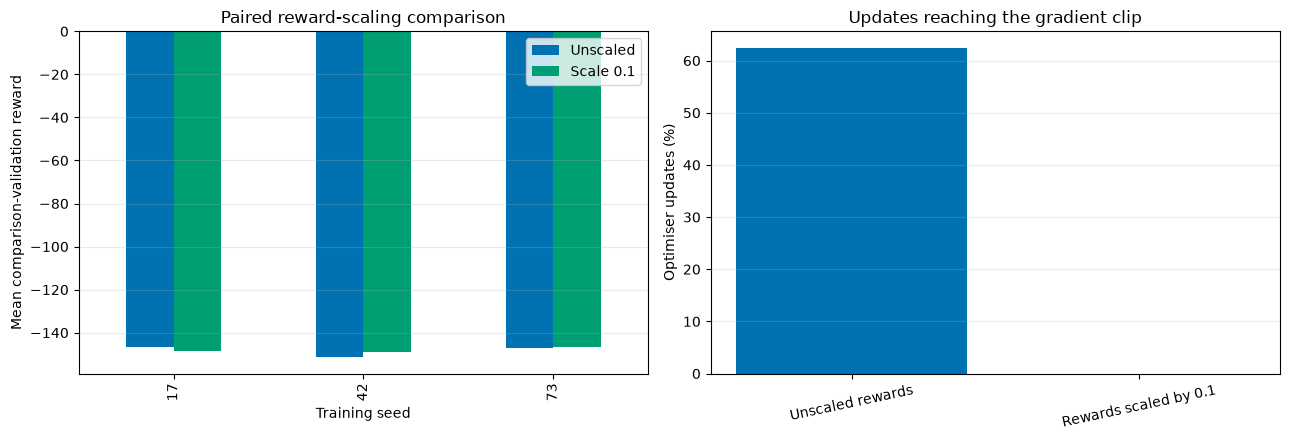

   training_seed  unscaled_reward  reward_scale_0_1  scaled_minus_unscaled
0             17          -146.66           -148.48                  -1.83
1             42          -151.42           -148.90                   2.52
2             73          -147.32           -146.41                   0.90

                strategy  three_seed_mean  between_seed_std  mean_td_loss  \
0       Unscaled rewards         -148.465             2.583         1.117   
1  Rewards scaled by 0.1         -147.931             1.332         0.017   

   mean_gradient_norm  clipped_update_fraction  upright_stable_fraction  
0              12.208                    0.625                    0.839  
1               0.694                    0.000                    0.850  

Reward scaling selected: False


In [24]:
REWARD_SCALE_CONFIG = FINAL_ACTION_CONFIG.copy()
REWARD_SCALE_CONFIG.update({
    "experiment_id": "Reward_Scale_0_1",
    "model_name": (
        f"{FINAL_ACTION_CONFIG['n_actions']}-action DQN "
        "with 0.1 reward scale"
    ),
    "reward_scale": 0.1,
    "save_progression": False,
})

(
    reward_scale_training,
    reward_scale_validation,
    reward_scale_evaluation,
    reward_scale_traces,
    reward_scale_verification,
    _,
) = run_dqn_group(REWARD_SCALE_CONFIG, TRAINING_SEEDS)

parent_scale_means = final_action_evaluation.groupby(
    "training_seed"
)["episode_reward"].mean()
scaled_seed_means = reward_scale_evaluation.groupby(
    "training_seed"
)["episode_reward"].mean()
paired_reward_scaling = pd.DataFrame({
    "training_seed": TRAINING_SEEDS,
    "unscaled_reward": [parent_scale_means[seed] for seed in TRAINING_SEEDS],
    "reward_scale_0_1": [scaled_seed_means[seed] for seed in TRAINING_SEEDS],
})
paired_reward_scaling["scaled_minus_unscaled"] = (
    paired_reward_scaling["reward_scale_0_1"]
    - paired_reward_scaling["unscaled_reward"]
)

parent_seed_spread = parent_scale_means.std(ddof=1)
scaled_seed_spread = scaled_seed_means.std(ddof=1)
scale_mean_gain = scaled_seed_means.mean() - parent_scale_means.mean()
scale_wins = int((paired_reward_scaling["scaled_minus_unscaled"] > 0).sum())
reward_scale_selected = (
    scale_mean_gain > 0
    and scale_wins == len(TRAINING_SEEDS)
    and scaled_seed_spread <= parent_seed_spread
)

def optimisation_summary(label, evaluation, training):
    seed_means = evaluation.groupby("training_seed")["episode_reward"].mean()
    return {
        "strategy": label,
        "three_seed_mean": seed_means.mean(),
        "between_seed_std": seed_means.std(ddof=1),
        "mean_td_loss": training["mean_td_loss"].mean(),
        "mean_gradient_norm": training["mean_gradient_norm"].mean(),
        "clipped_update_fraction": training["clipped_update_fraction"].mean(),
        "upright_stable_fraction": evaluation["upright_stable_fraction"].mean(),
    }

reward_scaling_summary_df = pd.DataFrame([
    optimisation_summary(
        "Unscaled rewards", final_action_evaluation, final_action_training
    ),
    optimisation_summary(
        "Rewards scaled by 0.1", reward_scale_evaluation, reward_scale_training
    ),
])

if reward_scale_selected:
    OPTIMIZED_CONFIG = REWARD_SCALE_CONFIG.copy()
    optimized_training = reward_scale_training.copy()
    optimized_validation = reward_scale_validation.copy()
    optimized_evaluation = reward_scale_evaluation.copy()
    optimized_traces = reward_scale_traces.copy()
    optimized_verification = reward_scale_verification.copy()
else:
    OPTIMIZED_CONFIG = FINAL_ACTION_CONFIG.copy()
    optimized_training = final_action_training.copy()
    optimized_validation = final_action_validation.copy()
    optimized_evaluation = final_action_evaluation.copy()
    optimized_traces = final_action_traces.copy()
    optimized_verification = final_action_verification.copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
paired_reward_scaling.set_index("training_seed")[[
    "unscaled_reward", "reward_scale_0_1"
]].plot(kind="bar", ax=axes[0], color=["#0072B2", "#009E73"])
axes[0].set(
    title="Paired reward-scaling comparison",
    xlabel="Training seed",
    ylabel="Mean comparison-validation reward",
)
axes[0].legend(["Unscaled", "Scale 0.1"])

axes[1].bar(
    reward_scaling_summary_df["strategy"],
    100 * reward_scaling_summary_df["clipped_update_fraction"],
    color=["#0072B2", "#009E73"],
)
axes[1].set(
    title="Updates reaching the gradient clip",
    ylabel="Optimiser updates (%)",
)
axes[1].tick_params(axis="x", rotation=12)
for axis in axes:
    axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "reward_scaling_stability.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

paired_reward_scaling.to_csv(
    TABLES_DIR / "reward_scaling_paired.csv", index=False
)
reward_scaling_summary_df.to_csv(
    TABLES_DIR / "reward_scaling_summary.csv", index=False
)
display(paired_reward_scaling.round(2))
display(reward_scaling_summary_df.round(3))
print("Reward scaling selected:", reward_scale_selected)

## 10.2 Results and Decision

- In the paired-reward chart, the bars are almost indistinguishable: scaling improves seeds `42` and `73` but regresses seed `17`. Mean reward changes from `-148.47` to `-147.93`, a gain of only `0.53`.
- The right chart shows a large optimisation change. Clipping falls from `62.5%` of updates to exactly `0.0%`; the zero-height scaled bar is a measured zero, not missing output. Mean gradient norm also falls from `12.21` to `0.69`.
- Between-seed spread falls from `2.58` to `1.33`, and upright-and-slow fraction rises from `83.9%` to `85.0%`. TD loss is not compared as a performance measure because reward scaling changes its units.

**Decision:** reject reward scaling. It fixes the gradient diagnostic but does not improve all paired policies, and the deployed reward gain is negligible compared with the observed run-to-run variation. Large gradients were therefore not the main control bottleneck in this experiment.


# 11. Duration Investigation

## 11.1 Does the 150-Episode Run Appear Too Short?

I do not double training automatically. A 300-episode follow-up is run only if at least two seeds select episode `150` as their best checkpoint and the aggregate checkpoint reward improves from episode `125` to `150`. Together, these observations would show that improvement is still occurring at the end of the current budget.

If the evidence supports an extension, the same seeds and settings receive 300 episodes. The longer model would still need a better paired mean without seed regressions, and its doubled interaction cost would be reported.


In [25]:
selected_best_rows = optimized_validation.loc[
    optimized_validation["is_best_checkpoint"]
].sort_values(["training_seed", "episode"]).groupby("training_seed").tail(1)
best_at_endpoint_count = int((selected_best_rows["episode"] == 150).sum())
validation_125 = optimized_validation.loc[
    optimized_validation["episode"] == 125, "validation_mean_reward"
].mean()
validation_150 = optimized_validation.loc[
    optimized_validation["episode"] == 150, "validation_mean_reward"
].mean()
duration_admitted = (
    best_at_endpoint_count >= 2 and validation_150 > validation_125
)

if duration_admitted:
    DURATION_CONFIG = OPTIMIZED_CONFIG.copy()
    DURATION_CONFIG.update({
        "experiment_id": f"{OPTIMIZED_CONFIG['experiment_id']}_300_Episodes",
        "model_name": "Selected DQN with 300 episodes",
        "episodes": 300,
        "save_progression": False,
    })
    (
        duration_training,
        duration_validation,
        duration_evaluation,
        duration_traces,
        duration_verification,
        _,
    ) = run_dqn_group(DURATION_CONFIG, TRAINING_SEEDS)

    duration_seed_means = duration_evaluation.groupby("training_seed")["episode_reward"].mean()
    parent_duration_means = optimized_evaluation.groupby("training_seed")["episode_reward"].mean()
    paired_duration = pd.DataFrame({
        "training_seed": TRAINING_SEEDS,
        "episodes_150": [parent_duration_means[seed] for seed in TRAINING_SEEDS],
        "episodes_300": [duration_seed_means[seed] for seed in TRAINING_SEEDS],
    })
    paired_duration["extended_minus_parent"] = (
        paired_duration["episodes_300"] - paired_duration["episodes_150"]
    )
    duration_confirmed = (
        paired_duration["episodes_300"].mean()
        > paired_duration["episodes_150"].mean()
        and (paired_duration["extended_minus_parent"] >= -1e-6).all()
    )
else:
    paired_duration = pd.DataFrame()
    duration_confirmed = False

if duration_confirmed:
    FINAL_CONFIG = DURATION_CONFIG.copy()
    final_training = duration_training.copy()
    final_validation = duration_validation.copy()
    final_evaluation = duration_evaluation.copy()
    final_traces = duration_traces.copy()
    final_verification = duration_verification.copy()
else:
    FINAL_CONFIG = OPTIMIZED_CONFIG.copy()
    final_training = optimized_training.copy()
    final_validation = optimized_validation.copy()
    final_evaluation = optimized_evaluation.copy()
    final_traces = optimized_traces.copy()
    final_verification = optimized_verification.copy()

duration_evidence = pd.DataFrame([{
    "best_at_episode_150_count": best_at_endpoint_count,
    "mean_validation_episode_125": validation_125,
    "mean_validation_episode_150": validation_150,
    "extension_justified": duration_admitted,
    "performance_configuration_selected": duration_confirmed,
    "efficient_configuration_episodes": OPTIMIZED_CONFIG["episodes"],
}])
duration_evidence.to_csv(TABLES_DIR / "duration_admission_evidence.csv", index=False)
if not paired_duration.empty:
    paired_duration.to_csv(TABLES_DIR / "duration_paired_results.csv", index=False)
display(duration_evidence.round(2))
if not paired_duration.empty:
    display(paired_duration.round(2))

with open(TABLES_DIR / "selected_default_config.json", "w", encoding="utf-8") as file:
    json.dump(FINAL_CONFIG, file, indent=2)

   best_at_episode_150_count  mean_validation_episode_125  \
0                          1                      -130.38   

   mean_validation_episode_150  extension_justified  \
0                      -131.19                False   

   performance_configuration_selected  efficient_configuration_episodes  
0                               False                               150  

## 11.2 Result and Decision

The table shows that only **1 of 3** runs selects episode 150. Aggregate checkpoint reward also changes from **-130.38** at episode 125 to **-131.19** at episode 150, which is slightly worse.

**Decision:** do not run the 300-episode extension. The default-gravity evidence does not show unfinished improvement at episode 150, so doubling the interactions is not justified.


# 12. Four-Gravity Investigation

## 12.1 Selected Design and Comparison Question

The selected default-gravity configuration is trained separately under `g = 10`, `0`, `-10` and `15`.

- The completed default-gravity runs are reused because repeating an identical deterministic run adds no comparison evidence.
- Every other gravity uses training seeds `17`, `42` and `73`, the same validation starts and the same environment-step budget.
- No gravity receives an individual learning rate, action grid, exploration schedule or duration.
- Mean greedy reward is interpreted within each environment because gravity changes the dynamics and attainable reward distribution.
- A matched random-discrete policy supplies a learning reference for each gravity. Reward components and representative animations explain the physical differences.

The held-out final starts remain unused here; this comparison uses validation evidence only.


In [26]:
gravity_results = {
    "Default gravity": {
        "config": FINAL_CONFIG.copy(),
        "training": final_training.copy(),
        "validation": final_validation.copy(),
        "evaluation": final_evaluation.copy(),
        "traces": final_traces.copy(),
        "verification": final_verification.copy(),
    }
}

for gravity_label, gravity_value, gravity_id in [
    ("Zero gravity", 0.0, "Gravity_Zero"),
    ("Anti-gravity", -10.0, "Gravity_Anti"),
    ("Stronger gravity", 15.0, "Gravity_Stronger"),
]:
    gravity_config = FINAL_CONFIG.copy()
    gravity_config.update({
        "experiment_id": gravity_id,
        "model_name": f"Frozen DQN under {gravity_label.lower()}",
        "gravity_label": gravity_label,
        "gravity": gravity_value,
        "save_progression": False,
    })
    result = run_dqn_group(gravity_config, TRAINING_SEEDS)
    gravity_results[gravity_label] = {
        "config": gravity_config,
        "training": result[0],
        "validation": result[1],
        "evaluation": result[2],
        "traces": result[3],
        "verification": result[4],
    }

gravity_reference_rows = []
for gravity_label, item in gravity_results.items():
    action_values = np.linspace(
        -2.0, 2.0, item["config"]["n_actions"], dtype=np.float32
    )
    reference = evaluate_reference_policy(
        "Random discrete policy",
        item["config"]["gravity"],
        action_values,
        COMPARISON_VALIDATION_SEEDS,
        item["config"]["max_steps"],
    )
    gravity_reference_rows.append({
        "gravity_label": gravity_label,
        "gravity": item["config"]["gravity"],
        "random_mean_reward": reference["episode_reward"].mean(),
        "random_episode_std": reference["episode_reward"].std(ddof=1),
    })

gravity_reference_df = pd.DataFrame(gravity_reference_rows)
random_reference_by_gravity = gravity_reference_df.set_index("gravity_label")

gravity_seed_rows = []
gravity_summary_rows = []
for gravity_label, item in gravity_results.items():
    evaluation = item["evaluation"]
    seed_means = evaluation.groupby("training_seed")["episode_reward"].mean()
    for training_seed, mean_reward in seed_means.items():
        gravity_seed_rows.append({
            "gravity_label": gravity_label,
            "gravity": item["config"]["gravity"],
            "training_seed": training_seed,
            "mean_reward": mean_reward,
        })
    gravity_summary_rows.append({
        "gravity_label": gravity_label,
        "gravity": item["config"]["gravity"],
        "mean_of_seed_means": seed_means.mean(),
        "between_seed_std": seed_means.std(ddof=1),
        "episode_std": evaluation["episode_reward"].std(ddof=1),
        "mean_abs_angle_degrees": evaluation["mean_abs_angle_degrees"].mean(),
        "rms_angular_velocity": evaluation["rms_angular_velocity"].mean(),
        "mean_abs_torque": evaluation["mean_abs_torque"].mean(),
        "upright_stable_fraction": evaluation["upright_stable_fraction"].mean(),
        "angle_penalty": evaluation["angle_penalty"].mean(),
        "velocity_penalty": evaluation["velocity_penalty"].mean(),
        "torque_penalty": evaluation["torque_penalty"].mean(),
        "random_mean_reward": random_reference_by_gravity.loc[gravity_label, "random_mean_reward"],
        "random_episode_std": random_reference_by_gravity.loc[gravity_label, "random_episode_std"],
        "learned_minus_random": (
            seed_means.mean()
            - random_reference_by_gravity.loc[
                gravity_label,
                "random_mean_reward",
            ]
        ),
    })

gravity_seed_df = pd.DataFrame(gravity_seed_rows)
gravity_summary_df = pd.DataFrame(gravity_summary_rows)
gravity_seed_df.to_csv(TABLES_DIR / "four_gravity_seed_results.csv", index=False)
gravity_reference_df.to_csv(TABLES_DIR / "four_gravity_random_references.csv", index=False)
gravity_summary_df.to_csv(TABLES_DIR / "four_gravity_summary.csv", index=False)
display(gravity_seed_df.round(2))
display(gravity_reference_df.round(2))
display(gravity_summary_df.round(3))

Starting Gravity_Zero, seed 17


  Validation at episode 025 | seed 17 | mean -40.16 | SD 50.23 | checkpoint saved


  Validation at episode 050 | seed 17 | mean -44.14 | SD 44.87 | checkpoint not replaced


  Validation at episode 075 | seed 17 | mean -50.11 | SD 45.31 | checkpoint not replaced


  Validation at episode 100 | seed 17 | mean -43.56 | SD 48.58 | checkpoint not replaced


  Validation at episode 125 | seed 17 | mean -42.12 | SD 50.10 | checkpoint not replaced


... (57 outputs left out)

Completed Gravity_Stronger, seed 73: mean validation reward -171.99


       gravity_label  gravity  training_seed  mean_reward
0    Default gravity     10.0             17      -146.66
1    Default gravity     10.0             42      -151.42
2    Default gravity     10.0             73      -147.32
3       Zero gravity      0.0             17       -38.19
4       Zero gravity      0.0             42       -34.43
5       Zero gravity      0.0             73       -34.45
6       Anti-gravity    -10.0             17       -39.19
7       Anti-gravity    -10.0             42       -40.32
8       Anti-gravity    -10.0             73       -43.28
9   Stronger gravity     15.0             17      -181.32
10  Stronger gravity     15.0             42      -178.67
11  Stronger gravity     15.0             73      -171.99

      gravity_label  gravity  random_mean_reward  random_episode_std
0   Default gravity     10.0            -1195.05              266.18
1      Zero gravity      0.0             -775.08              220.24
2      Anti-gravity    -10.0             -604.05              403.64
3  Stronger gravity     15.0            -1421.20              196.17

      gravity_label  gravity  mean_of_seed_means  between_seed_std  \
0   Default gravity     10.0            -148.465             2.583   
1      Zero gravity      0.0             -35.688             2.163   
2      Anti-gravity    -10.0             -40.930             2.109   
3  Stronger gravity     15.0            -177.324             4.806   

   episode_std  mean_abs_angle_degrees  rms_angular_velocity  mean_abs_torque  \
0       80.827                  17.937                 1.477            1.436   
1       38.239                   9.440                 0.437            0.324   
2       44.787                   7.154                 0.782            0.597   
3      105.752                  16.499                 1.780            1.510   

   upright_stable_fraction  angle_penalty  velocity_penalty  torque_penalty  \
0                    0.839         99.940            48.016           0.509   
1                    0.881         30.779             4.812           0.097   
2     

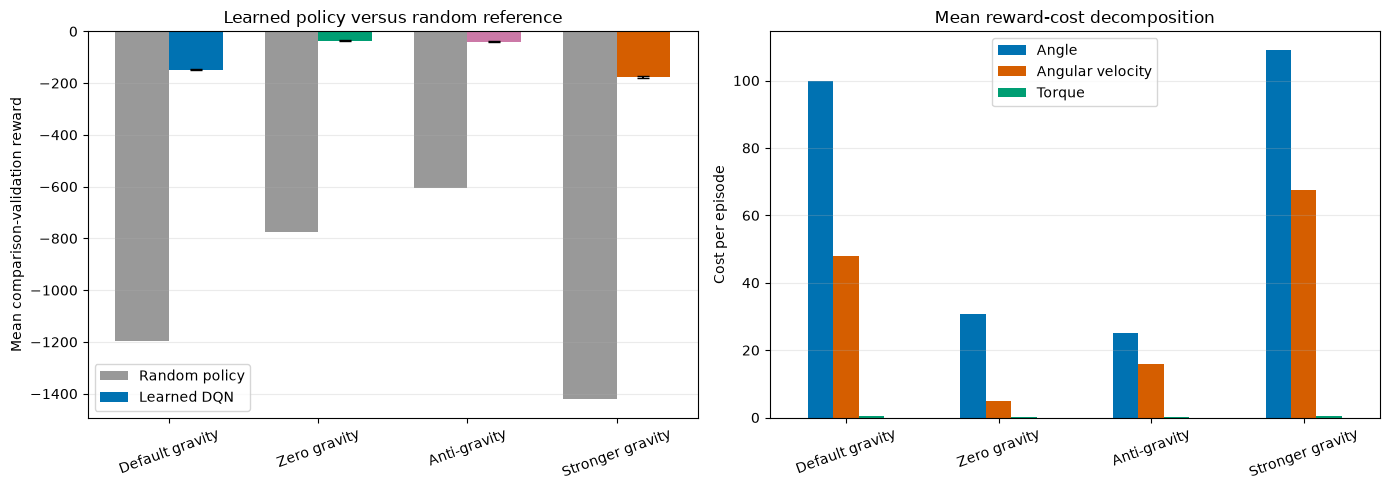

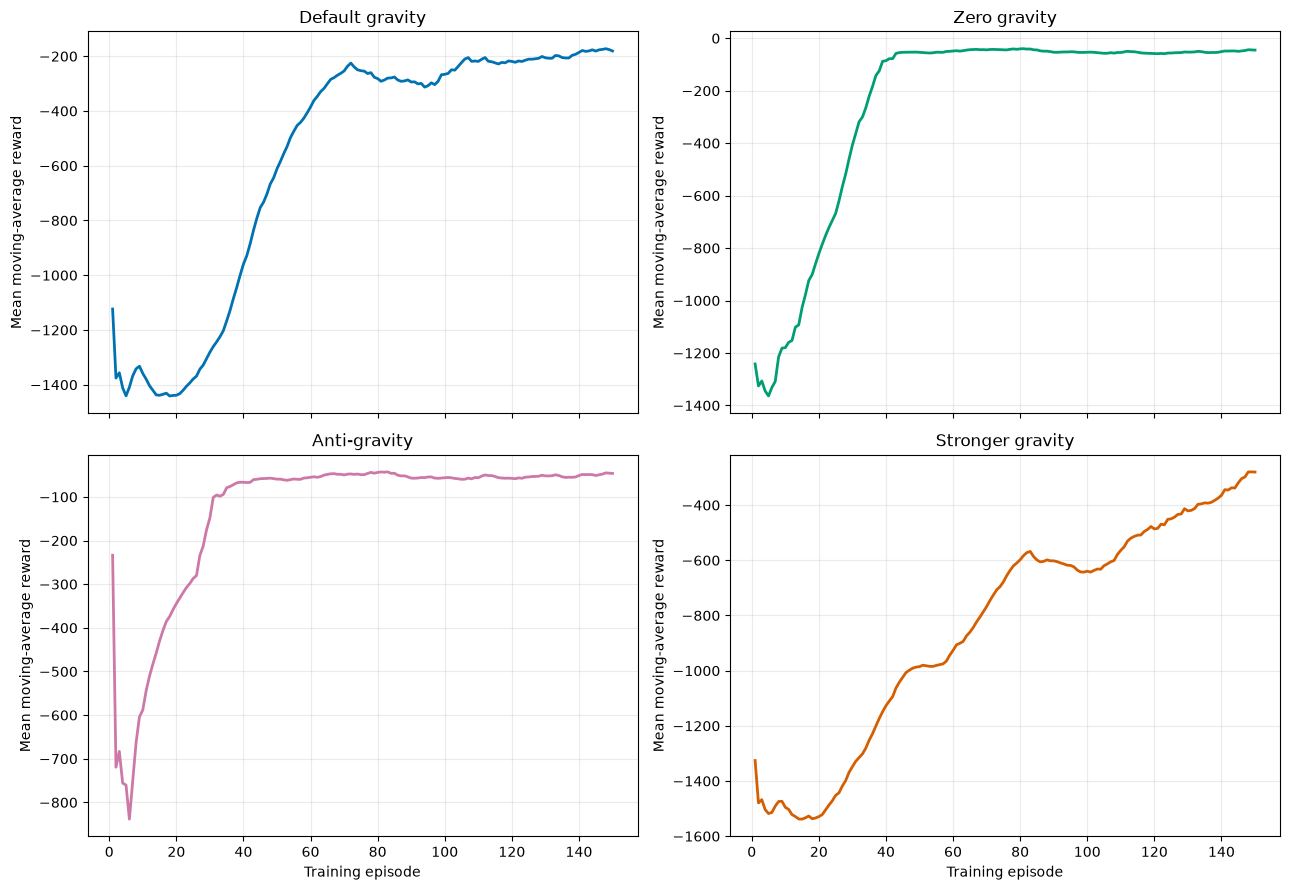

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_summary = gravity_summary_df.set_index("gravity_label").loc[
    ["Default gravity", "Zero gravity", "Anti-gravity", "Stronger gravity"]
].reset_index()
colours = ["#0072B2", "#009E73", "#CC79A7", "#D55E00"]
x = np.arange(len(plot_summary))
width = 0.36
axes[0].bar(
    x - width / 2,
    plot_summary["random_mean_reward"],
    width,
    color="#999999",
    label="Random policy",
)
axes[0].bar(
    x + width / 2,
    plot_summary["mean_of_seed_means"],
    width,
    yerr=plot_summary["between_seed_std"],
    capsize=4,
    color=colours,
    label="Learned DQN",
)
axes[0].set(
    title="Learned policy versus random reference",
    ylabel="Mean comparison-validation reward",
    xticks=x,
    xticklabels=plot_summary["gravity_label"],
)
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend()

penalty_plot = plot_summary.set_index("gravity_label")[[
    "angle_penalty", "velocity_penalty", "torque_penalty"
]].rename(columns={
    "angle_penalty": "Angle",
    "velocity_penalty": "Angular velocity",
    "torque_penalty": "Torque",
})
penalty_plot.plot(kind="bar", ax=axes[1], color=["#0072B2", "#D55E00", "#009E73"])
axes[1].set(title="Mean reward-cost decomposition", xlabel="", ylabel="Cost per episode")
axes[1].tick_params(axis="x", rotation=20)
for axis in axes:
    axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "four_gravity_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
for axis, (gravity_label, item), colour in zip(axes.flat, gravity_results.items(), colours):
    curves = []
    for seed in TRAINING_SEEDS:
        seed_training = item["training"].loc[
            item["training"]["training_seed"] == seed
        ].copy()
        seed_training["moving_average"] = seed_training["episode_reward"].rolling(
            25, min_periods=1
        ).mean()
        curves.append(seed_training.set_index("episode")["moving_average"])
    mean_curve = pd.concat(curves, axis=1).mean(axis=1)
    axis.plot(mean_curve.index, mean_curve.values, color=colour, linewidth=2)
    axis.set(title=gravity_label, ylabel="Mean moving-average reward")
    axis.grid(alpha=0.25)
for axis in axes[-1]:
    axis.set_xlabel("Training episode")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "four_gravity_learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## 12.2 Learning-Curve and Validation Interpretation

- Zero and anti-gravity improve rapidly and settle near their final level by roughly episodes 35 to 45. Default gravity improves mainly between episodes 30 and 70, has a smaller regression around episodes 80 to 100, and then stabilises.
- Stronger gravity learns more slowly. Its moving average is still rising near episode 150, unlike the other three curves. I keep the 150-episode budget for an equal comparison, but this indicates that stronger gravity may be under-trained and is recorded as a limitation rather than tuned separately.
- In the learned-versus-random chart, every DQN is far above its matched random reference. The cost-decomposition panel shows angle as the largest cost for all four settings, with stronger gravity also carrying the largest velocity cost. Torque cost appears small because the environment multiplies it by `0.001`; actual torque use is examined separately in the final physical diagnostics.

## 12.3 Matched Gravity Animations

For each gravity, I select the training seed closest to that gravity's three-seed mean and then the validation episode closest to that seed's median reward. This gives a representative rather than best-case demonstration. Every animation reloads the corresponding H5 checkpoint and applies a greedy policy for all 200 steps.


In [28]:
gravity_animation_rows = []
for gravity_label, item in gravity_results.items():
    evaluation = item["evaluation"]
    seed_means = evaluation.groupby("training_seed")["episode_reward"].mean()
    gravity_mean = seed_means.mean()
    representative_seed = int((seed_means - gravity_mean).abs().idxmin())
    seed_episodes = evaluation.loc[evaluation["training_seed"] == representative_seed]
    median_reward = seed_episodes["episode_reward"].median()
    representative_row = seed_episodes.iloc[
        (seed_episodes["episode_reward"] - median_reward).abs().argmin()
    ]
    representative_eval_seed = int(representative_row["evaluation_seed"])

    model = build_q_network(
        item["config"]["n_actions"], tuple(item["config"]["hidden_units"])
    )
    weight_path = WEIGHTS_DIR / (
        f"Part_B_{item['config']['experiment_id']}_seed{representative_seed}.weights.h5"
    )
    model.load_weights(weight_path)
    animation_path = ANIMATIONS_DIR / (
        "gravity_"
        f"{str(item['config']['gravity']).replace('-', 'minus').replace('.', '_')}"
        "_representative.gif"
    )
    record = save_policy_animation(
        model,
        item["config"]["gravity"],
        np.linspace(-2.0, 2.0, item["config"]["n_actions"], dtype=np.float32),
        representative_eval_seed,
        animation_path,
        item["config"]["max_steps"],
        frame_stride=2,
    )
    assert np.isclose(record["episode_reward"], representative_row["episode_reward"], atol=1e-6)
    record.update({
        "gravity_label": gravity_label,
        "gravity": item["config"]["gravity"],
        "training_seed": representative_seed,
        "weight_file": weight_path.name,
    })
    gravity_animation_rows.append(record)
    print(
        f"{gravity_label}: seed {representative_seed}, "
        f"evaluation seed {representative_eval_seed}, reward {record['episode_reward']:.2f}"
    )
    display_gif(animation_path, f"Representative DQN policy under {gravity_label.lower()}")

gravity_animation_df = pd.DataFrame(gravity_animation_rows)
gravity_animation_df.to_csv(TABLES_DIR / "four_gravity_animations.csv", index=False)
display(gravity_animation_df.round(2))

Default gravity: seed 73, evaluation seed 11009, reward -121.51


<IPython.core.display.HTML object>

Zero gravity: seed 73, evaluation seed 11013, reward -23.09


<IPython.core.display.HTML object>

Anti-gravity: seed 42, evaluation seed 11001, reward -25.00


<IPython.core.display.HTML object>

Stronger gravity: seed 42, evaluation seed 11009, reward -121.64


<IPython.core.display.HTML object>

   evaluation_seed  episode_reward  environment_steps  displayed_frames  \
0            11009         -121.51                200               100   
1            11013          -23.09                200               100   
2            11001          -25.00                200               100   
3            11009         -121.64                200               100   

                         animation_file     gravity_label  gravity  \
0       gravity_10_0_representative.gif   Default gravity     10.0   
1        gravity_0_0_representative.gif      Zero gravity      0.0   
2  gravity_minus10_0_representative.gif      Anti-gravity    -10.0   
3       gravity_15_0_representative.gif  Stronger gravity     15.0   

   training_seed                                        weight_file  
0             73      Part_B_Default_DQN_seed73.weights.h5  
1             73     Part_B_Gravity_Zero_seed73.weights.h5  
2             42     Part_B_Gravity_Anti_seed42.weights.h5  
3             42  Pa

## 12.4 Gravity Results and Decision

Results are reported in the order default, zero, anti- and stronger gravity.

- Mean validation rewards are `-148.47`, `-35.69`, `-40.93` and `-177.32`; between-seed standard deviations are `2.58`, `2.16`, `2.11` and `4.81`.
- Matched random policies score `-1195.05`, `-775.08`, `-604.05` and `-1421.20`. The large gap under every gravity confirms that each network learned a control policy.
- Zero gravity needs the least movement and torque. Anti-gravity has the smallest angle cost but more velocity cost than zero gravity. Stronger gravity has the largest velocity and torque costs, explaining its lower reward.
- Representative animation rewards are `-121.51`, `-23.09`, `-25.00` and `-121.64`. These episodes are selected near their seed distributions' medians, not for visual quality.

**Decision:** retain the same five-action, constant-epsilon DQN for all four settings. Tuning stronger gravity separately might improve it, but would no longer answer the equal-design, equal-budget comparison.


# 13. Final Evaluation and Gravity-Level Analysis

## 13.1 Final Evaluation Setup

All three trained policies for each gravity are evaluated greedily on the same twenty held-out starts. Their three seed means are averaged so each independently trained policy has equal weight.

Separately, the highest-validation seed for each gravity is selected for the single exported H5 file and representative demonstration. That selection does not reduce the reported final result to one favourable network.

- **Primary result:** mean of the three training-seed means.
- **Reliability:** between-training-seed spread and all 60 episode rewards per gravity.
- **Behaviour:** reward components, angle, angular velocity, torque and upright-and-slow fraction.
- **Learning check:** random-discrete and zero-torque policies on the same final starts.

The held-out results are used for reporting only; no configuration changes follow them.


In [29]:
with open(TABLES_DIR / "selected_default_config.json", encoding="utf-8") as file:
    FINAL_SELECTED_CONFIG = json.load(file)

FINAL_GRAVITY_SPECS = {
    "Default gravity": {
        "gravity": 10.0,
        "experiment_id": FINAL_SELECTED_CONFIG["experiment_id"],
        "export_slug": "Default_Gravity",
    },
    "Zero gravity": {
        "gravity": 0.0,
        "experiment_id": "Gravity_Zero",
        "export_slug": "Zero_Gravity",
    },
    "Anti-gravity": {
        "gravity": -10.0,
        "experiment_id": "Gravity_Anti",
        "export_slug": "Anti_Gravity",
    },
    "Stronger gravity": {
        "gravity": 15.0,
        "experiment_id": "Gravity_Stronger",
        "export_slug": "Stronger_Gravity",
    },
}

final_action_values = np.linspace(
    -2.0, 2.0, FINAL_SELECTED_CONFIG["n_actions"], dtype=np.float32
)
comparison_gravity_seeds = pd.read_csv(
    TABLES_DIR / "four_gravity_seed_results.csv"
)

selected_model_rows = []
for gravity_label, specification in FINAL_GRAVITY_SPECS.items():
    gravity_validation = comparison_gravity_seeds.loc[
        comparison_gravity_seeds["gravity_label"] == gravity_label
    ]
    selected_row = gravity_validation.loc[
        gravity_validation["mean_reward"].idxmax()
    ]
    selected_seed = int(selected_row["training_seed"])
    selected_model_rows.append({
        "gravity_label": gravity_label,
        "gravity": specification["gravity"],
        "selected_training_seed": selected_seed,
        "selection_evidence": "Highest mean reward on comparison-validation seeds",
        "validation_mean_reward": selected_row["mean_reward"],
        "source_weight_file": (
            f"Part_B_{specification['experiment_id']}_"
            f"seed{selected_seed}.weights.h5"
        ),
    })

selected_models_df = pd.DataFrame(selected_model_rows)
selected_models_df.to_csv(
    TABLES_DIR / "validation_selected_models.csv", index=False
)
display(selected_models_df.round(2))


      gravity_label  gravity  selected_training_seed  \
0   Default gravity     10.0                      17   
1      Zero gravity      0.0                      42   
2      Anti-gravity    -10.0                      17   
3  Stronger gravity     15.0                      73   

                                  selection_evidence  validation_mean_reward  \
0  Highest mean reward on comparison-validation s...                 -146.66   
1  Highest mean reward on comparison-validation s...                  -34.43   
2  Highest mean reward on comparison-validation s...                  -39.19   
3  Highest mean reward on comparison-validation s...                 -171.99   

                                  source_weight_file  
0      Part_B_Default_DQN_seed17.weights.h5  
1     Part_B_Gravity_Zero_seed42.weights.h5  
2     Part_B_Gravity_Anti_seed17.weights.h5  
3  Part_B_Gravity_Stronger_seed73.weight...  

### Selected Export Models

Validation selects seeds `17`, `42`, `17` and `73` for the default, zero, anti- and stronger-gravity H5 exports. These rows choose one file and one demonstration per gravity only. The final performance estimate below still evaluates and averages all three trained seed policies.


In [30]:
final_episode_frames = []
final_trace_frames = []

for gravity_label, specification in FINAL_GRAVITY_SPECS.items():
    for training_seed in TRAINING_SEEDS:
        model = build_q_network(
            FINAL_SELECTED_CONFIG["n_actions"],
            tuple(FINAL_SELECTED_CONFIG["hidden_units"]),
        )
        weight_path = WEIGHTS_DIR / (
            f"Part_B_{specification['experiment_id']}_"
            f"seed{training_seed}.weights.h5"
        )
        model.load_weights(weight_path)
        episode_results, traces = evaluate_dqn(
            model,
            specification["gravity"],
            final_action_values,
            FINAL_TEST_SEEDS,
            FINAL_SELECTED_CONFIG["max_steps"],
        )
        for frame in (episode_results, traces):
            frame.insert(0, "gravity_label", gravity_label)
            frame.insert(1, "gravity", specification["gravity"])
            frame.insert(2, "training_seed", training_seed)
        final_episode_frames.append(episode_results)
        final_trace_frames.append(traces)

final_test_episodes_df = pd.concat(final_episode_frames, ignore_index=True)
final_test_traces_df = pd.concat(final_trace_frames, ignore_index=True)

final_reference_frames = []
for gravity_label, specification in FINAL_GRAVITY_SPECS.items():
    for policy_name in ("Random discrete policy", "Zero-torque policy"):
        reference = evaluate_reference_policy(
            policy_name,
            specification["gravity"],
            final_action_values,
            FINAL_TEST_SEEDS,
            FINAL_SELECTED_CONFIG["max_steps"],
        )
        reference.insert(0, "gravity_label", gravity_label)
        reference.insert(1, "gravity", specification["gravity"])
        final_reference_frames.append(reference)

final_reference_episodes_df = pd.concat(final_reference_frames, ignore_index=True)

final_test_seed_summary_df = (
    final_test_episodes_df.groupby(
        ["gravity_label", "gravity", "training_seed"], sort=False
    )
    .agg(
        mean_reward=("episode_reward", "mean"),
        episode_std=("episode_reward", "std"),
        median_reward=("episode_reward", "median"),
        worst_reward=("episode_reward", "min"),
        best_reward=("episode_reward", "max"),
        mean_abs_angle_degrees=("mean_abs_angle_degrees", "mean"),
        rms_angular_velocity=("rms_angular_velocity", "mean"),
        mean_abs_torque=("mean_abs_torque", "mean"),
        upright_stable_fraction=("upright_stable_fraction", "mean"),
    )
    .reset_index()
)

gravity_seed_statistics = (
    final_test_seed_summary_df.groupby(
        ["gravity_label", "gravity"], sort=False
    )["mean_reward"]
    .agg(mean_of_seed_means="mean", between_seed_std="std")
    .reset_index()
)
gravity_episode_statistics = (
    final_test_episodes_df.groupby(
        ["gravity_label", "gravity"], sort=False
    )
    .agg(
        episode_std=("episode_reward", "std"),
        median_reward=("episode_reward", "median"),
        worst_reward=("episode_reward", "min"),
        best_reward=("episode_reward", "max"),
        mean_abs_angle_degrees=("mean_abs_angle_degrees", "mean"),
        rms_angular_velocity=("rms_angular_velocity", "mean"),
        mean_abs_torque=("mean_abs_torque", "mean"),
        upright_stable_fraction=("upright_stable_fraction", "mean"),
        angle_penalty=("angle_penalty", "mean"),
        velocity_penalty=("velocity_penalty", "mean"),
        torque_penalty=("torque_penalty", "mean"),
    )
    .reset_index()
)
final_test_gravity_summary_df = gravity_seed_statistics.merge(
    gravity_episode_statistics,
    on=["gravity_label", "gravity"],
)

final_reference_summary_df = (
    final_reference_episodes_df.groupby(
        ["gravity_label", "gravity", "policy"], sort=False
    )["episode_reward"]
    .agg(mean_reward="mean", episode_std="std", median_reward="median")
    .reset_index()
)

validation_test_seed_df = comparison_gravity_seeds.rename(
    columns={"mean_reward": "validation_mean_reward"}
).merge(
    final_test_seed_summary_df[[
        "gravity_label", "gravity", "training_seed", "mean_reward"
    ]].rename(columns={"mean_reward": "final_test_mean_reward"}),
    on=["gravity_label", "gravity", "training_seed"],
    how="inner",
)
validation_test_seed_df["test_minus_validation"] = (
    validation_test_seed_df["final_test_mean_reward"]
    - validation_test_seed_df["validation_mean_reward"]
)

final_test_episodes_df.to_csv(
    TABLES_DIR / "final_test_episode_results.csv", index=False
)
final_test_traces_df.to_csv(
    TABLES_DIR / "final_test_traces.csv", index=False
)
final_test_seed_summary_df.to_csv(
    TABLES_DIR / "final_test_seed_summary.csv", index=False
)
final_test_gravity_summary_df.to_csv(
    TABLES_DIR / "final_test_gravity_summary.csv", index=False
)
final_reference_episodes_df.to_csv(
    TABLES_DIR / "final_test_reference_episodes.csv", index=False
)
final_reference_summary_df.to_csv(
    TABLES_DIR / "final_test_reference_summary.csv", index=False
)
validation_test_seed_df.to_csv(
    TABLES_DIR / "validation_to_final_test.csv", index=False
)

display(final_test_seed_summary_df.round(2))
display(final_test_gravity_summary_df.round(3))
display(final_reference_summary_df.round(2))


       gravity_label  gravity  training_seed  mean_reward  episode_std  \
0    Default gravity     10.0             17      -167.61        98.10   
1    Default gravity     10.0             42      -167.51        99.08   
2    Default gravity     10.0             73      -143.52        73.32   
3       Zero gravity      0.0             17       -42.22        37.38   
4       Zero gravity      0.0             42       -41.64        38.06   
5       Zero gravity      0.0             73       -40.34        34.90   
6       Anti-gravity    -10.0             17       -49.58        55.74   
7       Anti-gravity    -10.0             42       -54.47        66.38   
8       Anti-gravity    -10.0             73       -45.14        42.31   
9   Stronger gravity     15.0             17      -200.20       127.70   
10  Stronger gravity     15.0             42      -174.00       117.88   
11  Stronger gravity     15.0             73      -191.69       115.93   

    median_reward  worst_reward  best

      gravity_label  gravity  mean_of_seed_means  between_seed_std  \
0   Default gravity     10.0            -159.549            13.879   
1      Zero gravity      0.0             -41.401             0.963   
2      Anti-gravity    -10.0             -49.729             4.665   
3  Stronger gravity     15.0            -188.627            13.366   

   episode_std  median_reward  worst_reward  best_reward  \
0       90.121       -126.828      -371.388       -0.990   
1       36.185        -37.932      -125.087       -0.762   
2       54.870        -37.428      -252.924       -0.628   
3      119.062       -122.772      -446.114       -1.137   

   mean_abs_angle_degrees  rms_angular_velocity  mean_abs_torque  \
0                  19.013                 1.501            1.433   
1                   9.832                 0.448            0.368   
2                   8.119                 0.816            0.607   
3                  17.514                 1.772            1.519   

   upri

      gravity_label  gravity                  policy  mean_reward  \
0   Default gravity     10.0  Random discrete policy     -1232.03   
1   Default gravity     10.0      Zero-torque policy     -1227.03   
2      Zero gravity      0.0  Random discrete policy      -719.32   
3      Zero gravity      0.0      Zero-torque policy      -709.44   
4      Anti-gravity    -10.0  Random discrete policy      -612.30   
5      Anti-gravity    -10.0      Zero-torque policy      -594.44   
6  Stronger gravity     15.0  Random discrete policy     -1445.33   
7  Stronger gravity     15.0      Zero-torque policy     -1407.09   

   episode_std  median_reward  
0       306.36       -1154.20  
1       334.43       -1253.63  
2       187.50        -696.84  
3       355.35        -744.25  
4       467.49        -437.00  
5       453.22        -586.93  
6       182.32       -1377.53  
7       184.56       -1368.35  

## 13.2 Held-Out Results

- Final means across the three trained policies are `-159.55`, `-41.40`, `-49.73` and `-188.63` for default, zero, anti- and stronger gravity. Between-seed standard deviations are `13.88`, `0.96`, `4.66` and `13.37`.
- Relative to comparison validation, the means fall by `11.08`, `5.71`, `8.80` and `11.30` points. The direction is consistent across all four settings, showing modest development optimism, but no model is changed after this observation.
- Episode standard deviations are `90.12`, `36.18`, `54.87` and `119.06`. Variation across starting states is therefore much larger than variation among the three trained policies, especially for default and stronger gravity.
- Every learned policy remains far above both non-learning controls. Default gravity scores `-159.55` against `-1232.03` random and `-1227.03` zero torque; stronger gravity scores `-188.63` against `-1445.33` and `-1407.09`.

These held-out means replace the more optimistic validation values in the final report.


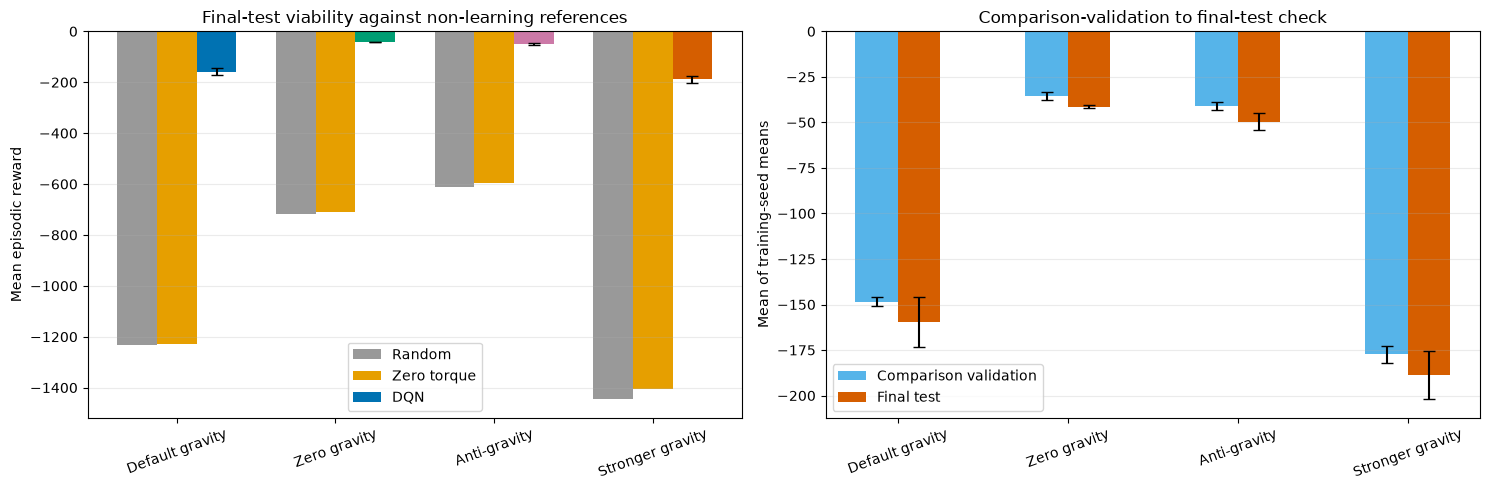

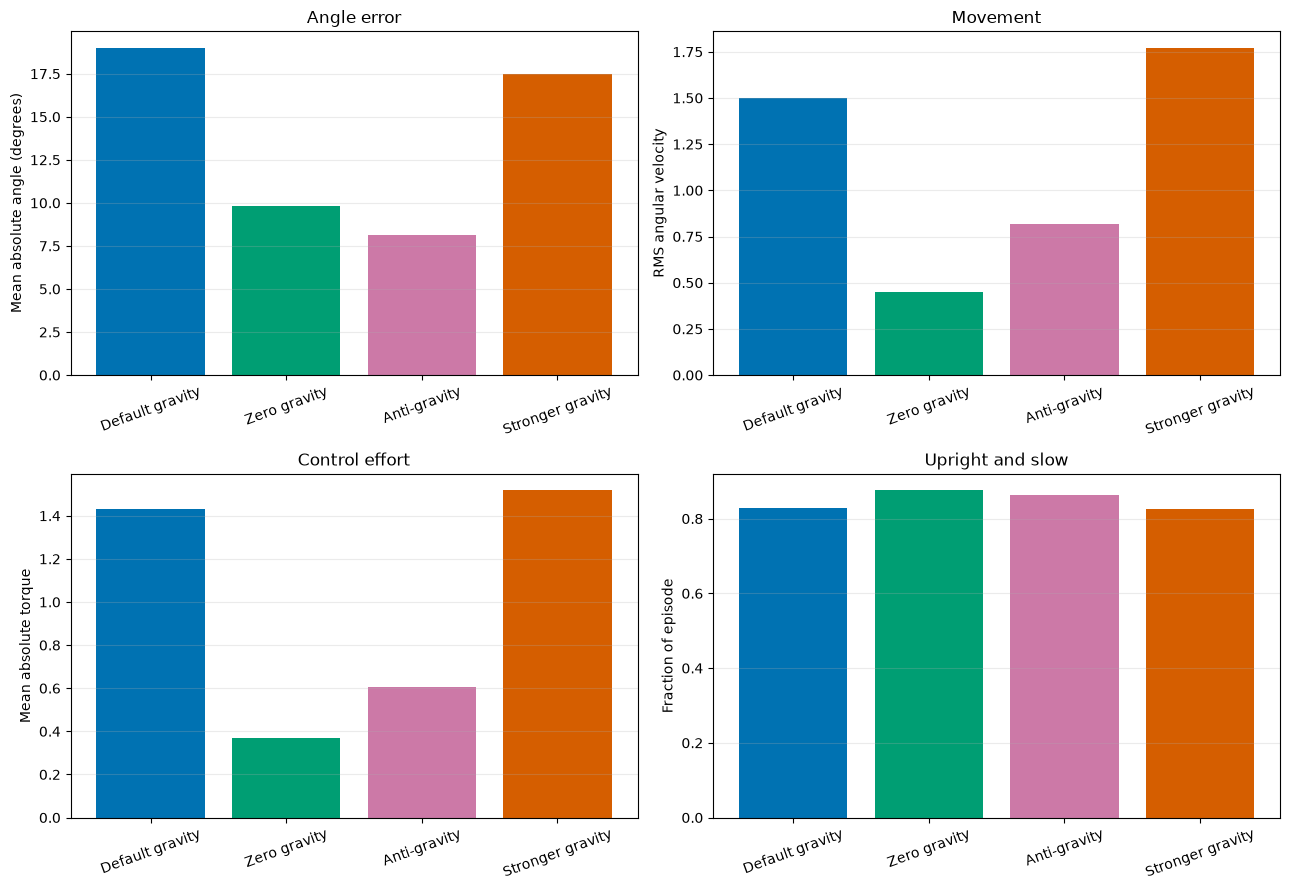

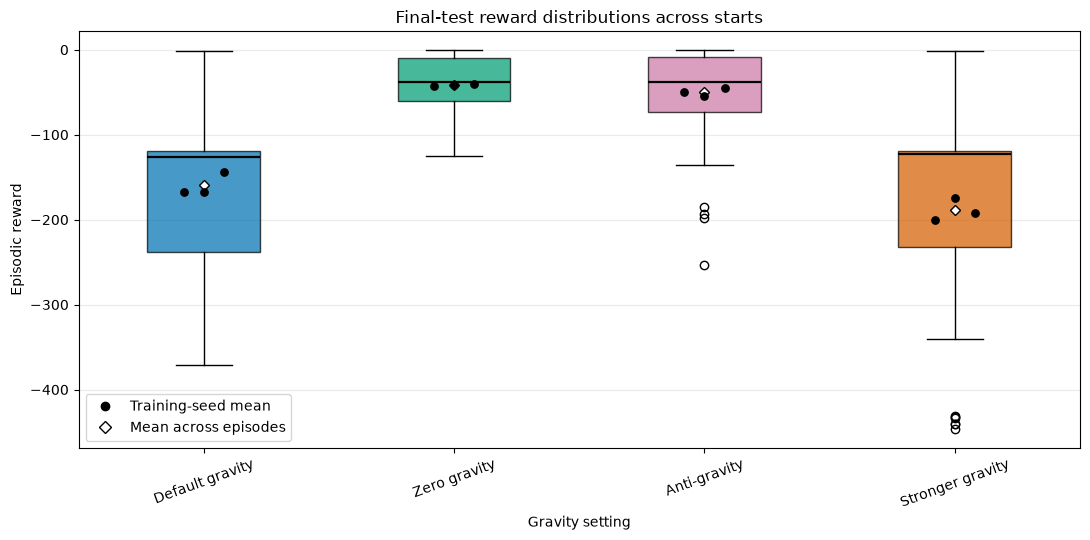

In [31]:
gravity_order = list(FINAL_GRAVITY_SPECS)
gravity_colours = ["#0072B2", "#009E73", "#CC79A7", "#D55E00"]

plot_final = final_test_gravity_summary_df.set_index("gravity_label").loc[
    gravity_order
].reset_index()
plot_references = final_reference_summary_df.pivot(
    index="gravity_label", columns="policy", values="mean_reward"
).loc[gravity_order]
validation_gravity_summary = (
    comparison_gravity_seeds.groupby("gravity_label")["mean_reward"]
    .agg(validation_mean="mean", validation_seed_std="std")
    .loc[gravity_order]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(gravity_order))
width = 0.25
axes[0].bar(
    x - width,
    plot_references["Random discrete policy"],
    width,
    label="Random",
    color="#999999",
)
axes[0].bar(
    x,
    plot_references["Zero-torque policy"],
    width,
    label="Zero torque",
    color="#E69F00",
)
axes[0].bar(
    x + width,
    plot_final["mean_of_seed_means"],
    width,
    yerr=plot_final["between_seed_std"],
    capsize=4,
    label="DQN",
    color=gravity_colours,
)
axes[0].set(
    title="Final-test viability against non-learning references",
    ylabel="Mean episodic reward",
    xticks=x,
    xticklabels=gravity_order,
)
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend()

axes[1].bar(
    x - width / 2,
    validation_gravity_summary["validation_mean"],
    width,
    yerr=validation_gravity_summary["validation_seed_std"],
    capsize=4,
    label="Comparison validation",
    color="#56B4E9",
)
axes[1].bar(
    x + width / 2,
    plot_final["mean_of_seed_means"],
    width,
    yerr=plot_final["between_seed_std"],
    capsize=4,
    label="Final test",
    color="#D55E00",
)
axes[1].set(
    title="Comparison-validation to final-test check",
    ylabel="Mean of training-seed means",
    xticks=x,
    xticklabels=gravity_order,
)
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend()

for axis in axes:
    axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "final_test_reward_and_generalisation.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
diagnostics = [
    ("mean_abs_angle_degrees", "Mean absolute angle (degrees)", "Angle error"),
    ("rms_angular_velocity", "RMS angular velocity", "Movement"),
    ("mean_abs_torque", "Mean absolute torque", "Control effort"),
    ("upright_stable_fraction", "Fraction of episode", "Upright and slow"),
]
for axis, (column, ylabel, title), colour in zip(
    axes.flat, diagnostics, gravity_colours
):
    axis.bar(gravity_order, plot_final[column], color=gravity_colours)
    axis.set(title=title, ylabel=ylabel)
    axis.tick_params(axis="x", rotation=20)
    axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "final_test_physical_diagnostics.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()


distribution_data = [
    final_test_episodes_df.loc[
        final_test_episodes_df["gravity_label"] == gravity_label,
        "episode_reward",
    ].to_numpy()
    for gravity_label in gravity_order
]
fig, axis = plt.subplots(figsize=(11, 5.5))
boxplot = axis.boxplot(
    distribution_data,
    tick_labels=gravity_order,
    showmeans=True,
    patch_artist=True,
    medianprops={"color": "black", "linewidth": 1.6},
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 5,
    },
)
for patch, colour in zip(boxplot["boxes"], gravity_colours):
    patch.set_facecolor(colour)
    patch.set_alpha(0.72)

for position, gravity_label in enumerate(gravity_order, start=1):
    seed_values = final_test_seed_summary_df.loc[
        final_test_seed_summary_df["gravity_label"] == gravity_label,
        "mean_reward",
    ].to_numpy()
    offsets = np.linspace(-0.08, 0.08, len(seed_values))
    axis.scatter(
        position + offsets,
        seed_values,
        color="black",
        s=28,
        zorder=3,
        label="Training-seed mean" if position == 1 else None,
    )

axis.set(
    title="Final-test reward distributions across starts",
    xlabel="Gravity setting",
    ylabel="Episodic reward",
)
axis.tick_params(axis="x", rotation=20)
axis.grid(axis="y", alpha=0.25)
from matplotlib.lines import Line2D
axis.legend(handles=[
    Line2D([0], [0], marker="o", color="none", markerfacecolor="black", label="Training-seed mean"),
    Line2D(
        [0],
        [0],
        marker="D",
        color="none",
        markerfacecolor="white",
        markeredgecolor="black",
        label="Mean across episodes",
    ),
])
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "final_test_reward_distributions.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()


## 13.3 Chart Interpretation and Gravity-Level Analysis

### Reward and Generalisation

- In the left reward panel, the DQN bar is separated clearly from both non-learning controls for every gravity. Zero torque is not a useful shortcut even when gravity is zero; its mean remains near `-710` because an initially displaced pendulum does not move to upright by itself.
- In the right panel, every final-test bar is below its validation bar. The larger error bars for default and stronger gravity show that their final result depends more strongly on which network seed is trained.
- The box plot contains all 60 final episodes per gravity. The black seed-mean points are much closer together than the full boxes and whiskers, confirming that difficult starting states dominate variability. Default and stronger gravity have long lower tails, while anti-gravity contains several isolated poor starts. In each case the mean diamond lies below the median because these difficult episodes pull the average down.

### Physical Diagnostics

- **Zero gravity:** best final mean at `-41.40`, lowest RMS velocity at `0.45 rad/s`, least torque at `0.37`, and highest upright-and-slow fraction at `87.62%`.
- **Anti-gravity:** smallest angle error at `8.12 degrees`. Its higher velocity (`0.82 rad/s`) and torque (`0.61`) explain why reward is lower than zero gravity despite better angle control.
- **Default gravity:** largest angle error at `19.01 degrees` and `82.90%` upright-and-slow steps.
- **Stronger gravity:** lowest mean at `-188.63`. Its angle error is slightly below default, but RMS velocity (`1.77 rad/s`) and torque (`1.52`) are highest.

Gravity changes the dynamics and attainable reward distribution, so these bars explain behaviour rather than rank one unchanged task. The same compact DQN learns all four settings, with default and stronger gravity most sensitive to difficult starts.


# 14. Policy Heatmaps, Phase Trajectories and Demonstrations

## 14.1 Purpose

Final reward establishes performance but not the learned control rule. Policy maps show greedy torque over the angle-velocity plane, phase paths show how representative episodes approach upright, and Gym animations verify the same recorded episodes visually. These remain supporting diagnostics: uniform grid states are not weighted by real visitation, and one demonstration cannot replace the full final-test distribution.

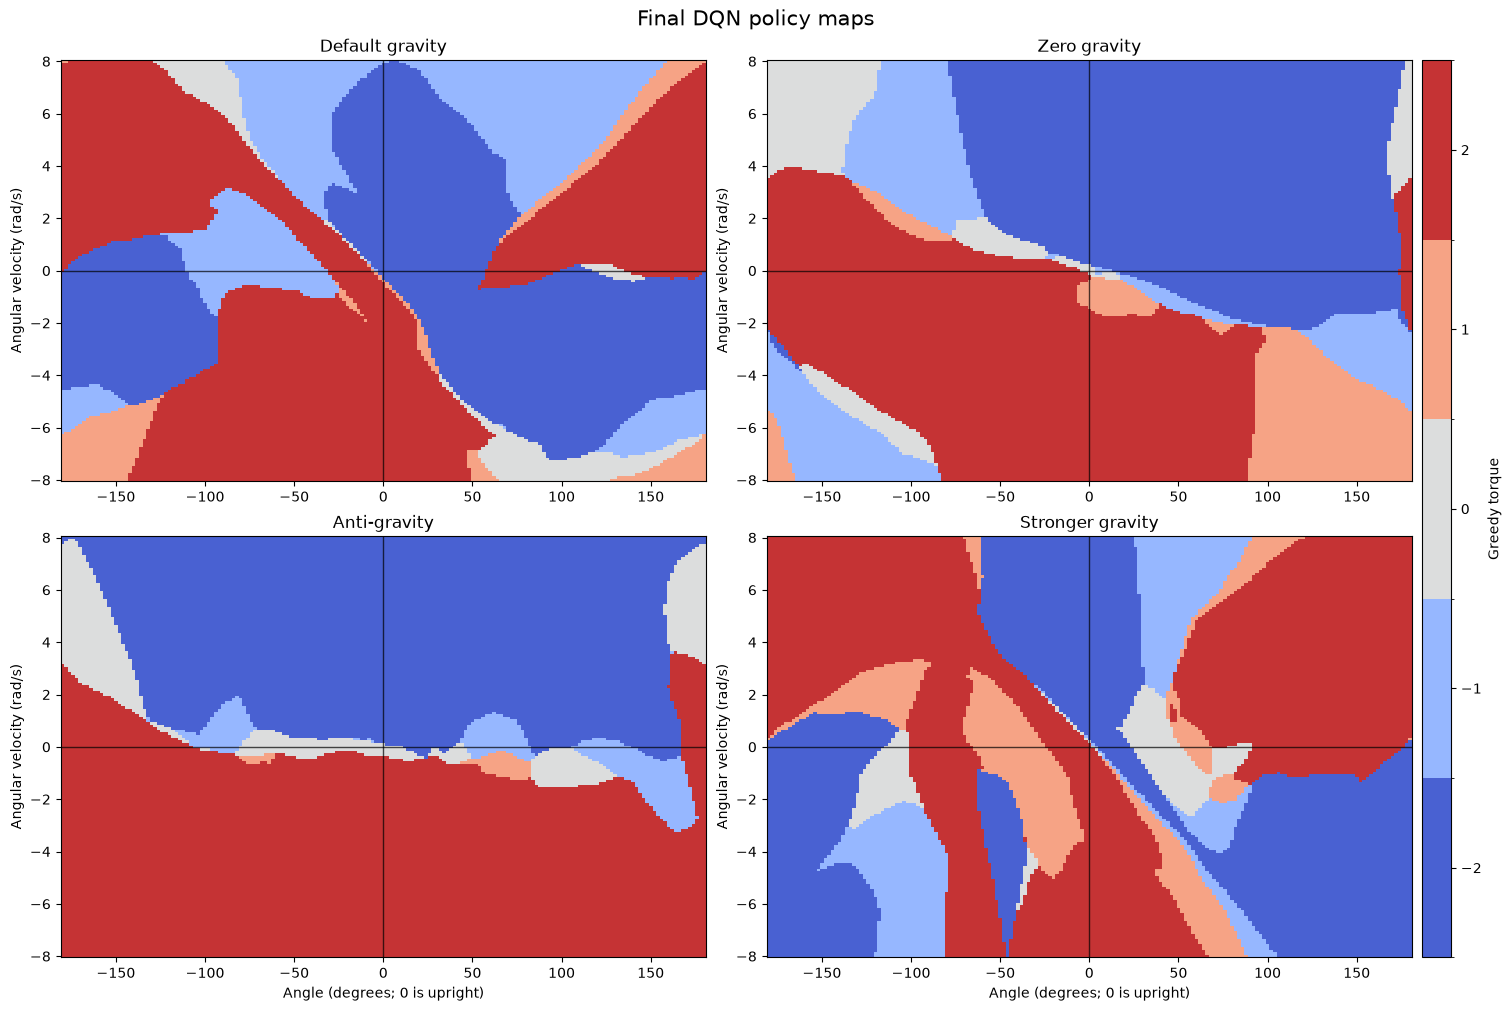

In [32]:
from matplotlib.colors import BoundaryNorm, ListedColormap

theta_degrees_grid = np.linspace(-180.0, 180.0, 181)
angular_velocity_grid = np.linspace(-8.0, 8.0, 161)
theta_mesh, velocity_mesh = np.meshgrid(
    np.deg2rad(theta_degrees_grid), angular_velocity_grid
)
heatmap_states = np.column_stack([
    np.cos(theta_mesh.ravel()),
    np.sin(theta_mesh.ravel()),
    velocity_mesh.ravel() / 8.0,
]).astype(np.float32)

n_final_actions = len(final_action_values)
torque_spacing = float(final_action_values[1] - final_action_values[0])
torque_colours = ListedColormap(
    plt.cm.coolwarm(np.linspace(0.05, 0.95, n_final_actions))
)
torque_boundaries = np.linspace(
    final_action_values[0] - torque_spacing / 2,
    final_action_values[-1] + torque_spacing / 2,
    n_final_actions + 1,
)
torque_norm = BoundaryNorm(torque_boundaries, torque_colours.N)

fig = plt.figure(figsize=(15, 10), constrained_layout=True)
grid = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.045])
axes = np.array([
    [fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])],
    [fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])],
])
colour_bar_axis = fig.add_subplot(grid[:, 2])

for axis, gravity_label in zip(axes.flat, FINAL_GRAVITY_SPECS):
    selected_row = selected_models_df.loc[
        selected_models_df["gravity_label"] == gravity_label
    ].iloc[0]
    model = build_q_network(
        FINAL_SELECTED_CONFIG["n_actions"],
        tuple(FINAL_SELECTED_CONFIG["hidden_units"]),
    )
    model.load_weights(WEIGHTS_DIR / selected_row["source_weight_file"])
    action_ids = np.argmax(model(heatmap_states, training=False).numpy(), axis=1)
    selected_torques = final_action_values[action_ids].reshape(theta_mesh.shape)

    image = axis.pcolormesh(
        theta_degrees_grid,
        angular_velocity_grid,
        selected_torques,
        shading="auto",
        cmap=torque_colours,
        norm=torque_norm,
    )
    axis.axvline(0, color="black", linewidth=1, alpha=0.7)
    axis.axhline(0, color="black", linewidth=1, alpha=0.7)
    axis.set(title=gravity_label, ylabel="Angular velocity (rad/s)")

for axis in axes[-1]:
    axis.set_xlabel("Angle (degrees; 0 is upright)")
colour_bar = fig.colorbar(image, cax=colour_bar_axis, ticks=final_action_values)
colour_bar.set_label("Greedy torque")
fig.suptitle("Final DQN policy maps", fontsize=15)
plt.savefig(
    FIGURES_DIR / "final_policy_heatmaps.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

## 14.2 Policy-Map Interpretation

The colour bar labels the five actual torques (`-2`, `-1`, `0`, `1`, `2`). Zero and anti-gravity form broad regions divided mainly by angular velocity, whereas default and stronger gravity have more curved, angle-dependent boundaries. Large red and dark-blue regions show that the exported policies genuinely use the torque limits over much of the state plane, consistent with the action-use diagnostics rather than a plotting artefact.

Near the upright centre, narrow changes between torque regions are consistent with the frequent action switching observed in the traces. I do not convert this map into a score because the grid weights frequently and rarely visited states equally.


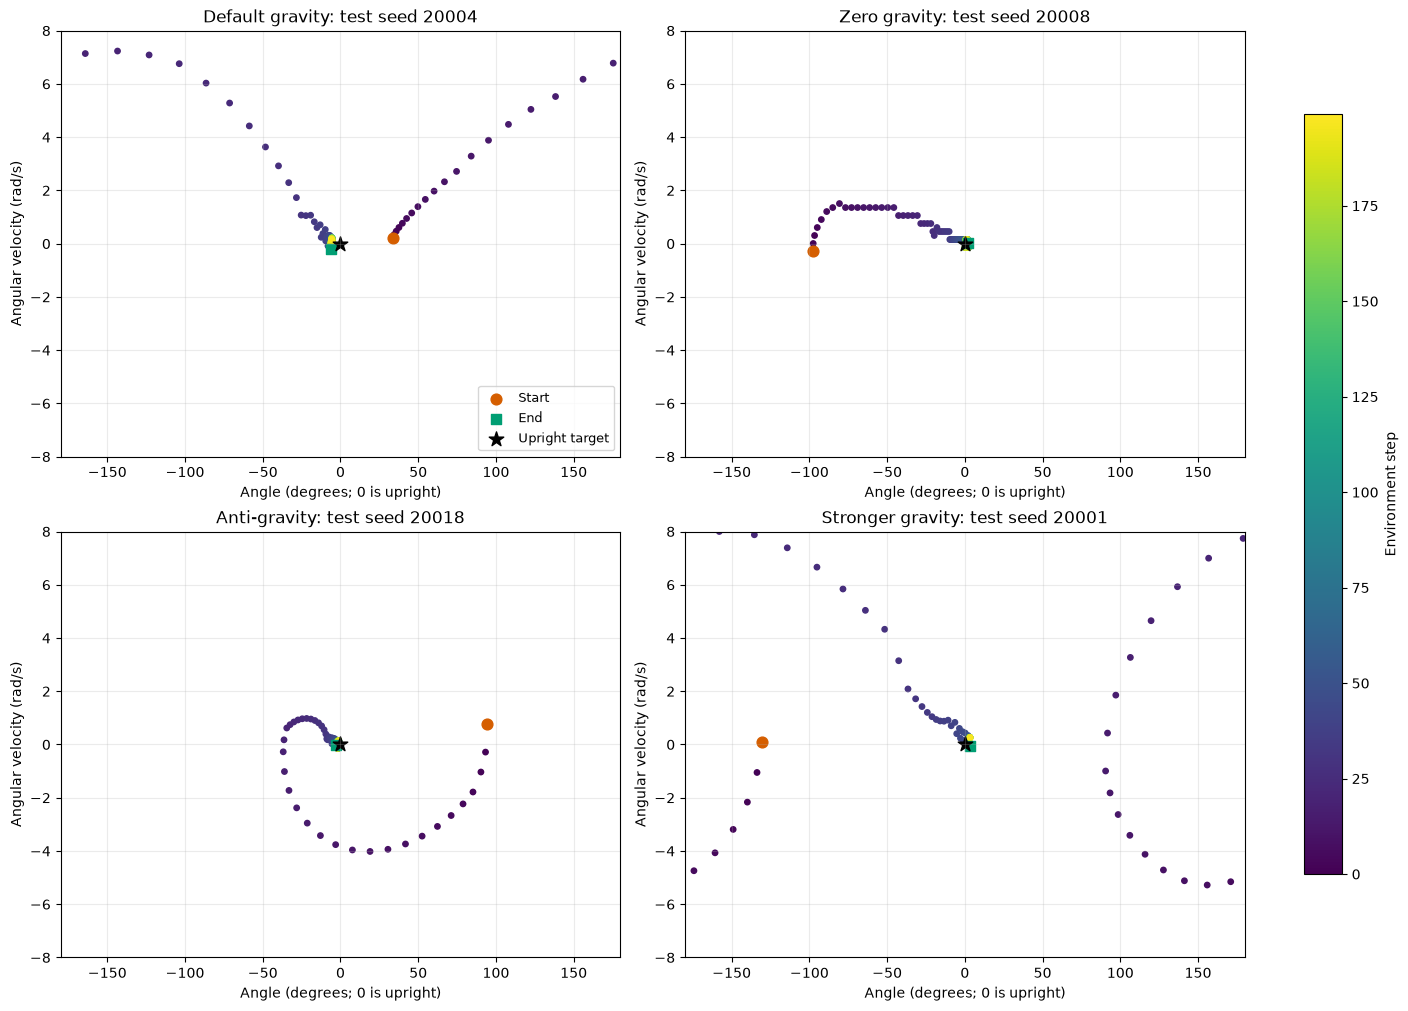

   evaluation_seed  episode_reward  environment_steps  displayed_frames  \
0            20004         -130.12                200               100   
1            20008          -38.59                200               100   
2            20018          -36.20                200               100   
3            20001         -217.31                200               100   

                                   animation_file     gravity_label  \
0   final_test_default_gravity_representative.gif   Default gravity   
1      final_test_zero_gravity_representative.gif      Zero gravity   
2      final_test_anti_gravity_representative.gif      Anti-gravity   
3  final_test_stronger_gravity_representative.gif  Stronger gravity   

   first_stable_step  final_50_stable_fraction  \
0                 35                       1.0   
1                 31                       1.0   
2                 28                       1.0   
3                 37                       1.0   

   representative

<IPython.core.display.HTML object>

<IPython.core.display.HTML object>

<IPython.core.display.HTML object>

<IPython.core.display.HTML object>

In [33]:
representative_test_rows = []
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
last_scatter = None

for axis, gravity_label in zip(axes.flat, FINAL_GRAVITY_SPECS):
    selected_row = selected_models_df.loc[
        selected_models_df["gravity_label"] == gravity_label
    ].iloc[0]
    selected_seed = int(selected_row["selected_training_seed"])
    selected_episodes = final_test_episodes_df.loc[
        (final_test_episodes_df["gravity_label"] == gravity_label)
        & (final_test_episodes_df["training_seed"] == selected_seed)
    ]
    median_reward = selected_episodes["episode_reward"].median()
    representative_episode = (
        selected_episodes.assign(
            distance_from_median=(
                selected_episodes["episode_reward"] - median_reward
            ).abs().round(10)
        )
        .sort_values(["distance_from_median", "evaluation_seed"])
        .iloc[0]
    )
    evaluation_seed = int(representative_episode["evaluation_seed"])
    representative_trace = final_test_traces_df.loc[
        (final_test_traces_df["gravity_label"] == gravity_label)
        & (final_test_traces_df["training_seed"] == selected_seed)
        & (final_test_traces_df["evaluation_seed"] == evaluation_seed)
    ].sort_values("step")

    last_scatter = axis.scatter(
        representative_trace["theta_degrees"],
        representative_trace["theta_dot"],
        c=representative_trace["step"],
        cmap="viridis",
        s=15,
    )
    first_row = representative_trace.iloc[0]
    last_row = representative_trace.iloc[-1]
    axis.scatter(
        first_row["theta_degrees"],
        first_row["theta_dot"],
        s=60,
        color="#D55E00",
        label="Start",
    )
    axis.scatter(
        last_row["theta_degrees"],
        last_row["theta_dot"],
        marker="s",
        s=60,
        color="#009E73",
        label="End",
    )
    axis.scatter(0, 0, marker="*", s=120, color="black", label="Upright target")
    axis.set(
        title=f"{gravity_label}: test seed {evaluation_seed}",
        xlim=(-180, 180),
        ylim=(-8, 8),
        xlabel="Angle (degrees; 0 is upright)",
        ylabel="Angular velocity (rad/s)",
    )
    axis.grid(alpha=0.25)

    specification = FINAL_GRAVITY_SPECS[gravity_label]
    model = build_q_network(
        FINAL_SELECTED_CONFIG["n_actions"],
        tuple(FINAL_SELECTED_CONFIG["hidden_units"]),
    )
    model.load_weights(WEIGHTS_DIR / selected_row["source_weight_file"])
    animation_path = ANIMATIONS_DIR / (
        f"final_test_{specification['export_slug'].lower()}_representative.gif"
    )
    animation_record = save_policy_animation(
        model,
        specification["gravity"],
        final_action_values,
        evaluation_seed,
        animation_path,
        FINAL_SELECTED_CONFIG["max_steps"],
        frame_stride=2,
    )
    assert np.isclose(
        animation_record["episode_reward"],
        representative_episode["episode_reward"],
        atol=1e-6,
    )
    stable_steps = representative_trace.loc[representative_trace["stable"], "step"]
    animation_record.update({
        "gravity_label": gravity_label,
        "first_stable_step": int(stable_steps.iloc[0]) if not stable_steps.empty else np.nan,
        "final_50_stable_fraction": representative_trace.tail(50)["stable"].mean(),
        "representative_mean_abs_angle_degrees": representative_trace["theta_degrees"].abs().mean(),
        "gravity": specification["gravity"],
        "training_seed": selected_seed,
        "weight_file": selected_row["source_weight_file"],
    })
    representative_test_rows.append(animation_record)

axes[0, 0].legend(loc="lower right", fontsize=9)
colour_bar = fig.colorbar(last_scatter, ax=axes, shrink=0.82)
colour_bar.set_label("Environment step")
plt.savefig(
    FIGURES_DIR / "final_test_phase_trajectories.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

representative_test_df = pd.DataFrame(representative_test_rows)
representative_test_df.to_csv(
    TABLES_DIR / "final_test_demonstrations.csv", index=False
)
display(representative_test_df.round(2))

for row in representative_test_df.itertuples():
    display_gif(
        ANIMATIONS_DIR / row.animation_file,
        f"Representative final-test DQN policy under {row.gravity_label.lower()}",
    )

## 14.3 Trajectory and Demonstration Analysis

Colour progresses from early purple points to late yellow points. Default and stronger gravity make large swing-up arcs, cross the angle wrap and then contract towards `(0, 0)`. Zero gravity follows a much smaller path, while anti-gravity follows a distinct loop before settling, consistent with its reversed dynamics. Every green end marker lies close to the upright target.

Representative rewards are `-130.12`, `-38.59`, `-36.20` and `-217.31`, selected nearest each exported model's final-test median. The episodes first enter the upright-and-slow region at steps `35`, `31`, `28` and `37`; all remain in that region for `100%` of their final 50 steps. Stronger gravity takes longest to settle and has the largest representative cost.

The demonstrations visualise these recorded trajectories but do not replace the 60 final episodes used for each gravity's numerical result.


# 15. H5 Export

For each gravity, I copy the checkpoint selected by comparison-validation reward to a clear submission filename. I then load each file into a new `3 -> 64 -> 64 -> 5` network and rerun final-test seed `20000`.

Only the online Q-network weights are exported. The target network, optimiser and replay memory are needed for training, not for greedy inference.


In [34]:
import shutil

verification_rows = []
for selected_row in selected_models_df.itertuples():
    specification = FINAL_GRAVITY_SPECS[selected_row.gravity_label]
    source_path = WEIGHTS_DIR / selected_row.source_weight_file
    export_path = Path(
        f"Part_B_{specification['export_slug']}_Best.weights.h5"
    )
    shutil.copy2(source_path, export_path)

    export_model = build_q_network(
        FINAL_SELECTED_CONFIG["n_actions"],
        tuple(FINAL_SELECTED_CONFIG["hidden_units"]),
    )
    export_model.load_weights(export_path)
    replay_episode, _ = evaluate_dqn(
        export_model,
        specification["gravity"],
        final_action_values,
        [FINAL_TEST_SEEDS[0]],
        FINAL_SELECTED_CONFIG["max_steps"],
    )
    recorded_reward = final_test_episodes_df.loc[
        (final_test_episodes_df["gravity_label"] == selected_row.gravity_label)
        & (final_test_episodes_df["training_seed"] == selected_row.selected_training_seed)
        & (final_test_episodes_df["evaluation_seed"] == FINAL_TEST_SEEDS[0]),
        "episode_reward",
    ].iloc[0]
    reward_difference = abs(
        replay_episode["episode_reward"].iloc[0] - recorded_reward
    )

    verification_rows.append({
        "gravity_label": selected_row.gravity_label,
        "selected_training_seed": selected_row.selected_training_seed,
        "comparison_validation_mean_reward": selected_row.validation_mean_reward,
        "export_weight_file": export_path.name,
        "test_seed_20000_reward_difference": reward_difference,
        "model_parameters": export_model.count_params(),
    })

final_h5_verification_df = pd.DataFrame(verification_rows)
assert final_h5_verification_df[
    "test_seed_20000_reward_difference"
].max() <= 1e-6
assert final_h5_verification_df["export_weight_file"].str.endswith(
    ".weights.h5"
).all()

final_h5_verification_df.to_csv(
    TABLES_DIR / "final_h5_verification.csv", index=False
)
display(final_h5_verification_df.round(8))
print("All four exported H5 files reproduced their recorded policy reward.")

      gravity_label  selected_training_seed  \
0   Default gravity                      17   
1      Zero gravity                      42   
2      Anti-gravity                      17   
3  Stronger gravity                      73   

   comparison_validation_mean_reward  \
0                        -146.655369   
1                         -34.431331   
2                         -39.189912   
3                        -171.989750   

                                 export_weight_file  \
0   Part_B_Default_Gravity_Best.weights.h5   
1      Part_B_Zero_Gravity_Best.weights.h5   
2      Part_B_Anti_Gravity_Best.weights.h5   
3  Part_B_Stronger_Gravity_Best.weights.h5   

   test_seed_20000_reward_difference  model_parameters  
0                                0.0              4741  
1                                0.0              4741  
2                                0.0              4741  
3                                0.0              4741  

All four exported H5 files reproduced their recorded policy reward.


## 15.1 Reload Result

The exported default, zero, anti- and stronger-gravity files use training seeds `17`, `42`, `17` and `73`. Each contains `4,741` parameters, is `37,480` bytes, and reproduces final-test seed `20000` with reward difference `0.00000000` after loading into a new network.

The H5 files therefore recover the reported policies exactly when used with `build_q_network()` and `prepare_state()`.


# 16. Limitations and Conclusion

## 16.1 Limitations

- **Three training seeds:** sufficient to reveal large instability, but not enough for a strong inferential test. Individual seed means and spread are reported instead of p-values.
- **Repeated validation use:** checkpoint and comparison starts are separated, but the comparison set supports several sequential decisions. Final means are `5.71` to `11.30` points below validation, so some selection optimism remains.
- **Controlled alternatives:** 11 actions slightly improve mean reward and physical precision, while reward scaling improves optimisation stability. Neither is consistent enough to replace the five-action baseline.
- **Experiment sequence:** epsilon decay and Double DQN were tested on the provisional 11-action model before the final trade-off returned to five actions. Their rejection therefore applies to that 11-action parent under this budget; they were not retested on the final five-action model.
- **Gradient scale:** clipping affects `62.5%` of baseline updates. Scaling removes clipping but improves mean reward by only `0.53`, showing that smoother optimisation alone does not establish better control.
- **Discrete control:** five torques approximate a continuous action. The result supports five among the tested grids and budget, not as a universal optimum.
- **Equal gravity budget:** one configuration makes the four-gravity comparison fair, but the stronger-gravity curve is still rising near episode 150 and may benefit from separate tuning or longer training.
- **Scope:** conclusions apply to Gym `0.17.3`, the four tested gravity values, the fixed torque limits, 150 episodes and the declared starts.

## 16.2 Conclusion

- The five-action baseline reaches `-148.47` validation reward with `2.58` between-seed spread and exceeds both non-learning controls by more than one thousand points.
- Eleven actions raises the mean by `1.86` and reduces angle error, but increases seed spread, switching and parameters. Forty-one actions regresses all three seeds, so the final trade-off favours five actions.
- On the provisional 11-action parent, linear epsilon decay reaches `-148.86` and improves one seed, while Double DQN falls to `-162.06` with much larger spread. Neither replaces ordinary DQN in that comparison.
- Reward scaling removes gradient clipping and reduces spread to `1.33`, but its `0.53` mean gain is not consistent across all seeds.
- A 300-episode default-gravity extension is not run because only one seed selects episode 150 and mean checkpoint reward does not improve from episode 125 to 150.
- Held-out final means are `-159.55`, `-41.40`, `-49.73` and `-188.63` for default, zero, anti- and stronger gravity. Every setting remains far above random and zero-torque controls, and each representative policy reaches and maintains upright control.

The selected model is the original `3 -> 64 -> 64 -> 5` DQN with constant `epsilon = 0.10`, trained for 150 episodes. None of the tested alternatives improves consistently enough across the three seeds to justify replacing it.


# 17. References

1. Mnih, V. et al. (2015). [Human-level control through deep reinforcement learning](https://www.nature.com/articles/nature14236). *Nature, 518*, 529-533.
2. Sutton, R. S. and Barto, A. G. (2018). [Reinforcement Learning: An Introduction, second edition](http://incompleteideas.net/book/the-book-2nd.html). MIT Press.
3. Farama Foundation. [Pendulum environment documentation](https://gymnasium.farama.org/environments/classic_control/pendulum/). State, action, reward and episode definitions.
4. Pardo, F. et al. (2018). [Time Limits in Reinforcement Learning](https://arxiv.org/abs/1712.00378). Correct treatment of time-limit truncation.
5. Henderson, P. et al. (2018). [Deep Reinforcement Learning that Matters](https://ojs.aaai.org/index.php/AAAI/article/view/11694). Repeated-run evaluation and reporting.
6. Stable-Baselines3. [Reinforcement Learning Tips and Tricks](https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html). Separate test environments, multiple runs and deterministic evaluation.
7. OpenAI. [OpenAI Baselines: DQN](https://openai.com/index/openai-baselines-dqn/). Implementation details affecting DQN results, including error clipping and exploration schedules.
8. Keras. [Weights-only saving and loading](https://keras.io/api/models/model_saving_apis/weights_saving_and_loading/). H5 weight export and identical-topology reconstruction.
9. TensorFlow. [Deterministic operations](https://www.tensorflow.org/api_docs/python/tf/config/experimental/enable_op_determinism). Deterministic operation and seed requirements.
10. Schaul, T. et al. (2016). [Prioritized Experience Replay](https://arxiv.org/abs/1511.05952). Relevant replay alternative considered but not added to the baseline.
11. van Hasselt, H., Guez, A. and Silver, D. (2016). [Deep Reinforcement Learning with Double Q-learning](https://arxiv.org/abs/1509.06461). Maximum-Q overestimation and Double DQN.
12. Wang, Z. et al. (2016). [Dueling Network Architectures for Deep Reinforcement Learning](https://arxiv.org/abs/1511.06581). Architecture alternative considered but deferred.
13. Kingma, D. P. and Ba, J. (2015). [Adam: A Method for Stochastic Optimization](https://arxiv.org/abs/1412.6980). Optimiser used in the baseline.
14. Lillicrap, T. P. et al. (2016). [Continuous Control with Deep Reinforcement Learning](https://arxiv.org/abs/1509.02971). Continuous-action alternative excluded by the required DQN scope.
15. Haarnoja, T. et al. (2018). [Soft Actor-Critic](https://arxiv.org/abs/1801.01290). Continuous-action alternative excluded by the required DQN scope.


16. Singapore Polytechnic (2026). *ST1504 Deep Learning Assignment 2*.
17. Singapore Polytechnic (2026). *ST1504 Deep Learning CA2 Guidance Document*.
18. Singapore Polytechnic (2026). *CA2 Part B - Reinforcement Learning*.
19. Singapore Polytechnic (2026). *ST1504 Topic 6: Deep Reinforcement Learning*.
20. Singapore Polytechnic (2026). *ST1504 DELE Practical 6* and the supplied Pendulum DQN sample notebook.
